# Predicción de deforestación con Swin UNETR / SegFormer (segmentación + clasificación por parche)
**MIA-203 Redes Neuronales y Aprendizaje Profundo — UNI FIIS · Examen Final**

Dataset: `Dataset_deforestacion` (Kaggle, carpeta `unet_dataset`), con arreglos NumPy por partición:
`*_X.npy` (parches de 37 capas geoespaciales: pérdida histórica, bosque, lluvia, topografía, protección, accesibilidad OSM/MTC y MapBiomas), `*_Y.npy` (máscara de pérdida de bosque), `*_M.npy` (máscara de píxeles válidos), además de `meta.json`, `normalizacion.npz` y `muestras.csv`.

**Planteamiento.** Se entrenan **dos modelos 2D independientes basados en Vision Transformers jerárquicos**, con particiones comunes:
- **Swin UNETR** (`"swin_unetr"`, Hatamizadeh et al., 2022): encoder **Swin Transformer** (auto-atención en **ventanas locales desplazadas** y *patch merging* jerárquico) conectado por *skip connections* con bloques residuales a un decoder convolucional.
- **SegFormer** (`"segformer"`, Xie et al., 2021): encoder **Mix Transformer** (*overlapping patch embedding*, **atención eficiente con reducción espacial** y **Mix-FFN** sin codificación posicional) y un **decoder all-MLP** ligero que fusiona las 4 escalas.

La red produce el **mapa de pérdida píxel a píxel** a partir de todas las capas de entrada (bosque, lluvia, topografía, accesibilidad, MapBiomas…), y una cabeza auxiliar clasifica el parche: *deforestación* si la fracción de píxeles válidos con pérdida alcanza o supera `FRAC_THRESHOLD`. Se generan las **predicciones sobre `val`**. Ambas arquitecturas recorren las secciones 5–14: entrenamiento, evaluación, líneas base, ablaciones, interpretabilidad, costo y exportación. Se comparan con el mismo protocolo.

| Requisito | Dónde se cubre |
|---|---|
| **R1** Fundamento en el curso | §4 Vision Transformers jerárquicos (atención por ventanas desplazadas / atención con reducción espacial), decoders de segmentación; pérdida multitarea (BCE + Dice + CE) formulada |
| **R2** Originalidad | Datos de deforestación del Perú con capas geoespaciales multifuente; Transformers jerárquicos adaptados a 31–37 capas; comparación controlada Swin UNETR vs. SegFormer; modelo multitarea |
| **R3** Línea base | §8 Random Forest y regresión logística con estadísticos por banda |
| **R4** Experimentación | §9 Ablaciones con varias semillas (media ± d.e.): arquitectura alternativa, mecanismo de atención (ventanas desplazadas / reducción espacial), capacidad, pérdida de segmentación, aumentos |
| **R5** Interpretación | §10 Mapas de segmentación y Grad-CAM vs. máscara real (pointing game, IoU), prueba de borrado, calibración, t-SNE, errores vs. fracción de pérdida |
| **R6** Costo y responsabilidad | §11 Hardware, horas de GPU, energía y CO₂; §13 limitaciones, sesgos y riesgos |

> **Sin fuga de datos.** `val` y `test` del dataset **nunca** se usan para decidir épocas, hiperparámetros ni variantes. La selección de modelo usa una **validación interna** extraída de `train`.

**En Kaggle** (*Settings*): **Accelerator → GPU T4**. La red se entrena desde cero (no requiere Internet). Las salidas quedan en `/kaggle/working`.
**Modo completo en segundo plano.** Selecciona GPU T4, activa Internet y conecta Dataset_deforestacion. Ejecuta con **Save Version → Save & Run All (Commit)**. Todos los análisis están activados; las ablaciones representan 42 entrenamientos adicionales y la ejecución puede durar varias horas. La cuota de GPU disponible y el límite de sesión deben alcanzar.

**Organización.** Cada sección conserva su propósito original y muestra resultados separados para Swin UNETR y SegFormer. Cada ejecución crea carpetas y JOBLIB únicos. El experimento MLflow `Deforestacion_Transformers_Equipo7` no reemplaza los runs anteriores.


## 0. Parámetros
Ejecución completa: hasta 10 épocas por modelo principal, lote de 4, líneas base activadas, ablaciones de 5 épocas × 3 semillas por variante, interpretabilidad y benchmark. Los controles `RUN_*` se establecen aquí una sola vez, antes del Commit.


In [1]:
from pathlib import Path

# ===================== PARÁMETROS =====================
DATA_DIR = Path("/kaggle/input/datasets/gerardobarzola/dataset-deforestacion/unet_dataset")

# --- Arquitectura: Swin UNETR / SegFormer ---
ARCH_TYPE     = "swin_unetr"   # "swin_unetr" o "segformer"
# Swin UNETR
SWIN_FEATURE  = 24             # canales tras el patch embedding (24 → 48 → 96 → 192 → 384)
SWIN_DEPTHS   = [2, 2, 2, 2]   # bloques Swin por etapa
SWIN_HEADS    = [3, 6, 12, 24] # cabezas de atención por etapa
SWIN_WINDOW   = 8              # tamaño de ventana (en tokens)
# SegFormer (configuración tipo MiT-B0)
SEGF_DIMS     = [32, 64, 160, 256]
SEGF_HEADS    = [1, 2, 5, 8]
SEGF_DEPTHS   = [2, 2, 2, 2]
SEGF_SR       = [8, 4, 2, 1]   # razón de reducción espacial de K y V en la atención eficiente
SEGF_DEC_DIM  = 256            # dimensión del decoder all-MLP
# comunes
DROP_PATH     = 0.1            # stochastic depth en los bloques Transformer
USE_DICE      = True           # añadir el término Dice a la BCE de segmentación
SEG_LOSS_WEIGHT = 1.0          # peso de la pérdida de segmentación frente a la de clasificación
GRAD_CLIP     = 1.0            # recorte de la norma del gradiente

# --- Modelo principal ---
EPOCHS          = 10         # número de épocas (configurable, se puede empezar con 10)
BATCH_SIZE      = 4
LR              = 5e-4      # los Transformers entrenados desde cero son más estables con LR moderada
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.1
DROPOUT         = 0.3
WARMUP_EPOCHS   = 1
PATIENCE        = 5         # early stopping sobre F1-macro (por parche) de la validación interna
AUGMENT         = True
USE_CLASS_WEIGHTS = True
SEED            = 42

# --- Etiqueta por parche (a partir de la máscara Y) ---
FRAC_THRESHOLD    = 0.05    # parche = "deforestacion" si (píxeles con pérdida / píxeles válidos) >= umbral
MASK_POSITIVE_MIN = 0.5     # un píxel de Y cuenta como pérdida si Y > este valor
USE_VALID_MASK    = True    # usar *_M.npy como máscara de píxeles válidos

# --- Bandas ---
USE_ALL_BANDS = True        # True: usa todas las bandas; False: solo RGB
RGB_IDX       = None        # índices de [R, G, B] en X, p. ej. [2, 1, 0]; None = autodetectar (meta.json / normalizacion.npz)
EXCLUDE_BAND_PATTERNS = ["pérdida", "perdida", "loss"]   # bandas que NO entran al modelo (evita fuga si X contiene la propia etiqueta); [] = usar todas
DISPLAY_BAND  = None        # banda para visualizar parches si no hay RGB (None = "bosque remanente" si existe)

# --- Particiones y experimentos ---
INTERNAL_VAL_FRACTION = 0.15
GROUP_INTERNAL_VAL    = True   # validación interna agrupada por ubicación (muestras.csv): las copias aumentadas de un parche no se reparten entre train y val interna
GROUP_BLOCK_PX        = 256    # tamaño del bloque espacial (en píxeles de la grilla fila/col) para agrupar parches vecinos
REMOVE_DUPLICATES     = True
RUN_BASELINES   = True
RUN_ABLATIONS   = True
ABLATION_EPOCHS = 5
ABLATION_SEEDS  = [42, 123, 2024]   # reduce a [42] si falta tiempo de GPU
GRADCAM_FIDELITY_SAMPLES = 64
GRADCAM_LOC_SAMPLES      = 200

# --- Costo computacional ---
GPU_POWER_W         = 70     # TDP NVIDIA T4 (W)
GRID_KG_CO2_PER_KWH = 0.25   # factor de emisión; ajústalo y cita la fuente

NUM_WORKERS = 2
WORK_DIR    = "/kaggle/working"
OUT_DIR     = "results"
CKPT_DIR    = "checkpoints"
print("Celda ejecutada correctamente")
print("Épocas:", EPOCHS, "| Tamaño de lote:", BATCH_SIZE)
# Ejecución completa de las dos arquitecturas, sin pasos manuales.
ARCHITECTURES = ["swin_unetr", "segformer"]
RUN_INTERPRETABILITY = True
RUN_COST_BENCHMARK = True
RUN_MLFLOW = True
MLFLOW_EXPERIMENT = "Deforestacion_Transformers_Equipo7"
MLFLOW_ARTIFACT_PREFIX = "modelos_transformers"


Celda ejecutada correctamente
Épocas: 10 | Tamaño de lote: 4


## 1. Entorno, semillas y utilidades

In [2]:
CONFIG = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
          if k.isupper() and isinstance(v, (int, float, str, bool, list, type(None), Path))}

import os, sys, json, time, copy, math, random, hashlib, platform, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, matthews_corrcoef, cohen_kappa_score,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve,
                             average_precision_score)

warnings.filterwarnings("ignore", category=UserWarning)
_trapz = getattr(np, "trapezoid", None) or np.trapz

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(SEED)

WORK = Path(WORK_DIR) if Path(WORK_DIR).exists() else Path.cwd()
os.chdir(WORK)
IN_KAGGLE = Path("/kaggle/input").exists()
OUT = WORK / OUT_DIR
CKPT_DIR = WORK / CKPT_DIR
for sub in ["figures", "tables", "logs"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
(OUT / "config.json").write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False))

COMPUTE_LOG = []
def log_compute(stage, group, seconds):
    COMPUTE_LOG.append(dict(etapa=stage, grupo=group, segundos=seconds, dispositivo=str(DEVICE)))

def savefig(name):
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")

def save_table(df, name, index=False):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index)
    try:
        (OUT / "tables" / f"{name}.tex").write_text(df.to_latex(index=index, float_format="%.4f"))
    except Exception:
        pass

print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print("Entorno:", "Kaggle" if IN_KAGGLE else "local", "| salida en", WORK)
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "sin GPU (será lento)")
assert DEVICE.type == "cuda", "Configura GPU T4 antes de iniciar Save & Run All."


Python 3.13.16 | PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Entorno: Kaggle | salida en /kaggle/working
Dispositivo: cuda | Tesla T4


## 2. Dataset: archivos e inspección
Se leen los `.npy` con `mmap_mode="r"` (no se cargan completos en RAM). La celda muestra forma, tipo y rango de cada arreglo, el contenido de `meta.json`, `normalizacion.npz` y `muestras.csv`.

In [3]:
DATA_DIR = Path(DATA_DIR)
if not (DATA_DIR / "train_X.npy").exists():
    # respaldo: buscar la carpeta que contiene train_X.npy (siguiendo enlaces simbólicos de Kaggle)
    hits = [Path(d) for d, _, f in os.walk("/kaggle/input" if IN_KAGGLE else ".", followlinks=True) if "train_X.npy" in f]
    assert hits, f"No se encontró train_X.npy en {DATA_DIR}. Revisa la ruta en el panel Input."
    DATA_DIR = sorted(hits, key=lambda p: len(p.parts))[0]
print("Datos en:", DATA_DIR)
for p in sorted(DATA_DIR.iterdir()):
    print(f"   {p.name:22s} {p.stat().st_size / 1e6:10.1f} MB")
extra = [p for p in DATA_DIR.parent.iterdir() if p.is_file()]
for p in extra:
    print(f"   ../{p.name:19s} {p.stat().st_size / 1e6:10.1f} MB")

def load_npy(path):
    try:
        return np.load(path, mmap_mode="r")
    except ValueError:
        return np.load(path, allow_pickle=True)

FILES = {p.name.lower(): p for p in DATA_DIR.iterdir()}
def npy_path(split, kind):
    return FILES.get(f"{split}_{kind}.npy".lower())

SPLITS = [s for s in ("train", "val", "test") if npy_path(s, "x") is not None]
print("\nParticiones:", SPLITS)

rows = []
for s in SPLITS:
    for k in ("x", "y", "m"):
        p = npy_path(s, k)
        if p is None: continue
        a = load_npy(p)
        smp = np.asarray(a[:min(len(a), 32)], dtype=np.float64)
        u = np.unique(smp[np.isfinite(smp)])
        rows.append(dict(archivo=p.name, forma=str(a.shape), dtype=str(a.dtype), min=np.nanmin(smp), max=np.nanmax(smp),
                         media=np.nanmean(smp), nan=int(np.isnan(smp).sum()),
                         valores_unicos=str(u[:6]) if u.size <= 6 else f"{u.size}+ valores"))
inspect_df = pd.DataFrame(rows); display(inspect_df); save_table(inspect_df, "inspeccion_arreglos")

META = {}
if (DATA_DIR / "meta.json").exists():
    META = json.load(open(DATA_DIR / "meta.json"))
    for k, v in META.items():
        if isinstance(v, list) and v and isinstance(v[0], dict):
            print(f"meta.json → {k} ({len(v)} elementos):"); display(pd.DataFrame(v))
        else:
            print(f"meta.json → {k}: {json.dumps(v, ensure_ascii=False)[:600]}")
NPZ_INFO = {}
if (DATA_DIR / "normalizacion.npz").exists():
    z = np.load(DATA_DIR / "normalizacion.npz", allow_pickle=True)
    print("\nnormalizacion.npz:")
    for k in z.files:
        v = z[k]
        if v.dtype.kind in "iufb":
            print(f"   {k}: forma={v.shape} valores={np.round(v.ravel()[:10].astype(float), 4).tolist()}")
        else:
            vals = [str(t) for t in v.ravel().tolist()]
            NPZ_INFO[k] = vals                    # p. ej. nombres de bandas
            print(f"   {k}: forma={v.shape} valores={vals[:20]}")
if (DATA_DIR / "muestras.csv").exists():
    MUESTRAS = pd.read_csv(DATA_DIR / "muestras.csv"); print("\nmuestras.csv:", MUESTRAS.shape); display(MUESTRAS.head())
for p in list(DATA_DIR.glob("*.npy")) + list(DATA_DIR.parent.glob("*.npy")):
    if p.name.lower().startswith(("train_", "val_", "test_")): continue
    a = load_npy(p)
    sub = np.asarray(a[tuple(slice(None, None, max(1, n // 200)) for n in a.shape)], dtype=np.float64)  # submuestra, en float64
    print(f"\n{p.name}: forma={a.shape} dtype={a.dtype} min={np.nanmin(sub):.4g} max={np.nanmax(sub):.4g} media≈{np.nanmean(sub):.4g}")

Datos en: /kaggle/input/datasets/gerardobarzola/dataset-deforestacion/unet_dataset
   meta.json                     0.0 MB
   muestras.csv                  1.2 MB
   normalizacion.npz             0.0 MB
   test_M.npy                   23.0 MB
   test_X.npy                 1699.8 MB
   test_Y.npy                   23.0 MB
   train_M.npy                 157.3 MB
   train_X.npy               11639.2 MB
   train_Y.npy                 157.3 MB
   val_M.npy                    23.0 MB
   val_X.npy                  1699.8 MB
   val_Y.npy                    23.0 MB
   ../perdida_frac.npy        1414.3 MB

Particiones: ['train', 'val', 'test']


,archivo,forma,dtype,min,max,media,nan,valores_unicos
0,train_X.npy,"(9600, 37, 128, 128)",float16,-5.312500,51.53125,-0.201496,0,19552+ valores
1,train_Y.npy,"(9600, 1, 128, 128)",uint8,0.000000,1.00000,0.094206,0,[0. 1.]
2,train_M.npy,"(9600, 1, 128, 128)",uint8,0.000000,1.00000,0.916304,0,[0. 1.]
3,val_X.npy,"(1402, 37, 128, 128)",float16,-2.949219,47.37500,0.172364,0,17558+ valores
4,val_Y.npy,"(1402, 1, 128, 128)",uint8,0.000000,1.00000,0.003040,0,[0. 1.]
5,val_M.npy,"(1402, 1, 128, 128)",uint8,0.000000,1.00000,0.784803,0,[0. 1.]
6,test_X.npy,"(1402, 37, 128, 128)",float16,-2.949219,29.62500,0.219434,0,17668+ valores
7,test_Y.npy,"(1402, 1, 128, 128)",uint8,0.000000,1.00000,0.003307,0,[0. 1.]
8,test_M.npy,"(1402, 1, 128, 128)",uint8,0.000000,1.00000,0.784777,0,[0. 1.]


meta.json → canales (37 elementos):


,indice,nombre,grupo,tipo
0,0,pérdida t,pérdida,continuo
1,1,pérdida reciente,pérdida,continuo
2,2,pérdida acumulada,pérdida,continuo
3,3,log dist. pérdida reciente,pérdida,logdist
4,4,log dist. pérdida acumulada,pérdida,logdist
5,5,densidad pérdida reciente,pérdida,continuo
6,6,bosque 2000,bosque,continuo
7,7,bosque remanente t,bosque,continuo
8,8,anomalía Q1,lluvia,continuo
9,9,anomalía Q2,lluvia,continuo


meta.json → in_channels: 37
meta.json → patch: 128
meta.json → splits: {"train": [2015, 2016, 2017, 2018, 2019, 2020], "val": [2021, 2022], "test": [2023, 2024]}
meta.json → n_parches: {"train": 9600, "val": 1402, "test": 1402}
meta.json → copias_train: 2
meta.json → grilla: {"res_grados": 0.0025, "filas": 5979, "columnas": 4731, "oeste": -80.4795324064289, "norte": -0.03889509508897436, "crs": "EPSG:4326"}
meta.json → formato: {"X": "float16 normalizado (C,128,128)", "Y": "uint8 pérdida en t+1", "M": "uint8 celdas que cuentan en la pérdida"}

normalizacion.npz:
   MU: forma=(37,) valores=[0.0018, 0.0052, 0.0244, 2.2086, 1.7877, 0.0054, 0.7958, 0.7714, 11.2082, 10.4582]
   SD: forma=(37,) valores=[0.0194, 0.0368, 0.1033, 1.309, 1.3464, 0.0143, 0.3763, 0.386, 152.3919, 110.9578]
   nombres: forma=(37,) valores=['pérdida t', 'pérdida reciente', 'pérdida acumulada', 'log dist. pérdida reciente', 'log dist. pérdida acumulada', 'densidad pérdida reciente', 'bosque 2000', 'bosque remanente t

,split,t,fila,col,origen,prev_parche,lon,lat,zona_reservada,copia,aumentada,indice
0,train,2015,4428,4305,cerca de pérdida,NaN,-69.715782,-11.110145,False,0,False,0
1,train,2015,3424,2414,cerca de pérdida,NaN,-74.443282,-8.600145,False,0,False,1
2,train,2015,3934,1967,cerca de pérdida,NaN,-75.560782,-9.875145,False,0,False,2
3,train,2015,3408,1945,cerca de pérdida,NaN,-75.615782,-8.560145,False,0,False,3
4,train,2015,2894,1678,cerca de pérdida,NaN,-76.283282,-7.275145,False,0,False,4



perdida_frac.npy: forma=(25, 5979, 4731) dtype=float16 min=0 max=1 media≈0.0006225


## 3. Estructura, etiquetas por parche, particiones y control de fuga
**Etiqueta por parche.** Para el parche $n$ con máscara de pérdida $Y_n$ y máscara de validez $M_n$:
$$f_n = \frac{\sum_{i,j} \mathbb{1}[Y_{n,ij} > 0.5]\, M_{n,ij}}{\max\!\big(1, \sum_{i,j} M_{n,ij}\big)}, \qquad y_n = \mathbb{1}[f_n \ge \tau],$$
con $\tau$ = `FRAC_THRESHOLD`. Si `Y` resultara ser una etiqueta por parche (no una máscara), se usa directamente.

| Partición | Origen | Uso |
|---|---|---|
| `train` | `train_*.npy` (85 %) | ajustar pesos |
| `val interna` | `train_*.npy` (15 %, estratificado) | early stopping y elección de variante |
| **`val`** | `val_*.npy` | **predicciones y métricas principales** |
| `test` | `test_*.npy` | evaluación adicional |

In [4]:
X0 = load_npy(npy_path("train", "x"))
def infer_layout(shape):
    if len(shape) == 3: return "NHW"
    a, b, c = shape[1:]
    if c < a and c < b: return "NHWC"
    if a < b and a < c: return "NCHW"
    return "NHWC"
LAYOUT = infer_layout(X0.shape)
if LAYOUT == "NHWC": H, W, C = X0.shape[1:]
elif LAYOUT == "NCHW": C, H, W = X0.shape[1:]
else: (H, W), C = X0.shape[1:], 1
print(f"Disposición de X: {LAYOUT} | parches {H}x{W} | {C} banda(s)")

# --- nombres de bandas e índices RGB / NIR desde meta.json ---
def find_band_names(obj, n, need_key=True):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if isinstance(v, list) and len(v) == n and all(isinstance(t, str) for t in v) and \
               (not need_key or any(w in k.lower() for w in ("band", "canal", "channel"))):
                return v
        for v in obj.values():
            r = find_band_names(v, n, need_key)
            if r: return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_band_names(v, n, need_key)
            if r: return r
    return None
BAND_GROUPS = None
for v in META.values():
    if isinstance(v, list) and len(v) == C and all(isinstance(t, dict) and "nombre" in t for t in v):
        v = sorted(v, key=lambda t: t.get("indice", 0))
        META_NAMES = [str(t["nombre"]) for t in v]; BAND_GROUPS = [str(t.get("grupo", "otro")) for t in v]
        break
else:
    META_NAMES = None
BAND_NAMES = (META_NAMES or find_band_names(META, C) or find_band_names(NPZ_INFO, C) or find_band_names(META, C, need_key=False)
              or find_band_names(NPZ_INFO, C, need_key=False) or [f"banda_{i}" for i in range(C)])
BAND_NAMES = [str(b) for b in BAND_NAMES]
EXCLUDED = [i for i, n in enumerate(BAND_NAMES) if any(p.lower() in n.lower() for p in EXCLUDE_BAND_PATTERNS)]
if EXCLUDED:
    print("ATENCIÓN: se EXCLUYEN de la entrada las bandas", [BAND_NAMES[i] for i in EXCLUDED],
          "porque su nombre sugiere que contienen la pérdida de bosque (la etiqueta) → evitaría fuga de datos.",
          "Si es información histórica legítima (p. ej. pérdida en un año anterior), pon EXCLUDE_BAND_PATTERNS = [].")

def band_idx(words, codes):
    for i, n in enumerate(BAND_NAMES):
        if i in EXCLUDED: continue
        t = n.lower().replace(" ", "").replace("_", "")
        if any(w in t for w in words) or t in codes or any(t.endswith(c) for c in codes if len(c) > 1):
            return i
    return None
auto_rgb = [band_idx(("red", "rojo"), ("r", "b4", "srb4")),
            band_idx(("green", "verde"), ("g", "b3", "srb3")),
            band_idx(("blue", "azul"), ("b", "b2", "srb2"))]
NIR_IDX = band_idx(("nir", "infrarrojo"), ("b8", "b8a"))
_RGB_USER = RGB_IDX is not None
if RGB_IDX is None:
    if None not in auto_rgb and len(set(auto_rgb)) == 3:
        RGB_IDX = auto_rgb
    else:
        usable = [c for c in range(C) if c not in EXCLUDED]
        RGB_IDX = usable[:3] if len(usable) >= 3 else [usable[0]] * 3
        pass   # sin RGB: se visualiza una banda (DISPLAY_BAND)
CH_ORDER = (list(dict.fromkeys(RGB_IDX)) + [c for c in range(C) if c not in RGB_IDX]) if USE_ALL_BANDS else list(RGB_IDX)
CH_ORDER = [c for c in CH_ORDER if c not in EXCLUDED]
if C < 3: CH_ORDER = [c for c in range(C) if c not in EXCLUDED]
assert CH_ORDER, "Todas las bandas quedaron excluidas; revisa EXCLUDE_BAND_PATTERNS."
C_IN = len(CH_ORDER)
RGB_FOUND = _RGB_USER or (None not in auto_rgb and len(set(auto_rgb)) == 3)
if DISPLAY_BAND is None:
    cand = [i for i, n in enumerate(BAND_NAMES) if "bosque remanente" in n.lower()] or [CH_ORDER[0]]
    DISPLAY_IDX = cand[0]
else:
    DISPLAY_IDX = DISPLAY_BAND if isinstance(DISPLAY_BAND, int) else BAND_NAMES.index(DISPLAY_BAND)
if BAND_GROUPS is None:
    BAND_GROUPS = ["otro"] * C
print("Bandas:", BAND_NAMES)
print("Grupos:", dict(Counter(BAND_GROUPS)))
print("RGB:", [BAND_NAMES[i] for i in RGB_IDX] if RGB_FOUND else "no hay bandas RGB → se visualiza " + repr(BAND_NAMES[DISPLAY_IDX]),
      "| NIR =", BAND_NAMES[NIR_IDX] if NIR_IDX is not None else "no")
print("Orden de entrada a la red:", [BAND_NAMES[i] for i in CH_ORDER], f"({C_IN} canales)")

def to_hw(a):
    a = np.asarray(a)
    if a.ndim == 4:
        if a.shape[1] == 1: a = a[:, 0]
        elif a.shape[-1] == 1: a = a[..., 0]
        elif a.shape[1] < a.shape[-1]: a = a.argmax(1)
        else: a = a.argmax(-1)
    return a.astype(np.float32)

def split_targets(split):
    n = len(load_npy(npy_path(split, "x")))
    yp, mp = npy_path(split, "y"), npy_path(split, "m")
    Y = load_npy(yp) if yp else None
    M = load_npy(mp) if (mp and USE_VALID_MASK) else None
    is_mask = Y is not None and Y.ndim >= 3 and to_hw(Y[:1]).shape[1:] == (H, W)
    if M is not None and not (M.ndim >= 3 and to_hw(M[:1]).shape[1:] == (H, W)):
        print(f"[{split}] M no tiene forma de máscara {H}x{W}; se ignora."); M = None
    frac, valid = np.full(n, np.nan), np.ones(n)
    if is_mask:
        for i0 in range(0, n, 256):
            y = to_hw(Y[i0:i0 + 256]) > MASK_POSITIVE_MIN
            m = (to_hw(M[i0:i0 + 256]) > 0.5) if M is not None else np.ones_like(y)
            frac[i0:i0 + 256] = (y & m).sum((1, 2)) / np.maximum(m.sum((1, 2)), 1)
            valid[i0:i0 + 256] = m.mean((1, 2))
        return dict(kind="mascara", frac=frac, valid=valid)
    y = np.asarray(Y)
    y = y.argmax(1) if y.ndim == 2 and y.shape[1] > 1 else y.reshape(n)
    if np.allclose(y, np.round(y)):
        return dict(kind="clase", labels=y.astype(int), frac=frac, valid=valid)
    return dict(kind="fraccion", frac=y.astype(float), valid=valid)

TGT = {s: split_targets(s) for s in SPLITS}
Y_KIND = TGT["train"]["kind"]
print("Tipo de Y:", Y_KIND)
if Y_KIND == "clase":
    vals = sorted(set(np.concatenate([TGT[s]["labels"] for s in SPLITS]).tolist()))
    CLASSES = [str(META.get("clases", {}).get(str(v), f"clase_{v}")) if isinstance(META.get("clases"), dict) else f"clase_{v}" for v in vals]
    LAB = {s: np.searchsorted(vals, TGT[s]["labels"]) for s in SPLITS}
else:
    CLASSES = ["sin_deforestacion", "deforestacion"]
    LAB = {s: (TGT[s]["frac"] >= FRAC_THRESHOLD).astype(int) for s in SPLITS}
FRAC = {s: TGT[s]["frac"] for s in SPLITS}
VALID = {s: TGT[s]["valid"] for s in SPLITS}
K = len(CLASSES); CLS2IDX = {c: i for i, c in enumerate(CLASSES)}

def samples_of(split):
    return [(split, i, int(LAB[split][i])) for i in range(len(LAB[split]))]

full_train = samples_of("train")
labels_tr = [s[2] for s in full_train]
GROUPS = None
mpath = DATA_DIR / "muestras.csv"
if GROUP_INTERNAL_VAL and mpath.exists():
    mu = pd.read_csv(mpath)
    if {"split", "indice", "fila", "col"} <= set(mu.columns):
        mt = mu[mu.split == "train"].set_index("indice")
        if len(mt) == len(full_train):
            GROUPS = ((mt.loc[[t[1] for t in full_train], "fila"].values // GROUP_BLOCK_PX).astype(int) * 100000 +
                      (mt.loc[[t[1] for t in full_train], "col"].values // GROUP_BLOCK_PX).astype(int))
            if "aumentada" in mt.columns:
                print(f"Parches aumentados en train: {int(mt.aumentada.sum())} de {len(mt)}")
if GROUPS is not None:
    from sklearn.model_selection import StratifiedGroupKFold
    sgk = StratifiedGroupKFold(n_splits=max(2, round(1 / INTERNAL_VAL_FRACTION)), shuffle=True, random_state=SEED)
    tr_i, iv_i = next(sgk.split(np.zeros(len(full_train)), labels_tr, GROUPS))
    train_s, ival_s = [full_train[i] for i in tr_i], [full_train[i] for i in iv_i]
    print(f"Validación interna AGRUPADA por bloques de {GROUP_BLOCK_PX} px: {len(set(GROUPS))} grupos; "
          f"ningún bloque (ni sus copias aumentadas) está a la vez en train y en val interna.")
else:
    strat = labels_tr if min(Counter(labels_tr).values()) >= 2 else None
    train_s, ival_s = train_test_split(full_train, test_size=INTERNAL_VAL_FRACTION, random_state=SEED, stratify=strat)
    print("Validación interna aleatoria estratificada (sin información de ubicación).")
HOLDOUT_NAME = "val" if "val" in SPLITS else "test"
holdout    = samples_of(HOLDOUT_NAME)
extra_test = samples_of("test") if ("test" in SPLITS and HOLDOUT_NAME == "val") else []
print(f"Clases: {CLASSES}")
print(f"train={len(train_s)} | val interna={len(ival_s)} | {HOLDOUT_NAME}={len(holdout)} | test={len(extra_test)}")

Disposición de X: NCHW | parches 128x128 | 37 banda(s)
ATENCIÓN: se EXCLUYEN de la entrada las bandas ['pérdida t', 'pérdida reciente', 'pérdida acumulada', 'log dist. pérdida reciente', 'log dist. pérdida acumulada', 'densidad pérdida reciente'] porque su nombre sugiere que contienen la pérdida de bosque (la etiqueta) → evitaría fuga de datos. Si es información histórica legítima (p. ej. pérdida en un año anterior), pon EXCLUDE_BAND_PATTERNS = [].
Bandas: ['pérdida t', 'pérdida reciente', 'pérdida acumulada', 'log dist. pérdida reciente', 'log dist. pérdida acumulada', 'densidad pérdida reciente', 'bosque 2000', 'bosque remanente t', 'anomalía Q1', 'anomalía Q2', 'anomalía Q3', 'anomalía Q4', 'anomalía anual', 'climatología Q1', 'climatología Q2', 'climatología Q3', 'climatología Q4', 'climatología anual', 'elevación', 'pendiente', 'nivel de protección t', 'dist. firmada a ANP t', 'zona de amortiguamiento', 'log dist. vías principales (OSM)', 'log dist. trochas y vías menores (OSM)', 

In [5]:
# ---- Control de fuga: parches idénticos entre particiones (hash MD5 del arreglo) ----
_MM = {}
def arr(split, kind="x"):
    key = (os.getpid(), split, kind)       # un mmap por proceso (compatible con DataLoader multiproceso)
    if key not in _MM:
        _MM[key] = load_npy(npy_path(split, kind))
    return _MM[key]

t0 = time.time()
HASH = {}
for s in SPLITS:
    A = arr(s)
    for i in range(len(A)):
        HASH[(s, i)] = hashlib.md5(np.ascontiguousarray(A[i]).tobytes()).hexdigest()
h_hold = {HASH[(s, i)] for s, i, _ in holdout + extra_test}
h_ival = {HASH[(s, i)] for s, i, _ in ival_s}
d1 = sum(HASH[(s, i)] in h_hold for s, i, _ in train_s)
d2 = sum(HASH[(s, i)] in h_ival for s, i, _ in train_s)
d3 = sum(HASH[(s, i)] in h_hold for s, i, _ in ival_s)
print(f"Duplicados exactos  train∩val/test: {d1} | train∩val_interna: {d2} | val_interna∩val/test: {d3}")
if REMOVE_DUPLICATES and d1 + d2 + d3:
    train_s = [t for t in train_s if HASH[t[:2]] not in h_hold and HASH[t[:2]] not in h_ival]
    ival_s  = [t for t in ival_s if HASH[t[:2]] not in h_hold]
    print(f"Tras eliminar duplicados: train={len(train_s)} | val interna={len(ival_s)}")
save_table(pd.DataFrame([dict(par="train ∩ val/test", duplicados=d1), dict(par="train ∩ val interna", duplicados=d2),
                         dict(par="val interna ∩ val/test", duplicados=d3)]), "control_fuga_duplicados")
print(f"(hash en {time.time() - t0:.1f}s)")

Duplicados exactos  train∩val/test: 0 | train∩val_interna: 0 | val_interna∩val/test: 0
(hash en 63.7s)


### 3.1 Normalización y análisis exploratorio
Cada banda se estandariza con media y desviación estándar calculadas **solo con `train`** (los NaN se reemplazan por 0 tras estandarizar).

,banda,media,std,p02,p98
0,pérdida t,0.2041,1.7681,-0.0906,4.0391
1,pérdida reciente,0.3258,1.7969,-0.1427,5.8359
2,pérdida acumulada,0.5157,1.7258,-0.2362,6.9258
3,log dist. pérdida reciente,-0.5913,0.7428,-1.6875,0.9810
4,log dist. pérdida acumulada,-0.5535,0.6561,-1.3281,0.8652
5,densidad pérdida reciente,0.8265,1.8505,-0.3735,6.5781
6,bosque 2000,0.1296,0.7933,-2.1152,0.5425
7,bosque remanente t,-0.0101,0.8840,-1.9980,0.5923
8,anomalía Q1,0.1624,1.4102,-2.8926,3.9004
9,anomalía Q2,0.1305,1.2598,-2.2910,3.2969


,train,val interna,val,test
sin_deforestacion,3998,624,1105,1160
deforestacion,4668,310,297,242
TOTAL,8666,934,1402,1402


Razón de desbalance en train: 1.17
Cuantiles 50/75/90/95 % de la fracción: [0.0545 0.1176 0.1669 0.1953] | parches con alguna pérdida: 98.5%


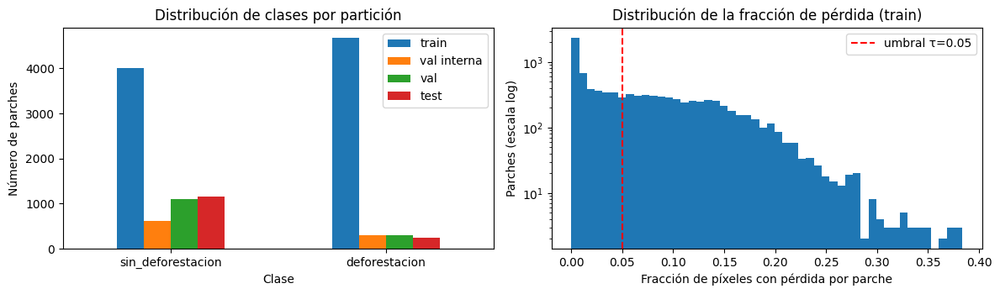

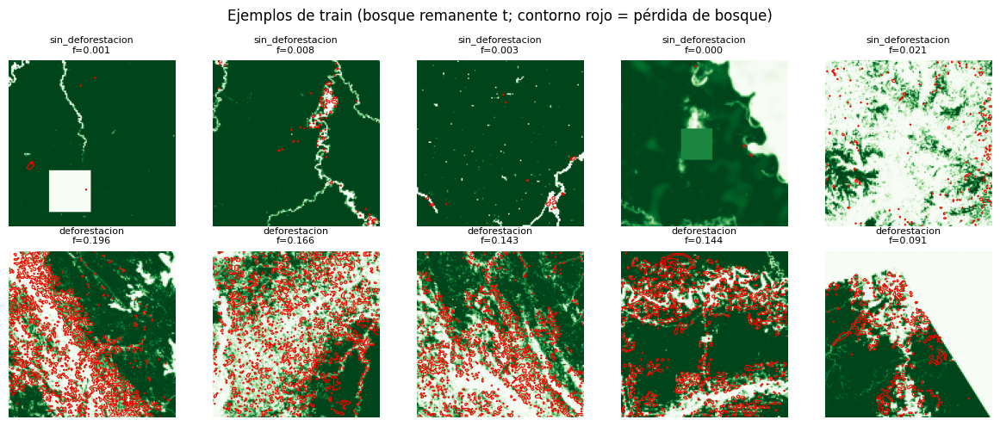

In [6]:
def raw_chw(split, i):
    a = np.asarray(arr(split)[i], dtype=np.float32)
    if LAYOUT == "NHWC": a = a.transpose(2, 0, 1)
    elif LAYOUT == "NHW": a = a[None]
    return a

rng = np.random.RandomState(SEED)
stat_idx = rng.choice(len(train_s), min(500, len(train_s)), replace=False)
stride = max(1, min(H, W) // 64)                                         # submuestreo espacial para ahorrar RAM
stack = np.stack([raw_chw(*train_s[j][:2])[:, ::stride, ::stride] for j in stat_idx])   # (n, C, h, w)
MEAN_ALL = np.nanmean(stack, axis=(0, 2, 3)).astype(np.float32)
STD_ALL  = (np.nanstd(stack, axis=(0, 2, 3)) + 1e-6).astype(np.float32)
RAW_NONNEG = bool(np.nanmin(stack) >= 0)
band_df = pd.DataFrame(dict(banda=BAND_NAMES, media=MEAN_ALL, std=STD_ALL,
                            p02=np.nanpercentile(stack, 2, axis=(0, 2, 3)), p98=np.nanpercentile(stack, 98, axis=(0, 2, 3))))
display(band_df.round(4)); save_table(band_df, "estadisticos_bandas")
del stack

# distribución de clases
parts = {"train": train_s, "val interna": ival_s, HOLDOUT_NAME: holdout}
if extra_test: parts["test"] = extra_test
dist = pd.DataFrame({n: Counter(CLASSES[t[2]] for t in S) for n, S in parts.items()}).reindex(CLASSES).fillna(0).astype(int)
dist.loc["TOTAL"] = dist.sum(); display(dist)
save_table(dist.reset_index().rename(columns={"index": "clase"}), "distribucion_clases")
cnt = Counter(t[2] for t in train_s)
print(f"Razón de desbalance en train: {max(cnt.values()) / max(1, min(cnt.values())):.2f}")
if min(cnt.values()) / len(train_s) < 0.05:
    print("ATENCIÓN: una clase tiene < 5 % de los parches; considera ajustar FRAC_THRESHOLD.")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
dist.drop("TOTAL").plot.bar(ax=ax[0]); ax[0].set_xlabel("Clase"); ax[0].set_ylabel("Número de parches")
ax[0].set_title("Distribución de clases por partición"); ax[0].tick_params(axis="x", rotation=0)
if Y_KIND != "clase":
    ftr = FRAC["train"]
    ax[1].hist(ftr, bins=50, log=True); ax[1].axvline(FRAC_THRESHOLD, c="r", ls="--", label=f"umbral τ={FRAC_THRESHOLD}")
    ax[1].set_xlabel("Fracción de píxeles con pérdida por parche"); ax[1].set_ylabel("Parches (escala log)")
    ax[1].set_title("Distribución de la fracción de pérdida (train)"); ax[1].legend()
    q = np.nanquantile(ftr, [0.5, 0.75, 0.9, 0.95]); print("Cuantiles 50/75/90/95 % de la fracción:", np.round(q, 4),
          f"| parches con alguna pérdida: {(ftr > 0).mean():.1%}")
plt.tight_layout(); savefig("eda_distribucion"); plt.show()

def rgb_image(split, i):
    a = raw_chw(split, i)
    if not RGB_FOUND:
        b = a[DISPLAY_IDX]; lo, hi = np.nanpercentile(b, 2), np.nanpercentile(b, 98)
        g = np.nan_to_num(np.clip((b - lo) / (hi - lo + 1e-8), 0, 1))
        return plt.cm.Greens(g)[..., :3]
    r = a[RGB_IDX]
    lo, hi = np.nanpercentile(r, 2), np.nanpercentile(r, 98)
    return np.nan_to_num(np.clip((r - lo) / (hi - lo + 1e-8), 0, 1)).transpose(1, 2, 0)

def loss_mask(split, i):
    p = npy_path(split, "y")
    if p is None or Y_KIND != "mascara": return None
    return to_hw(arr(split, "y")[i:i + 1])[0] > MASK_POSITIVE_MIN

n_show = 5
fig, axes = plt.subplots(K, n_show, figsize=(2.4 * n_show, 2.5 * K), squeeze=False)
for k in range(K):
    pool = [t for t in train_s if t[2] == k]
    for j, t in enumerate(random.Random(SEED).sample(pool, min(n_show, len(pool)))):
        axes[k, j].imshow(rgb_image(*t[:2]))
        m = loss_mask(*t[:2])
        if m is not None and m.any(): axes[k, j].contour(m, levels=[0.5], colors="red", linewidths=0.8)
        ttl = CLASSES[k] + (f"\nf={FRAC['train'][t[1]]:.3f}" if Y_KIND != "clase" else "")
        axes[k, j].set_title(ttl, fontsize=8)
    for j in range(n_show): axes[k, j].axis("off")
plt.suptitle(f"Ejemplos de train ({'RGB' if RGB_FOUND else BAND_NAMES[DISPLAY_IDX]}; contorno rojo = pérdida de bosque)"); plt.tight_layout(); savefig("eda_ejemplos"); plt.show()

### 3.2 Dataset y aumentos
Los parches no tienen orientación canónica: volteos horizontales/verticales y rotaciones de 90° se aplican **igual a la entrada, a la máscara de pérdida y a la máscara de validez**; un *jitter* suave de ganancia y sesgo se aplica solo a la entrada. Para entrenar, el *DataLoader* entrega también las máscaras (`masks=True`).

In [7]:
assert Y_KIND == "mascara", "El segmentador necesita máscaras de pérdida (Y) por píxel."

def get_masks(split, i):
    ym = (to_hw(arr(split, "y")[i:i + 1])[0] > MASK_POSITIVE_MIN).astype(np.float32)
    if npy_path(split, "m") is not None and USE_VALID_MASK:
        vm = (to_hw(arr(split, "m")[i:i + 1])[0] > 0.5).astype(np.float32)
    else:
        vm = np.ones_like(ym)
    return ym * vm, vm

class NpyDS(Dataset):
    def __init__(self, samples, train=False, augment=True, ch_order=None, masks=False):
        self.samples, self.train, self.augment, self.masks = samples, train, augment, masks
        self.ch = list(ch_order if ch_order is not None else CH_ORDER)
        self.mean = torch.tensor(MEAN_ALL[self.ch])[:, None, None]
        self.std  = torch.tensor(STD_ALL[self.ch])[:, None, None]
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, j):
        s, i, y = self.samples[j]
        x = torch.from_numpy(raw_chw(s, i)[self.ch])
        x = torch.nan_to_num((x - self.mean) / self.std, nan=0.0, posinf=0.0, neginf=0.0)
        if self.masks:
            ym, vm = get_masks(s, i)
            z = torch.cat([x, torch.from_numpy(ym)[None], torch.from_numpy(vm)[None]], 0)
        else:
            z = x
        if self.train and self.augment:
            if torch.rand(1) < 0.5: z = z.flip(-1)
            if torch.rand(1) < 0.5: z = z.flip(-2)
            if z.shape[-1] == z.shape[-2]: z = torch.rot90(z, int(torch.randint(0, 4, (1,))), dims=(-2, -1))
        x = z[:len(self.ch)]
        if self.train and self.augment:
            x = x * (1 + 0.1 * (2 * torch.rand(x.shape[0], 1, 1) - 1)) + 0.1 * (2 * torch.rand(x.shape[0], 1, 1) - 1)
        if self.masks:
            return x.contiguous(), y, j, z[-2:-1].contiguous(), z[-1:].contiguous()
        return x.contiguous(), y, j

def seed_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loader(samples, train, augment=True, seed=SEED, bs=BATCH_SIZE, ch_order=None, masks=False):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(NpyDS(samples, train, augment, ch_order, masks), batch_size=bs, shuffle=train,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      worker_init_fn=seed_worker, generator=g, drop_last=train and len(samples) > bs)

def class_weights_tensor(samples):
    cnt = Counter(t[2] for t in samples); n = len(samples)
    return torch.tensor([n / (K * max(1, cnt.get(k, 0))) for k in range(K)], dtype=torch.float32, device=DEVICE)

xb, yb, _, mb, vb = next(iter(make_loader(train_s, True, masks=True)))
print("Lote:", tuple(xb.shape), "| máscara:", tuple(mb.shape), "| media", round(xb.mean().item(), 3), "| d.e.", round(xb.std().item(), 3),
      f"| píxeles con pérdida en el lote: {mb.sum().item() / vb.sum().clamp(min=1).item():.2%}")
print("Pesos de clase:", dict(zip(CLASSES, class_weights_tensor(train_s).cpu().numpy().round(3))))

Lote: (4, 31, 128, 128) | máscara: (4, 1, 128, 128) | media 0.002 | d.e. 0.922 | píxeles con pérdida en el lote: 8.18%
Pesos de clase: {'sin_deforestacion': np.float32(1.084), 'deforestacion': np.float32(0.928)}


## 4. Modelo: Swin UNETR / SegFormer y formulación matemática (R1)
Ambas arquitecturas son **Vision Transformers jerárquicos**: producen mapas a varias escalas (1/2–1/32) como una CNN, pero cada bloque usa **auto-atención multi-cabeza**,
$$\text{Attn}(Q, K, V) = \text{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_h}} + B\Big)V, \qquad \mathbf{z}' = \mathbf{z} + \text{Attn}(\text{LN}(\mathbf{z})), \qquad \mathbf{z}'' = \mathbf{z}' + \text{FFN}(\text{LN}(\mathbf{z}')).$$
Se diferencian en **cómo hacen manejable** el costo cuadrático de la atención sobre los $N$ *tokens* de alta resolución.

**Swin UNETR.** (i) *Patch embedding* $2\times2$ a `SWIN_FEATURE` canales. (ii) Cuatro etapas Swin: la atención se calcula **dentro de ventanas** de $M\times M$ *tokens* (costo $\mathcal{O}(N M^2)$ en lugar de $\mathcal{O}(N^2)$), con sesgo posicional relativo $B$; bloques alternos **desplazan las ventanas** $\lfloor M/2 \rfloor$ para que la información cruce sus bordes. Entre etapas, *patch merging* concatena vecinos $2\times2$ y duplica canales, generando mapas a 1/4, 1/8, 1/16 y 1/32. (iii) Cada escala (y la entrada) pasa por un bloque residual convolucional $[\text{Conv}_{3\times3}\to\text{IN}\to\text{LReLU}]\times2 + \text{atajo}$, y el decoder sube de escala con convolución transpuesta y concatenación de la *skip* de la misma resolución, como en una U-Net.

**SegFormer.** (i) *Overlapping patch embedding* (convoluciones $7\times7$/s4 y $3\times3$/s2) produce 4 escalas (1/4–1/32) con canales `SEGF_DIMS`. (ii) **Atención eficiente**: $K$ y $V$ se reducen espacialmente con una convolución de paso $R$ (`SEGF_SR`), $\hat K = \text{LN}(\text{Conv}_{R\times R,\,s=R}(K))$, bajando el costo a $\mathcal{O}(N^2/R^2)$. (iii) **Mix-FFN** sin posiciones explícitas: $\text{FFN}(\mathbf{z}) = W_2\,\text{GELU}(\text{DWConv}_{3\times3}(W_1 \mathbf{z}))$; la convolución *depthwise* aporta la información posicional, de modo que la red acepta cualquier tamaño de parche. (iv) **Decoder all-MLP**: cada escala se proyecta a `SEGF_DEC_DIM` canales, se sobremuestrea a 1/4, se concatena y se fusiona con una capa lineal ($1\times1$) antes de predecir y reescalar a la resolución completa.

En ambas, el logit por píxel es $z_{ij}$ y $\hat{p}_{ij} = \sigma(z_{ij})$. El parche se rellena a múltiplo de 32.

**Cabeza de clasificación auxiliar.** $\text{GAP}(\text{mapa más profundo}) \to \text{Dropout}(p) \to \text{Linear}(\cdot, K)$ predice la clase del parche.

**Pérdida multitarea.** Con máscara de pérdida $Y_{ij}$ y de validez $M_{ij}$:
$$\mathcal{L}_{\text{BCE}} = \frac{\sum_{ij} M_{ij}\,\big[-Y_{ij}\log\hat p_{ij} - (1-Y_{ij})\log(1-\hat p_{ij})\big]}{\sum_{ij} M_{ij}}, \qquad
\mathcal{L}_{\text{Dice}} = 1 - \frac{2\sum_{ij} M_{ij}\hat p_{ij} Y_{ij} + 1}{\sum_{ij} M_{ij}\hat p_{ij} + \sum_{ij} M_{ij} Y_{ij} + 1},$$
$$\mathcal{L} = \mathcal{L}_{\text{CE}}^{\text{parche}} + \lambda\,\big(\mathcal{L}_{\text{BCE}} + \mathcal{L}_{\text{Dice}}\big), \qquad \lambda = \texttt{SEG\_LOSS\_WEIGHT},$$
donde $\mathcal{L}_{\text{CE}}^{\text{parche}}$ es la entropía cruzada ponderada ($w_k = \frac{N}{K n_k}$) con suavizado de etiquetas $\varepsilon$:
$$\ell_i = (1-\varepsilon)\, w_{y_i}\,[-\log p_{i,y_i}] + \frac{\varepsilon}{K}\sum_{k=1}^{K} w_k\,[-\log p_{i,k}], \qquad \mathcal{L}_{\text{CE}}^{\text{parche}} = \frac{\sum_i \ell_i}{\sum_i w_{y_i}}.$$
El término Dice compensa el fuerte desbalance de píxeles (la pérdida ocupa una fracción pequeña del parche).

**Optimización.** AdamW con *warm-up* lineal de $s_w$ pasos y decaimiento coseno:
$$\eta_t = \eta_0 \cdot \begin{cases} \frac{t+1}{s_w} & t < s_w \\ \max\!\left(0.01,\ \tfrac12\left[1+\cos\!\left(\pi\frac{t-s_w}{S-s_w}\right)\right]\right) & t \ge s_w \end{cases}$$
Precisión mixta (AMP) en GPU, recorte de gradiente (`GRAD_CLIP`) y *early stopping* sobre el **F1-macro por parche de la validación interna**. La red se entrena desde cero.

**Métricas.** Por parche: F1-macro (principal), *balanced accuracy*, AUC-ROC, MCC, κ de Cohen y accuracy. Por píxel (sobre píxeles válidos): IoU, Dice/F1, precisión, recall y AP.

In [8]:
from torchvision.models.swin_transformer import SwinTransformerBlock, PatchMerging

ARCH_LABELS = {"swin_unetr": "Swin UNETR", "segformer": "SegFormer"}
assert ARCH_TYPE in ARCH_LABELS, f"ARCH_TYPE debe ser uno de {list(ARCH_LABELS)}"
ARCH = ARCH_TYPE
ARCH_LABEL = ARCH_LABELS[ARCH_TYPE]
PAD_MULT = 32

def _pad(x, mult=PAD_MULT):
    Hh, Ww = x.shape[-2:]; ph, pw = (-Hh) % mult, (-Ww) % mult
    return (F.pad(x, (0, pw, 0, ph), mode="replicate") if ph or pw else x), (Hh, Ww)

# ---------------------------------------------------------------- Swin UNETR
class ResBlock(nn.Module):        # bloque residual de UNETR: [Conv3x3-IN-LReLU]x2 + atajo
    def __init__(self, cin, cout):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1, bias=False); self.n1 = nn.InstanceNorm2d(cout, affine=True)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False); self.n2 = nn.InstanceNorm2d(cout, affine=True)
        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.InstanceNorm2d(cout, affine=True)) if cin != cout else nn.Identity()
        self.act = nn.LeakyReLU(0.01, inplace=True)
    def forward(self, x):
        y = self.act(self.n1(self.c1(x))); y = self.n2(self.c2(y))
        return self.act(y + self.skip(x))

class UpBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__(); self.up = nn.ConvTranspose2d(cin, cout, 2, stride=2); self.res = ResBlock(2 * cout, cout)
    def forward(self, x, skip):
        return self.res(torch.cat([self.up(x), skip], 1))

class SwinUNETR2D(nn.Module):
    def __init__(self, num_classes, c_in=None, feature=SWIN_FEATURE, depths=SWIN_DEPTHS, heads=SWIN_HEADS,
                 window=SWIN_WINDOW, shift=True, drop_path=DROP_PATH, dropout=DROPOUT):
        super().__init__()
        c_in = c_in or C_IN; f = feature
        self.patch = nn.Conv2d(c_in, f, 2, stride=2)                         # 1/2
        dpr = torch.linspace(0, drop_path, sum(depths)).tolist(); k = 0
        self.stages, self.merges = nn.ModuleList(), nn.ModuleList()
        for s_, (d, h) in enumerate(zip(depths, heads)):
            dim = f * 2**s_
            blocks = [SwinTransformerBlock(dim, h, [window, window],
                                           [0, 0] if (b % 2 == 0 or not shift) else [window // 2, window // 2],
                                           stochastic_depth_prob=dpr[k + b]) for b in range(d)]
            k += d
            self.stages.append(nn.Sequential(*blocks)); self.merges.append(PatchMerging(dim))
        self.enc0, self.enc1 = ResBlock(c_in, f), ResBlock(f, f)              # 1/1, 1/2
        self.enc2, self.enc3 = ResBlock(2 * f, 2 * f), ResBlock(4 * f, 4 * f) # 1/4, 1/8
        self.enc_b = ResBlock(16 * f, 16 * f)                                 # 1/32 (bottleneck)
        self.bott = nn.Identity()                                             # anclaje Grad-CAM (escala 1/16)
        self.dec5, self.dec4 = UpBlock(16 * f, 8 * f), UpBlock(8 * f, 4 * f)
        self.dec3, self.dec2, self.dec1 = UpBlock(4 * f, 2 * f), UpBlock(2 * f, f), UpBlock(f, f)
        self.seg_head = nn.Conv2d(f, 1, 1)
        self.cls_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(16 * f, num_classes))
        self.used_pretrained = False

    @staticmethod
    def _norm(t):                                                             # LayerNorm por canal sobre (B,H,W,C)
        return F.layer_norm(t, t.shape[-1:]).permute(0, 3, 1, 2)

    def encode(self, x):
        x, hw = _pad(x)
        t = self.patch(x).permute(0, 2, 3, 1)                                 # (B, H/2, W/2, f)
        hs = [self._norm(t)]
        for i, (st, mg) in enumerate(zip(self.stages, self.merges)):
            t = mg(st(t))                                                     # 1/4, 1/8, 1/16, 1/32
            if i == 2:                                                        # escala 1/16: pasa por el anclaje de Grad-CAM
                t = self.bott(t.permute(0, 3, 1, 2)).permute(0, 2, 3, 1)
            hs.append(self._norm(t))
        return x, hs, hw

    def forward_all(self, x, return_all=False):
        xp, hs, (Hh, Ww) = self.encode(x)
        b = self.enc_b(hs[4]); cls = self.cls_head(b.mean((2, 3)))
        d = self.dec5(b, hs[3]); d = self.dec4(d, self.enc3(hs[2])); d = self.dec3(d, self.enc2(hs[1]))
        d = self.dec2(d, self.enc1(hs[0])); d = self.dec1(d, self.enc0(xp))
        seg = self.seg_head(d)[..., :Hh, :Ww]
        return (cls, [seg]) if return_all else (cls, seg)

    def embed(self, x):
        return self.enc_b(self.encode(x)[1][4]).mean((2, 3))

# ---------------------------------------------------------------- SegFormer
class OverlapPatchEmbed(nn.Module):
    def __init__(self, cin, cout, k, s):
        super().__init__(); self.proj = nn.Conv2d(cin, cout, k, stride=s, padding=k // 2); self.norm = nn.LayerNorm(cout)
    def forward(self, x):
        x = self.proj(x); B, C, h, w = x.shape
        return self.norm(x.flatten(2).transpose(1, 2)), h, w

class EfficientAttention(nn.Module):
    def __init__(self, dim, heads, sr):
        super().__init__()
        self.h, self.sr = heads, sr
        self.q, self.kv, self.proj = nn.Linear(dim, dim), nn.Linear(dim, 2 * dim), nn.Linear(dim, dim)
        if sr > 1:
            self.red = nn.Conv2d(dim, dim, sr, stride=sr); self.rnorm = nn.LayerNorm(dim)
    def forward(self, x, h, w):
        B, N, C = x.shape
        q = self.q(x).reshape(B, N, self.h, C // self.h).transpose(1, 2)
        if self.sr > 1:
            x = self.rnorm(self.red(x.transpose(1, 2).reshape(B, C, h, w)).flatten(2).transpose(1, 2))
        k, v = self.kv(x).reshape(B, -1, 2, self.h, C // self.h).permute(2, 0, 3, 1, 4)
        o = F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, C)
        return self.proj(o)

class MixFFN(nn.Module):
    def __init__(self, dim, ratio=4):
        super().__init__()
        hid = dim * ratio
        self.fc1, self.fc2 = nn.Linear(dim, hid), nn.Linear(hid, dim)
        self.dw = nn.Conv2d(hid, hid, 3, padding=1, groups=hid)
    def forward(self, x, h, w):
        x = self.fc1(x); B, N, C = x.shape
        x = self.dw(x.transpose(1, 2).reshape(B, C, h, w)).flatten(2).transpose(1, 2)
        return self.fc2(F.gelu(x))

class DropPath(nn.Module):
    def __init__(self, p): super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0: return x
        keep = torch.rand(x.shape[0], *([1] * (x.ndim - 1)), device=x.device) >= self.p
        return x * keep / (1 - self.p)

class MiTBlock(nn.Module):
    def __init__(self, dim, heads, sr, dp):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn, self.ffn, self.dp = EfficientAttention(dim, heads, sr), MixFFN(dim), DropPath(dp)
    def forward(self, x, h, w):
        x = x + self.dp(self.attn(self.n1(x), h, w))
        return x + self.dp(self.ffn(self.n2(x), h, w))

class SegFormer2D(nn.Module):
    def __init__(self, num_classes, c_in=None, dims=SEGF_DIMS, heads=SEGF_HEADS, depths=SEGF_DEPTHS, srs=SEGF_SR,
                 dec_dim=SEGF_DEC_DIM, drop_path=DROP_PATH, dropout=DROPOUT):
        super().__init__()
        c_in = c_in or C_IN
        dpr = torch.linspace(0, drop_path, sum(depths)).tolist(); k = 0
        self.embeds, self.blocks, self.norms = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        for i, (d, h, sr) in enumerate(zip(depths, heads, srs)):
            self.embeds.append(OverlapPatchEmbed(c_in if i == 0 else dims[i - 1], dims[i], 7 if i == 0 else 3, 4 if i == 0 else 2))
            self.blocks.append(nn.ModuleList([MiTBlock(dims[i], h, sr, dpr[k + b]) for b in range(d)])); k += d
            self.norms.append(nn.LayerNorm(dims[i]))
        self.bott = nn.Identity()                                             # anclaje Grad-CAM (escala 1/16)
        self.lin = nn.ModuleList([nn.Conv2d(c, dec_dim, 1) for c in dims])    # proyecciones "MLP" por escala
        self.fuse = nn.Sequential(nn.Conv2d(4 * dec_dim, dec_dim, 1, bias=False), nn.BatchNorm2d(dec_dim), nn.ReLU(inplace=True))
        self.seg_drop, self.seg_head = nn.Dropout2d(0.1), nn.Conv2d(dec_dim, 1, 1)
        self.cls_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(dims[-1], num_classes))
        self.used_pretrained = False

    def encode(self, x):
        x, hw = _pad(x); feats = []
        for i, (emb, blks, nrm) in enumerate(zip(self.embeds, self.blocks, self.norms)):
            t, h, w = emb(x)
            for b in blks: t = b(t, h, w)
            x = nrm(t).transpose(1, 2).reshape(t.shape[0], -1, h, w)
            if i == 2: x = self.bott(x)
            feats.append(x)                                                   # 1/4, 1/8, 1/16, 1/32
        return feats, hw

    def forward_all(self, x, return_all=False):
        feats, (Hh, Ww) = self.encode(x)
        cls = self.cls_head(feats[-1].mean((2, 3)))
        size = feats[0].shape[-2:]
        u = [F.interpolate(l(f), size=size, mode="bilinear", align_corners=False) for l, f in zip(self.lin, feats)]
        seg = self.seg_head(self.seg_drop(self.fuse(torch.cat(u[::-1], 1))))
        seg = F.interpolate(seg, scale_factor=4, mode="bilinear", align_corners=False)[..., :Hh, :Ww]
        return (cls, [seg]) if return_all else (cls, seg)

    def embed(self, x):
        return self.encode(x)[0][-1].mean((2, 3))

# ---------------------------------------------------------------- interfaz común
class Segmenter(nn.Module):
    def __init__(self, net):
        super().__init__(); self.net = net; self.bott = net.bott; self.used_pretrained = False
    def forward_all(self, x, return_all=False): return self.net.forward_all(x, return_all)
    def forward(self, x): return self.forward_all(x)[0]          # logits por parche (interfaz común de la plantilla)
    def segment(self, x): return self.forward_all(x)[1]          # logits por píxel
    def embed(self, x): return self.net.embed(x)

def build_model(num_classes, arch=ARCH_TYPE, width=1.0, shift=True, sr_off=False, dropout=DROPOUT, c_in=None):
    if arch == "swin_unetr":
        net = SwinUNETR2D(num_classes, c_in=c_in, feature=max(SWIN_HEADS[0], int(round(SWIN_FEATURE * width))),
                          shift=shift, dropout=dropout)
    else:
        net = SegFormer2D(num_classes, c_in=c_in, dims=[max(h, int(round(d * width))) for d, h in zip(SEGF_DIMS, SEGF_HEADS)],
                          dec_dim=int(round(SEGF_DEC_DIM * width)), srs=[1] * 4 if sr_off else SEGF_SR, dropout=dropout)
    return Segmenter(net)

class Embedder(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x): return self.m.embed(x)

def make_scheduler(opt, total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps: return (step + 1) / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return max(0.01, 0.5 * (1 + math.cos(math.pi * min(1.0, prog))))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def seg_loss(logit, ym, vm, use_dice=USE_DICE):
    logit = logit.float()
    bce = F.binary_cross_entropy_with_logits(logit, ym, reduction="none")
    bce = (bce * vm).sum() / vm.sum().clamp(min=1)
    if not use_dice:
        return bce
    p = torch.sigmoid(logit) * vm
    inter = (p * ym).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + (ym * vm).sum((1, 2, 3))
    return bce + (1 - (2 * inter + 1) / (den + 1)).mean()

def compute_metrics(y, prob):
    pred = prob.argmax(1); L = list(range(K))
    m = dict(accuracy=accuracy_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred),
             f1_macro=f1_score(y, pred, average="macro", labels=L, zero_division=0),
             precision_macro=precision_score(y, pred, average="macro", labels=L, zero_division=0),
             recall_macro=recall_score(y, pred, average="macro", labels=L, zero_division=0),
             f1_weighted=f1_score(y, pred, average="weighted", labels=L, zero_division=0),
             mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred))
    try:
        m["auc"] = roc_auc_score(y, prob[:, 1]) if K == 2 else roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=L)
    except ValueError:
        m["auc"] = float("nan")
    return m

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps, idx = [], [], []
    for batch in loader:
        x, y, i = batch[:3]
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(x.to(DEVICE, non_blocking=True))
        ps.append(logits.float().softmax(1).cpu()); ys.append(y); idx.append(i)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(idx).numpy()

@torch.no_grad()
def predict_full(model, loader, ap_pixels=2000, seed=SEED):
    # por parche (y, p, idx) + segmentación: conteos TP/FP/FN, fracción predicha y muestra de píxeles para AP
    model.eval(); ys, ps, idx, fr = [], [], [], []
    tp = fp = fn = 0.0; g = torch.Generator().manual_seed(seed); pix_p, pix_y = [], []
    for x, y, i, ym, vm in loader:
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            cls, seg = model.forward_all(x.to(DEVICE, non_blocking=True))
        pr = torch.sigmoid(seg.float()).cpu(); hard = (pr > 0.5).float()
        tp += (hard * ym * vm).sum().item(); fp += (hard * (1 - ym) * vm).sum().item(); fn += ((1 - hard) * ym * vm).sum().item()
        fr.append(((hard * vm).sum((1, 2, 3)) / vm.sum((1, 2, 3)).clamp(min=1)))
        sel = vm.flatten() > 0
        pv, yv = pr.flatten()[sel], ym.flatten()[sel]
        if len(pv):
            k = torch.randperm(len(pv), generator=g)[:ap_pixels]; pix_p.append(pv[k]); pix_y.append(yv[k])
        ps.append(cls.float().softmax(1).cpu()); ys.append(y); idx.append(i)
    pix_p, pix_y = torch.cat(pix_p).numpy(), torch.cat(pix_y).numpy()
    seg_m = dict(iou_pix=tp / max(1, tp + fp + fn), dice_pix=2 * tp / max(1, 2 * tp + fp + fn),
                 precision_pix=tp / max(1, tp + fp), recall_pix=tp / max(1, tp + fn),
                 ap_pix=average_precision_score(pix_y, pix_p) if pix_y.min() != pix_y.max() else float("nan"))
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(idx).numpy(), seg_m, torch.cat(fr).numpy()

def train_model(train_samples, val_samples, *, epochs=EPOCHS, seed=SEED, arch=ARCH_TYPE, width=1.0, shift=True,
                sr_off=False, use_dice=USE_DICE, seg_weight=SEG_LOSS_WEIGHT, augment=AUGMENT, use_class_weights=USE_CLASS_WEIGHTS,
                label_smoothing=LABEL_SMOOTHING, lr=LR, patience=PATIENCE, tag="principal", group="principal", verbose=True):
    set_seed(seed)
    tl = make_loader(train_samples, True, augment, seed, masks=True)
    vl = make_loader(val_samples, False, seed=seed, masks=True)
    model = build_model(K, arch=arch, width=width, shift=shift, sr_off=sr_off).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=class_weights_tensor(train_samples) if use_class_weights else None,
                               label_smoothing=label_smoothing)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sch = make_scheduler(opt, epochs * len(tl), WARMUP_EPOCHS * len(tl) if epochs > 1 else 0)
    scaler = make_scaler()
    best, best_state, best_ep, bad, hist = -1.0, None, 0, 0, []
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        tot, tot_seg, correct, n = 0.0, 0.0, 0, 0
        for x, y, _, ym, vm in tl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            ym, vm = ym.to(DEVICE, non_blocking=True), vm.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                cls, segs = model.forward_all(x, return_all=True)
                l_cls = crit(cls, y)
            l_seg = (torch.stack([seg_loss(sg, ym, vm, use_dice) for sg in segs]).mean() if seg_weight > 0
                     else torch.zeros((), device=DEVICE))
            loss = l_cls + seg_weight * l_seg
            scaler.scale(loss).backward()
            if GRAD_CLIP:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(opt); scaler.update(); sch.step()
            tot += loss.item() * x.size(0); tot_seg += l_seg.item() * x.size(0)
            correct += (cls.argmax(1) == y).sum().item(); n += x.size(0)
        yv, pv, _, sm, _ = predict_full(model, vl); vm_ = compute_metrics(yv, pv)
        vloss = F.nll_loss(torch.log(torch.tensor(pv) + 1e-12), torch.tensor(yv)).item()
        hist.append(dict(epoch=ep, train_loss=tot / n, train_seg_loss=tot_seg / n, train_acc=correct / n, val_loss=vloss,
                         val_acc=vm_["accuracy"], val_f1_macro=vm_["f1_macro"], val_auc=vm_["auc"],
                         val_iou_pix=sm["iou_pix"], val_dice_pix=sm["dice_pix"], lr=opt.param_groups[0]["lr"],
                         tiempo_s=time.time() - t0))
        pd.DataFrame(hist).to_csv(OUT / "logs" / f"historial_parcial_{arch}.csv", index=False)
        improved = vm_["f1_macro"] > best + 1e-4
        if improved:
            best, best_ep, bad = vm_["f1_macro"], ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({"state_dict": best_state, "arch": arch, "epoch": best_ep,
                        "best_val_f1": best, "config": CONFIG}, CKPT_DIR / f"parcial_{arch}.pt")
        else:
            bad += 1
        if verbose:
            print(f"[{tag}] época {ep:02d}/{epochs} | loss {tot/n:.4f} (seg {tot_seg/n:.4f}) | acc {correct/n:.4f} | "
                  f"val_F1 {vm_['f1_macro']:.4f} | val_IoU_pix {sm['iou_pix']:.4f}{'  *' if improved else ''} | {time.time()-t0:.0f}s")
        if bad >= patience:
            if verbose: print(f"Early stopping en la época {ep} (mejor: {best_ep})")
            break
    elapsed = time.time() - t0
    model.load_state_dict(best_state)
    log_compute(tag, group, elapsed)
    return model, pd.DataFrame(hist), dict(best_epoch=best_ep, best_val_f1=best, seconds=elapsed, used_pretrained=False)

_tmp = build_model(K)
print(f"Arquitectura: {ARCH_LABEL} | parámetros: {sum(p.numel() for p in _tmp.parameters()) / 1e6:.2f} M | entrada {C_IN} canales")
with torch.no_grad():
    c_, s_ = _tmp.forward_all(torch.zeros(2, C_IN, H, W))
print("Salidas:", tuple(c_.shape), "(parche) |", tuple(s_.shape), "(píxel)"); del _tmp

Arquitectura: Swin UNETR | parámetros: 6.32 M | entrada 31 canales
Salidas: (2, 2) (parche) | (2, 1, 128, 128) (píxel)


In [9]:
import uuid, gc, shutil, ast, joblib
from datetime import datetime, timezone, timedelta
EXECUTION_ID = datetime.now(timezone(timedelta(hours=-5))).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8]
ROOT_OUT = WORK / "entrega_dos_modelos" / EXECUTION_ID
ROOT_OUT.mkdir(parents=True, exist_ok=True)
BASE_CONFIG = copy.deepcopy(CONFIG)
ARCHITECTURE_CELL_SOURCE = "from torchvision.models.swin_transformer import SwinTransformerBlock, PatchMerging\n\nARCH_LABELS = {\"swin_unetr\": \"Swin UNETR\", \"segformer\": \"SegFormer\"}\nassert ARCH_TYPE in ARCH_LABELS, f\"ARCH_TYPE debe ser uno de {list(ARCH_LABELS)}\"\nARCH = ARCH_TYPE\nARCH_LABEL = ARCH_LABELS[ARCH_TYPE]\nPAD_MULT = 32\n\ndef _pad(x, mult=PAD_MULT):\n    Hh, Ww = x.shape[-2:]; ph, pw = (-Hh) % mult, (-Ww) % mult\n    return (F.pad(x, (0, pw, 0, ph), mode=\"replicate\") if ph or pw else x), (Hh, Ww)\n\n# ---------------------------------------------------------------- Swin UNETR\nclass ResBlock(nn.Module):        # bloque residual de UNETR: [Conv3x3-IN-LReLU]x2 + atajo\n    def __init__(self, cin, cout):\n        super().__init__()\n        self.c1 = nn.Conv2d(cin, cout, 3, padding=1, bias=False); self.n1 = nn.InstanceNorm2d(cout, affine=True)\n        self.c2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False); self.n2 = nn.InstanceNorm2d(cout, affine=True)\n        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.InstanceNorm2d(cout, affine=True)) if cin != cout else nn.Identity()\n        self.act = nn.LeakyReLU(0.01, inplace=True)\n    def forward(self, x):\n        y = self.act(self.n1(self.c1(x))); y = self.n2(self.c2(y))\n        return self.act(y + self.skip(x))\n\nclass UpBlock(nn.Module):\n    def __init__(self, cin, cout):\n        super().__init__(); self.up = nn.ConvTranspose2d(cin, cout, 2, stride=2); self.res = ResBlock(2 * cout, cout)\n    def forward(self, x, skip):\n        return self.res(torch.cat([self.up(x), skip], 1))\n\nclass SwinUNETR2D(nn.Module):\n    def __init__(self, num_classes, c_in=None, feature=SWIN_FEATURE, depths=SWIN_DEPTHS, heads=SWIN_HEADS,\n                 window=SWIN_WINDOW, shift=True, drop_path=DROP_PATH, dropout=DROPOUT):\n        super().__init__()\n        c_in = c_in or C_IN; f = feature\n        self.patch = nn.Conv2d(c_in, f, 2, stride=2)                         # 1/2\n        dpr = torch.linspace(0, drop_path, sum(depths)).tolist(); k = 0\n        self.stages, self.merges = nn.ModuleList(), nn.ModuleList()\n        for s_, (d, h) in enumerate(zip(depths, heads)):\n            dim = f * 2**s_\n            blocks = [SwinTransformerBlock(dim, h, [window, window],\n                                           [0, 0] if (b % 2 == 0 or not shift) else [window // 2, window // 2],\n                                           stochastic_depth_prob=dpr[k + b]) for b in range(d)]\n            k += d\n            self.stages.append(nn.Sequential(*blocks)); self.merges.append(PatchMerging(dim))\n        self.enc0, self.enc1 = ResBlock(c_in, f), ResBlock(f, f)              # 1/1, 1/2\n        self.enc2, self.enc3 = ResBlock(2 * f, 2 * f), ResBlock(4 * f, 4 * f) # 1/4, 1/8\n        self.enc_b = ResBlock(16 * f, 16 * f)                                 # 1/32 (bottleneck)\n        self.bott = nn.Identity()                                             # anclaje Grad-CAM (escala 1/16)\n        self.dec5, self.dec4 = UpBlock(16 * f, 8 * f), UpBlock(8 * f, 4 * f)\n        self.dec3, self.dec2, self.dec1 = UpBlock(4 * f, 2 * f), UpBlock(2 * f, f), UpBlock(f, f)\n        self.seg_head = nn.Conv2d(f, 1, 1)\n        self.cls_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(16 * f, num_classes))\n        self.used_pretrained = False\n\n    @staticmethod\n    def _norm(t):                                                             # LayerNorm por canal sobre (B,H,W,C)\n        return F.layer_norm(t, t.shape[-1:]).permute(0, 3, 1, 2)\n\n    def encode(self, x):\n        x, hw = _pad(x)\n        t = self.patch(x).permute(0, 2, 3, 1)                                 # (B, H/2, W/2, f)\n        hs = [self._norm(t)]\n        for i, (st, mg) in enumerate(zip(self.stages, self.merges)):\n            t = mg(st(t))                                                     # 1/4, 1/8, 1/16, 1/32\n            if i == 2:                                                        # escala 1/16: pasa por el anclaje de Grad-CAM\n                t = self.bott(t.permute(0, 3, 1, 2)).permute(0, 2, 3, 1)\n            hs.append(self._norm(t))\n        return x, hs, hw\n\n    def forward_all(self, x, return_all=False):\n        xp, hs, (Hh, Ww) = self.encode(x)\n        b = self.enc_b(hs[4]); cls = self.cls_head(b.mean((2, 3)))\n        d = self.dec5(b, hs[3]); d = self.dec4(d, self.enc3(hs[2])); d = self.dec3(d, self.enc2(hs[1]))\n        d = self.dec2(d, self.enc1(hs[0])); d = self.dec1(d, self.enc0(xp))\n        seg = self.seg_head(d)[..., :Hh, :Ww]\n        return (cls, [seg]) if return_all else (cls, seg)\n\n    def embed(self, x):\n        return self.enc_b(self.encode(x)[1][4]).mean((2, 3))\n\n# ---------------------------------------------------------------- SegFormer\nclass OverlapPatchEmbed(nn.Module):\n    def __init__(self, cin, cout, k, s):\n        super().__init__(); self.proj = nn.Conv2d(cin, cout, k, stride=s, padding=k // 2); self.norm = nn.LayerNorm(cout)\n    def forward(self, x):\n        x = self.proj(x); B, C, h, w = x.shape\n        return self.norm(x.flatten(2).transpose(1, 2)), h, w\n\nclass EfficientAttention(nn.Module):\n    def __init__(self, dim, heads, sr):\n        super().__init__()\n        self.h, self.sr = heads, sr\n        self.q, self.kv, self.proj = nn.Linear(dim, dim), nn.Linear(dim, 2 * dim), nn.Linear(dim, dim)\n        if sr > 1:\n            self.red = nn.Conv2d(dim, dim, sr, stride=sr); self.rnorm = nn.LayerNorm(dim)\n    def forward(self, x, h, w):\n        B, N, C = x.shape\n        q = self.q(x).reshape(B, N, self.h, C // self.h).transpose(1, 2)\n        if self.sr > 1:\n            x = self.rnorm(self.red(x.transpose(1, 2).reshape(B, C, h, w)).flatten(2).transpose(1, 2))\n        k, v = self.kv(x).reshape(B, -1, 2, self.h, C // self.h).permute(2, 0, 3, 1, 4)\n        o = F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, C)\n        return self.proj(o)\n\nclass MixFFN(nn.Module):\n    def __init__(self, dim, ratio=4):\n        super().__init__()\n        hid = dim * ratio\n        self.fc1, self.fc2 = nn.Linear(dim, hid), nn.Linear(hid, dim)\n        self.dw = nn.Conv2d(hid, hid, 3, padding=1, groups=hid)\n    def forward(self, x, h, w):\n        x = self.fc1(x); B, N, C = x.shape\n        x = self.dw(x.transpose(1, 2).reshape(B, C, h, w)).flatten(2).transpose(1, 2)\n        return self.fc2(F.gelu(x))\n\nclass DropPath(nn.Module):\n    def __init__(self, p): super().__init__(); self.p = p\n    def forward(self, x):\n        if not self.training or self.p == 0: return x\n        keep = torch.rand(x.shape[0], *([1] * (x.ndim - 1)), device=x.device) >= self.p\n        return x * keep / (1 - self.p)\n\nclass MiTBlock(nn.Module):\n    def __init__(self, dim, heads, sr, dp):\n        super().__init__()\n        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)\n        self.attn, self.ffn, self.dp = EfficientAttention(dim, heads, sr), MixFFN(dim), DropPath(dp)\n    def forward(self, x, h, w):\n        x = x + self.dp(self.attn(self.n1(x), h, w))\n        return x + self.dp(self.ffn(self.n2(x), h, w))\n\nclass SegFormer2D(nn.Module):\n    def __init__(self, num_classes, c_in=None, dims=SEGF_DIMS, heads=SEGF_HEADS, depths=SEGF_DEPTHS, srs=SEGF_SR,\n                 dec_dim=SEGF_DEC_DIM, drop_path=DROP_PATH, dropout=DROPOUT):\n        super().__init__()\n        c_in = c_in or C_IN\n        dpr = torch.linspace(0, drop_path, sum(depths)).tolist(); k = 0\n        self.embeds, self.blocks, self.norms = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()\n        for i, (d, h, sr) in enumerate(zip(depths, heads, srs)):\n            self.embeds.append(OverlapPatchEmbed(c_in if i == 0 else dims[i - 1], dims[i], 7 if i == 0 else 3, 4 if i == 0 else 2))\n            self.blocks.append(nn.ModuleList([MiTBlock(dims[i], h, sr, dpr[k + b]) for b in range(d)])); k += d\n            self.norms.append(nn.LayerNorm(dims[i]))\n        self.bott = nn.Identity()                                             # anclaje Grad-CAM (escala 1/16)\n        self.lin = nn.ModuleList([nn.Conv2d(c, dec_dim, 1) for c in dims])    # proyecciones \"MLP\" por escala\n        self.fuse = nn.Sequential(nn.Conv2d(4 * dec_dim, dec_dim, 1, bias=False), nn.BatchNorm2d(dec_dim), nn.ReLU(inplace=True))\n        self.seg_drop, self.seg_head = nn.Dropout2d(0.1), nn.Conv2d(dec_dim, 1, 1)\n        self.cls_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(dims[-1], num_classes))\n        self.used_pretrained = False\n\n    def encode(self, x):\n        x, hw = _pad(x); feats = []\n        for i, (emb, blks, nrm) in enumerate(zip(self.embeds, self.blocks, self.norms)):\n            t, h, w = emb(x)\n            for b in blks: t = b(t, h, w)\n            x = nrm(t).transpose(1, 2).reshape(t.shape[0], -1, h, w)\n            if i == 2: x = self.bott(x)\n            feats.append(x)                                                   # 1/4, 1/8, 1/16, 1/32\n        return feats, hw\n\n    def forward_all(self, x, return_all=False):\n        feats, (Hh, Ww) = self.encode(x)\n        cls = self.cls_head(feats[-1].mean((2, 3)))\n        size = feats[0].shape[-2:]\n        u = [F.interpolate(l(f), size=size, mode=\"bilinear\", align_corners=False) for l, f in zip(self.lin, feats)]\n        seg = self.seg_head(self.seg_drop(self.fuse(torch.cat(u[::-1], 1))))\n        seg = F.interpolate(seg, scale_factor=4, mode=\"bilinear\", align_corners=False)[..., :Hh, :Ww]\n        return (cls, [seg]) if return_all else (cls, seg)\n\n    def embed(self, x):\n        return self.encode(x)[0][-1].mean((2, 3))\n\n# ---------------------------------------------------------------- interfaz común\nclass Segmenter(nn.Module):\n    def __init__(self, net):\n        super().__init__(); self.net = net; self.bott = net.bott; self.used_pretrained = False\n    def forward_all(self, x, return_all=False): return self.net.forward_all(x, return_all)\n    def forward(self, x): return self.forward_all(x)[0]          # logits por parche (interfaz común de la plantilla)\n    def segment(self, x): return self.forward_all(x)[1]          # logits por píxel\n    def embed(self, x): return self.net.embed(x)\n\ndef build_model(num_classes, arch=ARCH_TYPE, width=1.0, shift=True, sr_off=False, dropout=DROPOUT, c_in=None):\n    if arch == \"swin_unetr\":\n        net = SwinUNETR2D(num_classes, c_in=c_in, feature=max(SWIN_HEADS[0], int(round(SWIN_FEATURE * width))),\n                          shift=shift, dropout=dropout)\n    else:\n        net = SegFormer2D(num_classes, c_in=c_in, dims=[max(h, int(round(d * width))) for d, h in zip(SEGF_DIMS, SEGF_HEADS)],\n                          dec_dim=int(round(SEGF_DEC_DIM * width)), srs=[1] * 4 if sr_off else SEGF_SR, dropout=dropout)\n    return Segmenter(net)\n\nclass Embedder(nn.Module):\n    def __init__(self, m): super().__init__(); self.m = m\n    def forward(self, x): return self.m.embed(x)\n\ndef make_scheduler(opt, total_steps, warmup_steps):\n    def f(step):\n        if step < warmup_steps: return (step + 1) / max(1, warmup_steps)\n        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)\n        return max(0.01, 0.5 * (1 + math.cos(math.pi * min(1.0, prog))))\n    return torch.optim.lr_scheduler.LambdaLR(opt, f)\n\ndef make_scaler():\n    try: return torch.amp.GradScaler(\"cuda\", enabled=USE_AMP)\n    except Exception: return torch.cuda.amp.GradScaler(enabled=USE_AMP)\n\ndef seg_loss(logit, ym, vm, use_dice=USE_DICE):\n    logit = logit.float()\n    bce = F.binary_cross_entropy_with_logits(logit, ym, reduction=\"none\")\n    bce = (bce * vm).sum() / vm.sum().clamp(min=1)\n    if not use_dice:\n        return bce\n    p = torch.sigmoid(logit) * vm\n    inter = (p * ym).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + (ym * vm).sum((1, 2, 3))\n    return bce + (1 - (2 * inter + 1) / (den + 1)).mean()\n\ndef compute_metrics(y, prob):\n    pred = prob.argmax(1); L = list(range(K))\n    m = dict(accuracy=accuracy_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred),\n             f1_macro=f1_score(y, pred, average=\"macro\", labels=L, zero_division=0),\n             precision_macro=precision_score(y, pred, average=\"macro\", labels=L, zero_division=0),\n             recall_macro=recall_score(y, pred, average=\"macro\", labels=L, zero_division=0),\n             f1_weighted=f1_score(y, pred, average=\"weighted\", labels=L, zero_division=0),\n             mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred))\n    try:\n        m[\"auc\"] = roc_auc_score(y, prob[:, 1]) if K == 2 else roc_auc_score(y, prob, multi_class=\"ovr\", average=\"macro\", labels=L)\n    except ValueError:\n        m[\"auc\"] = float(\"nan\")\n    return m\n\n@torch.no_grad()\ndef predict(model, loader):\n    model.eval(); ys, ps, idx = [], [], []\n    for batch in loader:\n        x, y, i = batch[:3]\n        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):\n            logits = model(x.to(DEVICE, non_blocking=True))\n        ps.append(logits.float().softmax(1).cpu()); ys.append(y); idx.append(i)\n    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(idx).numpy()\n\n@torch.no_grad()\ndef predict_full(model, loader, ap_pixels=2000, seed=SEED):\n    # por parche (y, p, idx) + segmentación: conteos TP/FP/FN, fracción predicha y muestra de píxeles para AP\n    model.eval(); ys, ps, idx, fr = [], [], [], []\n    tp = fp = fn = 0.0; g = torch.Generator().manual_seed(seed); pix_p, pix_y = [], []\n    for x, y, i, ym, vm in loader:\n        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):\n            cls, seg = model.forward_all(x.to(DEVICE, non_blocking=True))\n        pr = torch.sigmoid(seg.float()).cpu(); hard = (pr > 0.5).float()\n        tp += (hard * ym * vm).sum().item(); fp += (hard * (1 - ym) * vm).sum().item(); fn += ((1 - hard) * ym * vm).sum().item()\n        fr.append(((hard * vm).sum((1, 2, 3)) / vm.sum((1, 2, 3)).clamp(min=1)))\n        sel = vm.flatten() > 0\n        pv, yv = pr.flatten()[sel], ym.flatten()[sel]\n        if len(pv):\n            k = torch.randperm(len(pv), generator=g)[:ap_pixels]; pix_p.append(pv[k]); pix_y.append(yv[k])\n        ps.append(cls.float().softmax(1).cpu()); ys.append(y); idx.append(i)\n    pix_p, pix_y = torch.cat(pix_p).numpy(), torch.cat(pix_y).numpy()\n    seg_m = dict(iou_pix=tp / max(1, tp + fp + fn), dice_pix=2 * tp / max(1, 2 * tp + fp + fn),\n                 precision_pix=tp / max(1, tp + fp), recall_pix=tp / max(1, tp + fn),\n                 ap_pix=average_precision_score(pix_y, pix_p) if pix_y.min() != pix_y.max() else float(\"nan\"))\n    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(idx).numpy(), seg_m, torch.cat(fr).numpy()\n\ndef train_model(train_samples, val_samples, *, epochs=EPOCHS, seed=SEED, arch=ARCH_TYPE, width=1.0, shift=True,\n                sr_off=False, use_dice=USE_DICE, seg_weight=SEG_LOSS_WEIGHT, augment=AUGMENT, use_class_weights=USE_CLASS_WEIGHTS,\n                label_smoothing=LABEL_SMOOTHING, lr=LR, patience=PATIENCE, tag=\"principal\", group=\"principal\", verbose=True):\n    set_seed(seed)\n    tl = make_loader(train_samples, True, augment, seed, masks=True)\n    vl = make_loader(val_samples, False, seed=seed, masks=True)\n    model = build_model(K, arch=arch, width=width, shift=shift, sr_off=sr_off).to(DEVICE)\n    crit = nn.CrossEntropyLoss(weight=class_weights_tensor(train_samples) if use_class_weights else None,\n                               label_smoothing=label_smoothing)\n    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)\n    sch = make_scheduler(opt, epochs * len(tl), WARMUP_EPOCHS * len(tl) if epochs > 1 else 0)\n    scaler = make_scaler()\n    best, best_state, best_ep, bad, hist = -1.0, None, 0, 0, []\n    t0 = time.time()\n    for ep in range(1, epochs + 1):\n        model.train()\n        tot, tot_seg, correct, n = 0.0, 0.0, 0, 0\n        for x, y, _, ym, vm in tl:\n            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)\n            ym, vm = ym.to(DEVICE, non_blocking=True), vm.to(DEVICE, non_blocking=True)\n            opt.zero_grad(set_to_none=True)\n            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):\n                cls, segs = model.forward_all(x, return_all=True)\n                l_cls = crit(cls, y)\n            l_seg = (torch.stack([seg_loss(sg, ym, vm, use_dice) for sg in segs]).mean() if seg_weight > 0\n                     else torch.zeros((), device=DEVICE))\n            loss = l_cls + seg_weight * l_seg\n            scaler.scale(loss).backward()\n            if GRAD_CLIP:\n                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)\n            scaler.step(opt); scaler.update(); sch.step()\n            tot += loss.item() * x.size(0); tot_seg += l_seg.item() * x.size(0)\n            correct += (cls.argmax(1) == y).sum().item(); n += x.size(0)\n        yv, pv, _, sm, _ = predict_full(model, vl); vm_ = compute_metrics(yv, pv)\n        vloss = F.nll_loss(torch.log(torch.tensor(pv) + 1e-12), torch.tensor(yv)).item()\n        hist.append(dict(epoch=ep, train_loss=tot / n, train_seg_loss=tot_seg / n, train_acc=correct / n, val_loss=vloss,\n                         val_acc=vm_[\"accuracy\"], val_f1_macro=vm_[\"f1_macro\"], val_auc=vm_[\"auc\"],\n                         val_iou_pix=sm[\"iou_pix\"], val_dice_pix=sm[\"dice_pix\"], lr=opt.param_groups[0][\"lr\"],\n                         tiempo_s=time.time() - t0))\n        pd.DataFrame(hist).to_csv(OUT / \"logs\" / f\"historial_parcial_{arch}.csv\", index=False)\n        improved = vm_[\"f1_macro\"] > best + 1e-4\n        if improved:\n            best, best_ep, bad = vm_[\"f1_macro\"], ep, 0\n            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}\n            torch.save({\"state_dict\": best_state, \"arch\": arch, \"epoch\": best_ep,\n                        \"best_val_f1\": best, \"config\": CONFIG}, CKPT_DIR / f\"parcial_{arch}.pt\")\n        else:\n            bad += 1\n        if verbose:\n            print(f\"[{tag}] época {ep:02d}/{epochs} | loss {tot/n:.4f} (seg {tot_seg/n:.4f}) | acc {correct/n:.4f} | \"\n                  f\"val_F1 {vm_['f1_macro']:.4f} | val_IoU_pix {sm['iou_pix']:.4f}{'  *' if improved else ''} | {time.time()-t0:.0f}s\")\n        if bad >= patience:\n            if verbose: print(f\"Early stopping en la época {ep} (mejor: {best_ep})\")\n            break\n    elapsed = time.time() - t0\n    model.load_state_dict(best_state)\n    log_compute(tag, group, elapsed)\n    return model, pd.DataFrame(hist), dict(best_epoch=best_ep, best_val_f1=best, seconds=elapsed, used_pretrained=False)\n\n_tmp = build_model(K)\nprint(f\"Arquitectura: {ARCH_LABEL} | parámetros: {sum(p.numel() for p in _tmp.parameters()) / 1e6:.2f} M | entrada {C_IN} canales\")\nwith torch.no_grad():\n    c_, s_ = _tmp.forward_all(torch.zeros(2, C_IN, H, W))\nprint(\"Salidas:\", tuple(c_.shape), \"(parche) |\", tuple(s_.shape), \"(píxel)\"); del _tmp"
INITIALIZATION_ENV = "CONFIG = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()\n          if k.isupper() and isinstance(v, (int, float, str, bool, list, type(None), Path))}\n\nimport os, sys, json, time, copy, math, random, hashlib, platform, warnings\nfrom collections import Counter\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nfrom torch.utils.data import Dataset, DataLoader\nimport torchvision\nfrom torchvision import models\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,\n                             recall_score, roc_auc_score, matthews_corrcoef, cohen_kappa_score,\n                             confusion_matrix, classification_report, roc_curve, precision_recall_curve,\n                             average_precision_score)\n\nwarnings.filterwarnings(\"ignore\", category=UserWarning)\n_trapz = getattr(np, \"trapezoid\", None) or np.trapz\n\nDEVICE  = torch.device(\"cuda\" if torch.cuda.is_available() else \"cpu\")\nUSE_AMP = DEVICE.type == \"cuda\"\n\ndef set_seed(seed):\n    random.seed(seed); np.random.seed(seed)\n    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)\n    torch.backends.cudnn.deterministic = True\n    torch.backends.cudnn.benchmark = False\nset_seed(SEED)\n\nWORK = Path(WORK_DIR) if Path(WORK_DIR).exists() else Path.cwd()\nos.chdir(WORK)\nIN_KAGGLE = Path(\"/kaggle/input\").exists()\nOUT = WORK / OUT_DIR\nCKPT_DIR = WORK / CKPT_DIR\nfor sub in [\"figures\", \"tables\", \"logs\"]:\n    (OUT / sub).mkdir(parents=True, exist_ok=True)\nCKPT_DIR.mkdir(parents=True, exist_ok=True)\n(OUT / \"config.json\").write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False))\n\nCOMPUTE_LOG = []\ndef log_compute(stage, group, seconds):\n    COMPUTE_LOG.append(dict(etapa=stage, grupo=group, segundos=seconds, dispositivo=str(DEVICE)))\n\ndef savefig(name):\n    plt.savefig(OUT / \"figures\" / f\"{name}.png\", dpi=300, bbox_inches=\"tight\")\n\ndef save_table(df, name, index=False):\n    df.to_csv(OUT / \"tables\" / f\"{name}.csv\", index=index)\n    try:\n        (OUT / \"tables\" / f\"{name}.tex\").write_text(df.to_latex(index=index, float_format=\"%.4f\"))\n    except Exception:\n        pass\n\nprint(f\"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}\")\nprint(\"Entorno:\", \"Kaggle\" if IN_KAGGLE else \"local\", \"| salida en\", WORK)\nprint(\"Dispositivo:\", DEVICE, \"|\", torch.cuda.get_device_name(0) if DEVICE.type == \"cuda\" else \"sin GPU (será lento)\")"
INITIALIZATION_DATASET = "assert Y_KIND == \"mascara\", \"El segmentador necesita máscaras de pérdida (Y) por píxel.\"\n\ndef get_masks(split, i):\n    ym = (to_hw(arr(split, \"y\")[i:i + 1])[0] > MASK_POSITIVE_MIN).astype(np.float32)\n    if npy_path(split, \"m\") is not None and USE_VALID_MASK:\n        vm = (to_hw(arr(split, \"m\")[i:i + 1])[0] > 0.5).astype(np.float32)\n    else:\n        vm = np.ones_like(ym)\n    return ym * vm, vm\n\nclass NpyDS(Dataset):\n    def __init__(self, samples, train=False, augment=True, ch_order=None, masks=False):\n        self.samples, self.train, self.augment, self.masks = samples, train, augment, masks\n        self.ch = list(ch_order if ch_order is not None else CH_ORDER)\n        self.mean = torch.tensor(MEAN_ALL[self.ch])[:, None, None]\n        self.std  = torch.tensor(STD_ALL[self.ch])[:, None, None]\n    def __len__(self):\n        return len(self.samples)\n    def __getitem__(self, j):\n        s, i, y = self.samples[j]\n        x = torch.from_numpy(raw_chw(s, i)[self.ch])\n        x = torch.nan_to_num((x - self.mean) / self.std, nan=0.0, posinf=0.0, neginf=0.0)\n        if self.masks:\n            ym, vm = get_masks(s, i)\n            z = torch.cat([x, torch.from_numpy(ym)[None], torch.from_numpy(vm)[None]], 0)\n        else:\n            z = x\n        if self.train and self.augment:\n            if torch.rand(1) < 0.5: z = z.flip(-1)\n            if torch.rand(1) < 0.5: z = z.flip(-2)\n            if z.shape[-1] == z.shape[-2]: z = torch.rot90(z, int(torch.randint(0, 4, (1,))), dims=(-2, -1))\n        x = z[:len(self.ch)]\n        if self.train and self.augment:\n            x = x * (1 + 0.1 * (2 * torch.rand(x.shape[0], 1, 1) - 1)) + 0.1 * (2 * torch.rand(x.shape[0], 1, 1) - 1)\n        if self.masks:\n            return x.contiguous(), y, j, z[-2:-1].contiguous(), z[-1:].contiguous()\n        return x.contiguous(), y, j\n\ndef seed_worker(_):\n    s = torch.initial_seed() % 2**32\n    np.random.seed(s); random.seed(s)\n\ndef make_loader(samples, train, augment=True, seed=SEED, bs=BATCH_SIZE, ch_order=None, masks=False):\n    g = torch.Generator(); g.manual_seed(seed)\n    return DataLoader(NpyDS(samples, train, augment, ch_order, masks), batch_size=bs, shuffle=train,\n                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == \"cuda\",\n                      worker_init_fn=seed_worker, generator=g, drop_last=train and len(samples) > bs)\n\ndef class_weights_tensor(samples):\n    cnt = Counter(t[2] for t in samples); n = len(samples)\n    return torch.tensor([n / (K * max(1, cnt.get(k, 0))) for k in range(K)], dtype=torch.float32, device=DEVICE)\n\nxb, yb, _, mb, vb = next(iter(make_loader(train_s, True, masks=True)))\nprint(\"Lote:\", tuple(xb.shape), \"| máscara:\", tuple(mb.shape), \"| media\", round(xb.mean().item(), 3), \"| d.e.\", round(xb.std().item(), 3),\n      f\"| píxeles con pérdida en el lote: {mb.sum().item() / vb.sum().clamp(min=1).item():.2%}\")\nprint(\"Pesos de clase:\", dict(zip(CLASSES, class_weights_tensor(train_s).cpu().numpy().round(3))))"
MODELS = {}
_base_namespace = {k: v for k, v in list(globals().items()) if k not in {"MODELS", "_base_namespace"}}
for arch in ARCHITECTURES:
    ctx = dict(_base_namespace)
    ctx.update(ARCH_TYPE=arch, OUT_DIR=str(ROOT_OUT / arch), CKPT_DIR=str(ROOT_OUT / arch / "checkpoints"))
    # Redefinir funciones en el namespace propio: cada modelo conserva sus métricas y archivos.
    exec(compile(INITIALIZATION_ENV, f"<entorno-{arch}>", "exec"), ctx)
    ctx["CONFIG"] = {**copy.deepcopy(BASE_CONFIG), "ARCH_TYPE": arch,
                     "RUN_BASELINES": RUN_BASELINES, "RUN_ABLATIONS": RUN_ABLATIONS,
                     "RUN_INTERPRETABILITY": RUN_INTERPRETABILITY, "RUN_COST_BENCHMARK": RUN_COST_BENCHMARK}
    exec(compile(INITIALIZATION_DATASET, f"<dataset-{arch}>", "exec"), ctx)
    definitions = ARCHITECTURE_CELL_SOURCE.split("_tmp = build_model(K)")[0]
    exec(compile(definitions, f"<arquitectura-{arch}>", "exec"), ctx)
    (ctx["OUT"] / "config.json").write_text(json.dumps(ctx["CONFIG"], indent=2, ensure_ascii=False), encoding="utf-8")
    # Verificar las dos arquitecturas antes de iniciar entrenamientos largos.
    probe = ctx["build_model"](K, arch=arch).eval()
    with torch.no_grad():
        cls_probe, seg_probe = probe.forward_all(torch.zeros(2, C_IN, H, W))
    assert tuple(cls_probe.shape) == (2, K)
    assert tuple(seg_probe.shape) == (2, 1, H, W)
    del probe, cls_probe, seg_probe
    MODELS[arch] = ctx

def run_for_models(section, code):
    # Una GPU a la vez; los pesos de la otra arquitectura permanecen en CPU.
    compile(code, f"<validar-{section}>", "exec")
    for arch, ctx in MODELS.items():
        print(f"\n===== {section} | {arch} =====", flush=True)
        if "model" in ctx:
            ctx["model"].to(ctx["DEVICE"])
        try:
            exec(compile(code, f"<{section}-{arch}>", "exec"), ctx)
            status_path = ROOT_OUT / "progreso.json"
            progress = json.loads(status_path.read_text()) if status_path.exists() else {}
            progress[arch] = {"ultima_seccion_completa": section, "timestamp_utc": time.time()}
            status_path.write_text(json.dumps(progress, indent=2), encoding="utf-8")
            if section in {"5", "6", "9", "12"}:
                shutil.make_archive(str(ROOT_OUT / f"respaldo_{arch}"), "zip", ctx["OUT"])
        except Exception as error:
            (ROOT_OUT / f"error_{arch}.txt").write_text(f"Sección {section}: {type(error).__name__}: {error}", encoding="utf-8")
            raise
        finally:
            if "model" in ctx:
                ctx["model"].cpu()
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        plt.close("all")

print("Ejecución completa iniciada:", EXECUTION_ID)
print("Los dos modelos recorren las secciones 5 a 14. Resultados:", ROOT_OUT)


Python 3.13.16 | PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Entorno: Kaggle | salida en /kaggle/working
Dispositivo: cuda | Tesla T4
Lote: (4, 31, 128, 128) | máscara: (4, 1, 128, 128) | media 0.002 | d.e. 0.922 | píxeles con pérdida en el lote: 8.18%
Pesos de clase: {'sin_deforestacion': np.float32(1.084), 'deforestacion': np.float32(0.928)}
Python 3.13.16 | PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Entorno: Kaggle | salida en /kaggle/working
Dispositivo: cuda | Tesla T4
Lote: (4, 31, 128, 128) | máscara: (4, 1, 128, 128) | media 0.002 | d.e. 0.922 | píxeles con pérdida en el lote: 8.18%
Pesos de clase: {'sin_deforestacion': np.float32(1.084), 'deforestacion': np.float32(0.928)}
Ejecución completa iniciada: 20261106_050703_17b070d9
Los dos modelos recorren las secciones 5 a 14. Resultados: /kaggle/working/entrega_dos_modelos/20261106_050703_17b070d9


## 5. Entrenamiento del modelo principal

In [10]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("5", r'''
import uuid
TRAIN_RUN_ID = uuid.uuid4().hex
EVALUATED_RUN_ID = None
SUMMARY_RUN_ID = None
model, hist, info = train_model(train_s, ival_s, epochs=EPOCHS, arch=ARCH_TYPE, tag=f"{ARCH_LABEL} principal")
hist.to_csv(OUT / "logs" / f"historial_{ARCH}.csv", index=False)
print(info)
CKPT_PATH = CKPT_DIR / f"best_{ARCH}.pt"
torch.save({"state_dict": model.state_dict(), "arch": ARCH, "arch_cfg": {k: v for k, v in CONFIG.items()
            if k.startswith(("SWIN_", "SEGF_"))}, "hw": [int(H), int(W)],
            "classes": CLASSES, "ch_order": CH_ORDER, "band_names": BAND_NAMES,
            "mean_all": MEAN_ALL, "std_all": STD_ALL, "layout": LAYOUT, "dropout": DROPOUT,
            "frac_threshold": FRAC_THRESHOLD, "config": CONFIG, "info": info}, CKPT_PATH)
print("Pesos guardados en", CKPT_PATH, f"({CKPT_PATH.stat().st_size / 1e6:.1f} MB)")
''')



===== 5 | swin_unetr =====
[Swin UNETR principal] época 01/10 | loss 1.5328 (seg 1.1297) | acc 0.8884 | val_F1 0.7671 | val_IoU_pix 0.1524  * | 184s
[Swin UNETR principal] época 02/10 | loss 1.3792 (seg 0.9972) | acc 0.9072 | val_F1 0.7741 | val_IoU_pix 0.1669  * | 363s
[Swin UNETR principal] época 03/10 | loss 1.3429 (seg 0.9775) | acc 0.9148 | val_F1 0.8391 | val_IoU_pix 0.1620  * | 545s
[Swin UNETR principal] época 04/10 | loss 1.3242 (seg 0.9696) | acc 0.9208 | val_F1 0.7500 | val_IoU_pix 0.1501 | 726s
[Swin UNETR principal] época 05/10 | loss 1.3161 (seg 0.9655) | acc 0.9224 | val_F1 0.8193 | val_IoU_pix 0.1627 | 901s
[Swin UNETR principal] época 06/10 | loss 1.3118 (seg 0.9627) | acc 0.9230 | val_F1 0.8063 | val_IoU_pix 0.1641 | 1080s
[Swin UNETR principal] época 07/10 | loss 1.2977 (seg 0.9596) | acc 0.9291 | val_F1 0.8134 | val_IoU_pix 0.1606 | 1259s
[Swin UNETR principal] época 08/10 | loss 1.2935 (seg 0.9578) | acc 0.9324 | val_F1 0.8094 | val_IoU_pix 0.1608 | 1440s
Early st


===== 5-curvas | swin_unetr =====


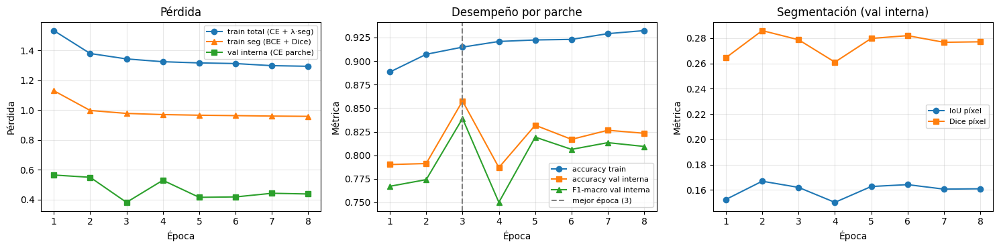


===== 5-curvas | segformer =====


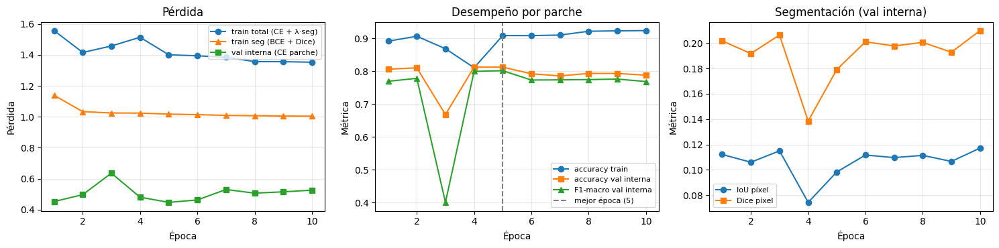

In [11]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("5-curvas", r'''
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(hist.epoch, hist.train_loss, "o-", label="train total (CE + λ·seg)")
ax[0].plot(hist.epoch, hist.train_seg_loss, "^-", label="train seg (BCE + Dice)")
ax[0].plot(hist.epoch, hist.val_loss, "s-", label="val interna (CE parche)")
ax[0].set_title("Pérdida"); ax[0].set_ylabel("Pérdida")
ax[1].plot(hist.epoch, hist.train_acc, "o-", label="accuracy train")
ax[1].plot(hist.epoch, hist.val_acc, "s-", label="accuracy val interna")
ax[1].plot(hist.epoch, hist.val_f1_macro, "^-", label="F1-macro val interna")
ax[1].axvline(info["best_epoch"], ls="--", c="gray", label=f"mejor época ({info['best_epoch']})")
ax[1].set_title("Desempeño por parche"); ax[1].set_ylabel("Métrica")
ax[2].plot(hist.epoch, hist.val_iou_pix, "o-", label="IoU píxel"); ax[2].plot(hist.epoch, hist.val_dice_pix, "s-", label="Dice píxel")
ax[2].set_title("Segmentación (val interna)"); ax[2].set_ylabel("Métrica")
for a in ax: a.set_xlabel("Época"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); savefig("curvas_entrenamiento"); plt.show()
''')


## 6. Evaluación sobre `val` (y `test`)


===== 6 | swin_unetr =====


,conjunto,accuracy,balanced_acc,f1_macro,precision_macro,recall_macro,f1_weighted,mcc,kappa,auc,iou_pix,dice_pix,precision_pix,recall_pix,ap_pix
0,val,0.888,0.8379,0.8342,0.8306,0.8379,0.8886,0.6684,0.6683,0.9365,0.1575,0.2722,0.2392,0.3157,0.1977
0,test,0.888,0.8408,0.8171,0.7989,0.8408,0.8917,0.6383,0.6348,0.9050,0.1376,0.2419,0.2022,0.3010,0.1701


Segmentación en val: IoU=0.1575 | Dice=0.2722 | AP=0.1977 | MAE fracción de pérdida=0.0208 | r Pearson=0.679


,precision,recall,f1-score,support
sin_deforestacion,0.9325,0.9249,0.9287,1105.000
deforestacion,0.7288,0.7508,0.7396,297.000
accuracy,0.8880,0.8880,0.8880,0.888
macro avg,0.8306,0.8379,0.8342,1402.000
weighted avg,0.8893,0.8880,0.8886,1402.000


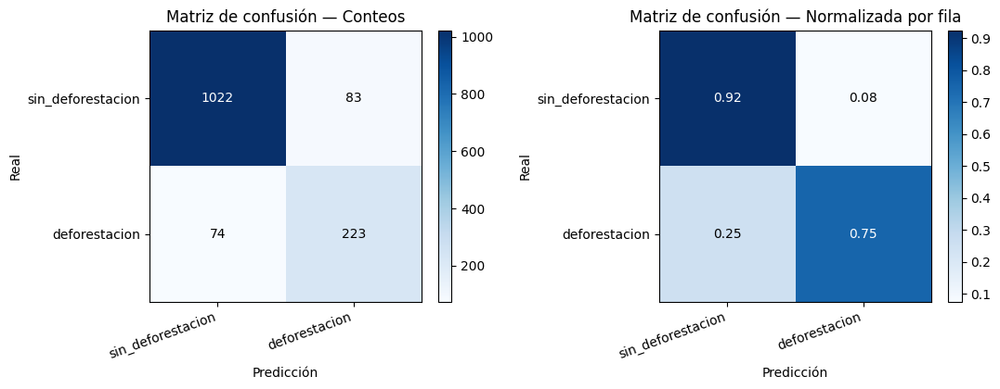

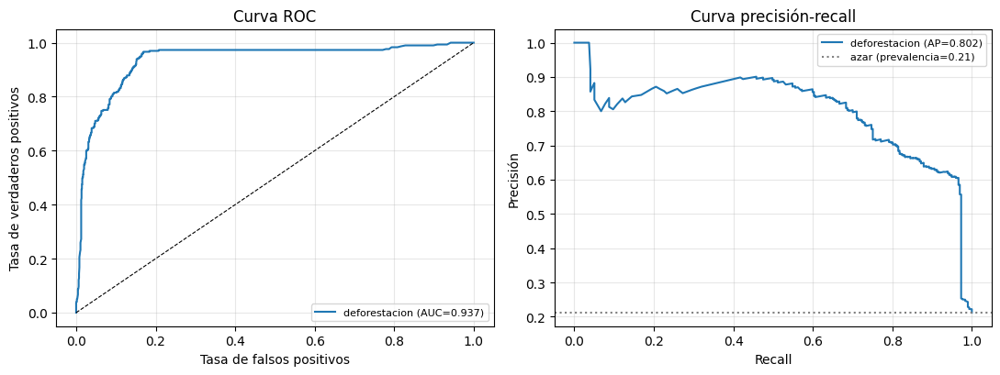


===== 6 | segformer =====


,conjunto,accuracy,balanced_acc,f1_macro,precision_macro,recall_macro,f1_weighted,mcc,kappa,auc,iou_pix,dice_pix,precision_pix,recall_pix,ap_pix
0,val,0.8802,0.9018,0.8439,0.8159,0.9018,0.8873,0.7126,0.6913,0.9466,0.1086,0.1959,0.2082,0.1850,0.1725
0,test,0.8445,0.8684,0.7831,0.7529,0.8684,0.8587,0.6104,0.5751,0.9183,0.1032,0.1871,0.1766,0.1989,0.1475


Segmentación en val: IoU=0.1086 | Dice=0.1959 | AP=0.1725 | MAE fracción de pérdida=0.0244 | r Pearson=0.363


,precision,recall,f1-score,support
sin_deforestacion,0.9815,0.8643,0.9192,1105.0000
deforestacion,0.6503,0.9394,0.7686,297.0000
accuracy,0.8802,0.8802,0.8802,0.8802
macro avg,0.8159,0.9018,0.8439,1402.0000
weighted avg,0.9113,0.8802,0.8873,1402.0000


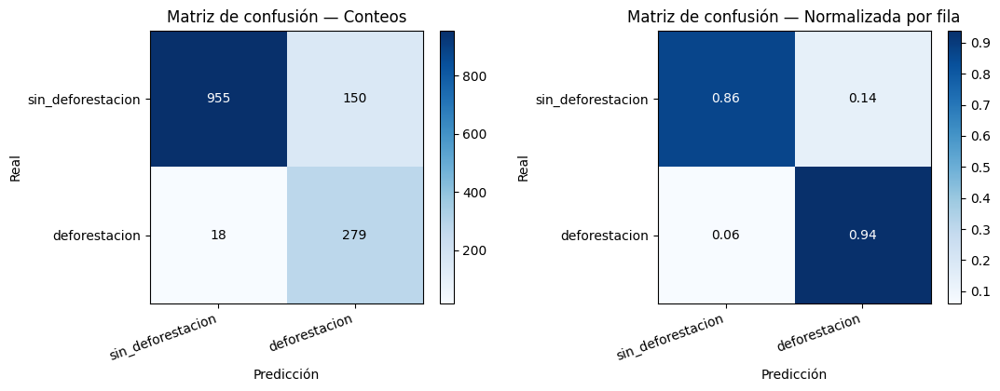

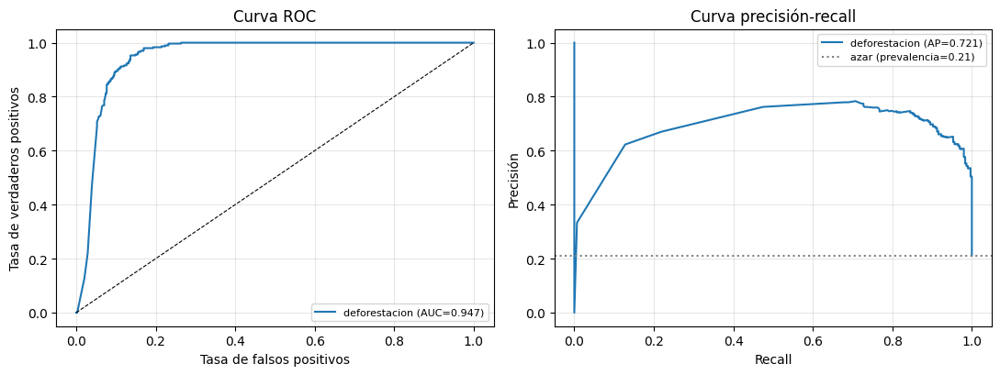

In [12]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("6", r'''
assert globals().get("TRAIN_RUN_ID"), "Ejecuta primero la sección 5."
EVALUATED_RUN_ID = None
hold_loader = make_loader(holdout, False, masks=True)
y_hold, p_hold, idx_hold, seg_hold, frac_pred_hold = predict_full(model, hold_loader)
pred_hold = p_hold.argmax(1)
m_hold = compute_metrics(y_hold, p_hold)
res_main = pd.DataFrame([{"conjunto": HOLDOUT_NAME, **m_hold, **seg_hold}])
if extra_test:
    y_ext, p_ext, _, seg_ext, _ = predict_full(model, make_loader(extra_test, False, masks=True))
    res_main = pd.concat([res_main, pd.DataFrame([{"conjunto": "test", **compute_metrics(y_ext, p_ext), **seg_ext}])])
display(res_main.round(4)); save_table(res_main, f"metricas_{ARCH}")
true_frac = np.array([FRAC[HOLDOUT_NAME][holdout[j][1]] for j in idx_hold])
print(f"Segmentación en {HOLDOUT_NAME}: IoU={seg_hold['iou_pix']:.4f} | Dice={seg_hold['dice_pix']:.4f} | "
      f"AP={seg_hold['ap_pix']:.4f} | MAE fracción de pérdida={np.abs(frac_pred_hold - true_frac).mean():.4f} | "
      f"r Pearson={np.corrcoef(frac_pred_hold, true_frac)[0, 1]:.3f}")

rep = pd.DataFrame(classification_report(y_hold, pred_hold, labels=list(range(K)), target_names=CLASSES,
                                         output_dict=True, zero_division=0)).T
display(rep.round(4)); save_table(rep.reset_index().rename(columns={"index": "clase"}), "reporte_por_clase")

cm = confusion_matrix(y_hold, pred_hold, labels=list(range(K)))
cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a, mat, title, fmt in [(ax[0], cm, "Conteos", "d"), (ax[1], cmn, "Normalizada por fila", ".2f")]:
    im = a.imshow(mat, cmap="Blues"); plt.colorbar(im, ax=a, fraction=0.046)
    a.set_xticks(range(K)); a.set_yticks(range(K)); a.set_xticklabels(CLASSES, rotation=20, ha="right"); a.set_yticklabels(CLASSES)
    a.set_xlabel("Predicción"); a.set_ylabel("Real"); a.set_title(f"Matriz de confusión — {title}")
    for i in range(K):
        for j in range(K):
            a.text(j, i, format(mat[i, j], fmt), ha="center", va="center", color="white" if mat[i, j] > mat.max() / 2 else "black")
plt.tight_layout(); savefig("matriz_confusion"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for k in ([1] if K == 2 else range(K)):
    yk = (y_hold == k).astype(int)
    if yk.min() == yk.max(): continue
    fpr, tpr, _ = roc_curve(yk, p_hold[:, k]); pr, rc, _ = precision_recall_curve(yk, p_hold[:, k])
    ax[0].plot(fpr, tpr, label=f"{CLASSES[k]} (AUC={roc_auc_score(yk, p_hold[:, k]):.3f})")
    ax[1].plot(rc, pr, label=f"{CLASSES[k]} (AP={average_precision_score(yk, p_hold[:, k]):.3f})")
    ax[1].axhline(yk.mean(), ls=":", c="gray", label=f"azar (prevalencia={yk.mean():.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos"); ax[0].set_title("Curva ROC")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisión"); ax[1].set_title("Curva precisión-recall")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); savefig("curvas_roc_pr"); plt.show()
EVALUATED_RUN_ID = TRAIN_RUN_ID

''')


## 7. Predicciones sobre `val`
CSV con el índice de cada parche en `val_X.npy`, la clase real y predicha, la confianza, la fracción de pérdida real y **predicha por el modelo**, y la probabilidad por clase. Se muestran los mapas de probabilidad de pérdida. Al final, `predecir_parche()` hace inferencia sobre cualquier arreglo nuevo.


===== 7 | swin_unetr =====
1402 predicciones guardadas | aciertos: 0.8880


,particion,indice,clase_real,clase_predicha,confianza,correcto,frac_perdida,frac_valida,frac_predicha,p_sin_deforestacion,p_deforestacion
0,val,0,sin_deforestacion,sin_deforestacion,0.964254,True,0.000196,0.623596,0.000000,0.964254,0.035746
1,val,1,sin_deforestacion,sin_deforestacion,0.964254,True,0.000506,0.964355,0.000443,0.964254,0.035746
2,val,2,sin_deforestacion,sin_deforestacion,0.964254,True,0.039853,0.581970,0.036497,0.964254,0.035746
3,val,3,sin_deforestacion,sin_deforestacion,0.964254,True,0.000563,0.975525,0.000313,0.964254,0.035746
4,val,4,sin_deforestacion,sin_deforestacion,0.964254,True,0.000549,1.000000,0.000000,0.964254,0.035746
5,val,5,sin_deforestacion,sin_deforestacion,0.964254,True,0.006852,0.668030,0.019552,0.964254,0.035746
6,val,6,sin_deforestacion,sin_deforestacion,0.964254,True,0.003102,0.255798,0.000239,0.964254,0.035746
7,val,7,sin_deforestacion,sin_deforestacion,0.964254,True,0.005004,0.927002,0.007506,0.964254,0.035746
8,val,8,sin_deforestacion,sin_deforestacion,0.964254,True,0.000061,1.000000,0.000000,0.964254,0.035746
9,val,9,sin_deforestacion,sin_deforestacion,0.964254,True,0.005428,0.978210,0.019530,0.964254,0.035746


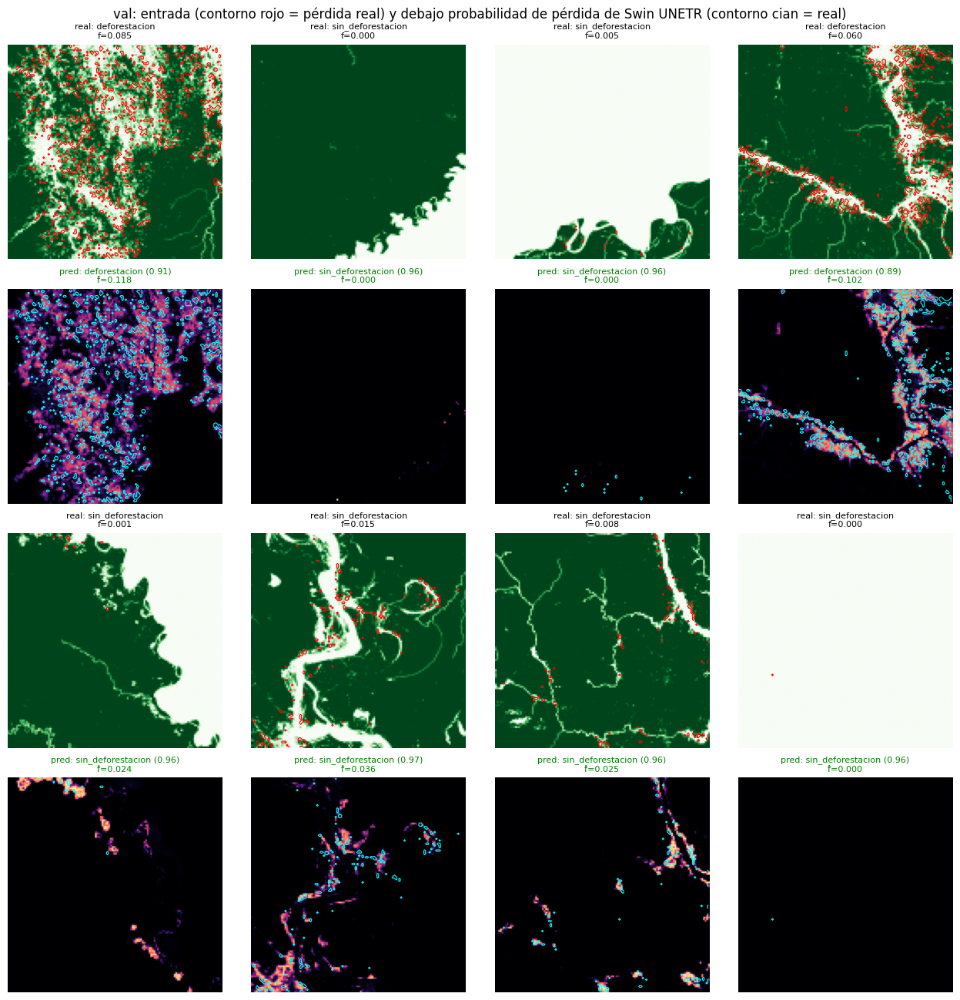

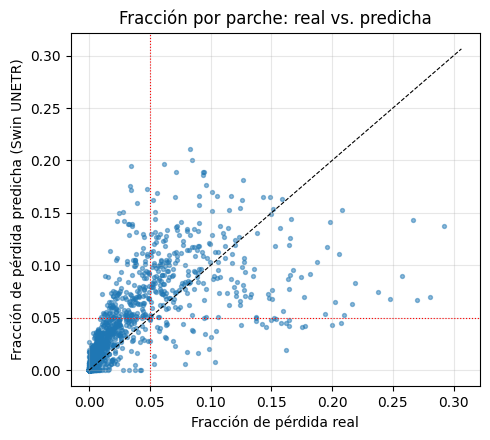

Inferencia con pesos recargados: {'sin_deforestacion': 0.9642000198364258, 'deforestacion': 0.03579999879002571, 'frac_perdida_predicha': 0.0} | real: sin_deforestacion

===== 7 | segformer =====
1402 predicciones guardadas | aciertos: 0.8802


,particion,indice,clase_real,clase_predicha,confianza,correcto,frac_perdida,frac_valida,frac_predicha,p_sin_deforestacion,p_deforestacion
0,val,0,sin_deforestacion,sin_deforestacion,0.969814,True,0.000196,0.623596,0.000000,0.969814,0.030186
1,val,1,sin_deforestacion,sin_deforestacion,0.969814,True,0.000506,0.964355,0.000316,0.969814,0.030186
2,val,2,sin_deforestacion,sin_deforestacion,0.969900,True,0.039853,0.581970,0.065967,0.969900,0.030100
3,val,3,sin_deforestacion,sin_deforestacion,0.969871,True,0.000563,0.975525,0.000000,0.969871,0.030129
4,val,4,sin_deforestacion,sin_deforestacion,0.969843,True,0.000549,1.000000,0.000000,0.969843,0.030157
5,val,5,sin_deforestacion,sin_deforestacion,0.969900,True,0.006852,0.668030,0.015075,0.969900,0.030100
6,val,6,sin_deforestacion,sin_deforestacion,0.969928,True,0.003102,0.255798,0.000000,0.969928,0.030072
7,val,7,sin_deforestacion,sin_deforestacion,0.970070,True,0.005004,0.927002,0.004346,0.970070,0.029930
8,val,8,sin_deforestacion,sin_deforestacion,0.969843,True,0.000061,1.000000,0.000000,0.969843,0.030157
9,val,9,sin_deforestacion,sin_deforestacion,0.970042,True,0.005428,0.978210,0.019280,0.970042,0.029958


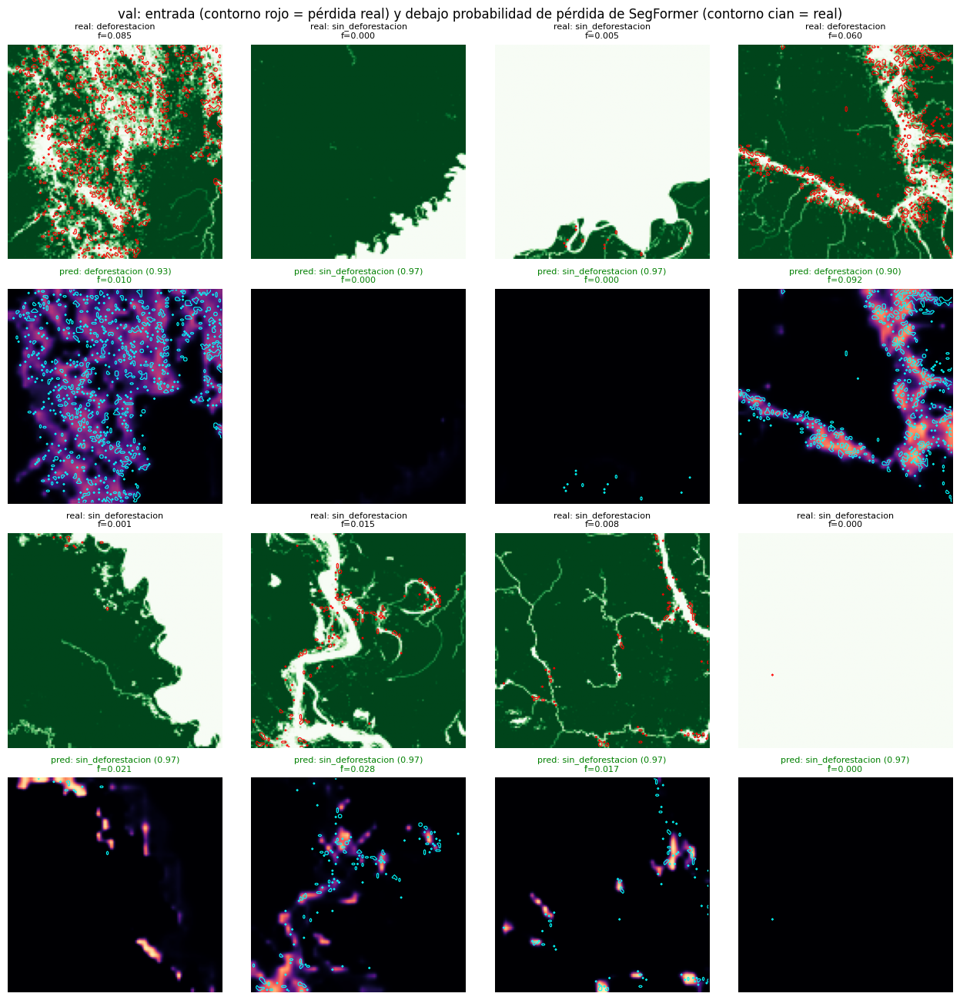

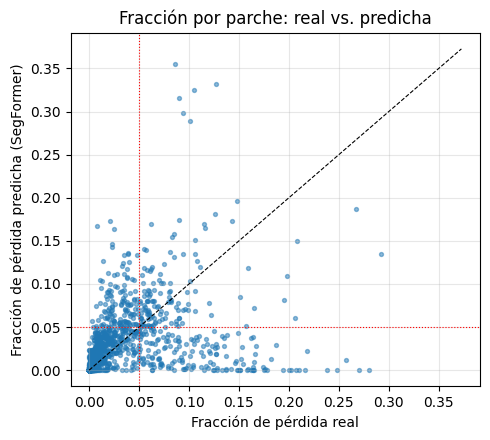

Inferencia con pesos recargados: {'sin_deforestacion': 0.9697999954223633, 'deforestacion': 0.03020000085234642, 'frac_perdida_predicha': 0.0} | real: sin_deforestacion


In [13]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("7", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
pred_df = pd.DataFrame({
    "particion": HOLDOUT_NAME, "indice": [holdout[j][1] for j in idx_hold],
    "clase_real": [CLASSES[k] for k in y_hold], "clase_predicha": [CLASSES[k] for k in pred_hold],
    "confianza": p_hold.max(1), "correcto": y_hold == pred_hold,
    "frac_perdida": [FRAC[HOLDOUT_NAME][holdout[j][1]] for j in idx_hold],
    "frac_valida": [VALID[HOLDOUT_NAME][holdout[j][1]] for j in idx_hold],
    "frac_predicha": frac_pred_hold})
for k, c in enumerate(CLASSES):
    pred_df[f"p_{c}"] = p_hold[:, k]
pred_df.to_csv(OUT / "tables" / f"predicciones_{HOLDOUT_NAME}.csv", index=False)
print(f"{len(pred_df)} predicciones guardadas | aciertos: {pred_df.correcto.mean():.4f}")
display(pred_df.head(10))

hold_ds = NpyDS(holdout, False)
pos_of = {holdout[j][1]: j for j in range(len(holdout))}
@torch.no_grad()
def seg_map(indice):
    x = hold_ds[pos_of[indice]][0][None].to(DEVICE)
    return torch.sigmoid(model.eval().segment(x).float())[0, 0].cpu().numpy()

N_SHOW, COLS = 8, 4                                    # número de ejemplos y columnas máximas
sel = pred_df.sample(min(N_SHOW, len(pred_df)), random_state=SEED)
n_rows = math.ceil(len(sel) / COLS)                    # filas de ejemplos (cada una ocupa 2 filas de imágenes)
fig, axes = plt.subplots(2 * n_rows, COLS, figsize=(3.2 * COLS, 3.3 * 2 * n_rows), squeeze=False)
for j, (_, r) in enumerate(sel.iterrows()):
    rr, cc = 2 * (j // COLS), j % COLS
    m = loss_mask(HOLDOUT_NAME, r.indice); pm = seg_map(r.indice)
    axes[rr, cc].imshow(rgb_image(HOLDOUT_NAME, r.indice))
    if m is not None and m.any(): axes[rr, cc].contour(m, levels=[0.5], colors="red", linewidths=0.8)
    axes[rr, cc].set_title(f"real: {r.clase_real}\nf={r.frac_perdida:.3f}", fontsize=8)
    axes[rr + 1, cc].imshow(pm, cmap="magma", vmin=0, vmax=1)
    if m is not None and m.any(): axes[rr + 1, cc].contour(m, levels=[0.5], colors="cyan", linewidths=0.8)
    axes[rr + 1, cc].set_title(f"pred: {r.clase_predicha} ({r.confianza:.2f})\nf̂={r.frac_predicha:.3f}", fontsize=8,
                               color="green" if r.correcto else "red")
for a in axes.flat: a.axis("off")
plt.suptitle(f"{HOLDOUT_NAME}: entrada (contorno rojo = pérdida real) y debajo probabilidad de pérdida de {ARCH_LABEL} (contorno cian = real)")
plt.tight_layout(); savefig("predicciones_ejemplos"); plt.show()

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(pred_df.frac_perdida, pred_df.frac_predicha, s=8, alpha=.5)
lim = max(pred_df.frac_perdida.max(), pred_df.frac_predicha.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=.8); ax.axvline(FRAC_THRESHOLD, c="r", ls=":", lw=.8); ax.axhline(FRAC_THRESHOLD, c="r", ls=":", lw=.8)
ax.set_xlabel("Fracción de pérdida real"); ax.set_ylabel(f"Fracción de pérdida predicha ({ARCH_LABEL})")
ax.set_title("Fracción por parche: real vs. predicha"); ax.grid(alpha=.3)
plt.tight_layout(); savefig("fraccion_real_vs_predicha"); plt.show()

def load_model(path=CKPT_PATH):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = build_model(len(ck["classes"]), arch=ck["arch"], dropout=ck["dropout"], c_in=len(ck["ch_order"]))
    m.load_state_dict(ck["state_dict"]); return m.to(DEVICE).eval(), ck

@torch.no_grad()
def predecir_parche(x_raw, m=None, ck=None):
    # x_raw: un parche con la misma disposición que X (p. ej. H×W×C sin normalizar)
    m = m or model
    ch = ck["ch_order"] if ck else CH_ORDER
    mean, std = (ck["mean_all"], ck["std_all"]) if ck else (MEAN_ALL, STD_ALL)
    lay = ck["layout"] if ck else LAYOUT
    a = np.asarray(x_raw, dtype=np.float32)
    a = a.transpose(2, 0, 1) if lay == "NHWC" else (a[None] if lay == "NHW" else a)
    x = np.nan_to_num((a[ch] - mean[ch, None, None]) / std[ch, None, None])
    cls, seg = m.eval().forward_all(torch.from_numpy(x)[None].to(DEVICE))
    p = cls.softmax(1)[0].cpu().numpy()
    out = dict(zip(ck["classes"] if ck else CLASSES, p.round(4).tolist()))
    out["frac_perdida_predicha"] = round(float((torch.sigmoid(seg) > 0.5).float().mean()), 4)
    return out

m_loaded, ck_loaded = load_model()
i0 = holdout[0][1]
print("Inferencia con pesos recargados:", predecir_parche(arr(HOLDOUT_NAME)[i0], m_loaded, ck_loaded),
      "| real:", CLASSES[holdout[0][2]])
del m_loaded
''')


## 8. Líneas base (R3)
1. **Random Forest con estadísticos por banda**: media, desviación y percentiles 10/50/90 de cada banda estandarizada, magnitud de gradiente (textura) e índice de verdor ExG; e **NDVI** si hay banda NIR y los valores crudos son no negativos. `max_depth` elegido en la validación interna.
2. **Regresión logística** sobre los mismos descriptores manuales (modelo lineal clásico). `C` elegido en la validación interna.


===== 8 | swin_unetr =====
Descriptores manuales por parche: 159
RF max_depth=None: F1 val interna=0.7951
RF max_depth=10: F1 val interna=0.7958
RF max_depth=20: F1 val interna=0.8032
LogReg C=0.01: F1 val interna=0.7648
LogReg C=0.1: F1 val interna=0.7896
LogReg C=1.0: F1 val interna=0.8040
LogReg C=10.0: F1 val interna=0.8052


,modelo,accuracy,balanced_acc,f1_macro,precision_macro,recall_macro,f1_weighted,mcc,kappa,auc
0,Random Forest (estadísticos por banda),0.9066,0.8853,0.8667,0.8516,0.8853,0.9087,0.7362,0.7336,0.9655
1,Reg. logística (estadísticos por banda),0.8909,0.8766,0.8483,0.8283,0.8766,0.8946,0.7032,0.6974,0.9595
2,Swin UNETR (propuesto),0.8880,0.8379,0.8342,0.8306,0.8379,0.8886,0.6684,0.6683,0.9365


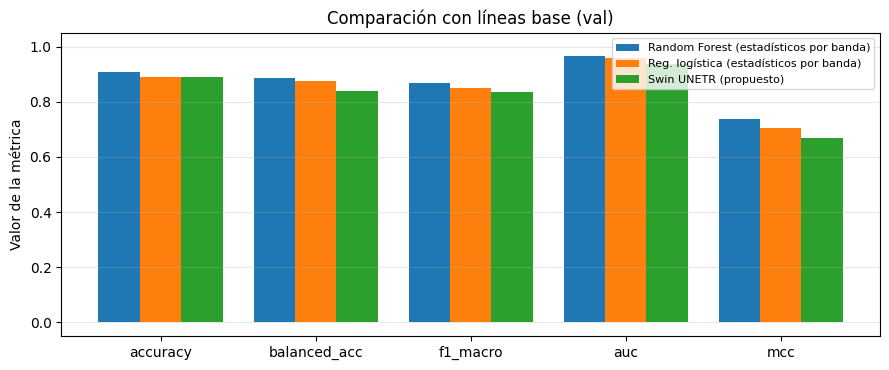


===== 8 | segformer =====
Descriptores manuales por parche: 159
RF max_depth=None: F1 val interna=0.7951
RF max_depth=10: F1 val interna=0.7958
RF max_depth=20: F1 val interna=0.8032
LogReg C=0.01: F1 val interna=0.7648
LogReg C=0.1: F1 val interna=0.7896
LogReg C=1.0: F1 val interna=0.8040
LogReg C=10.0: F1 val interna=0.8052


,modelo,accuracy,balanced_acc,f1_macro,precision_macro,recall_macro,f1_weighted,mcc,kappa,auc
0,Random Forest (estadísticos por banda),0.9066,0.8853,0.8667,0.8516,0.8853,0.9087,0.7362,0.7336,0.9655
1,Reg. logística (estadísticos por banda),0.8909,0.8766,0.8483,0.8283,0.8766,0.8946,0.7032,0.6974,0.9595
2,SegFormer (propuesto),0.8802,0.9018,0.8439,0.8159,0.9018,0.8873,0.7126,0.6913,0.9466


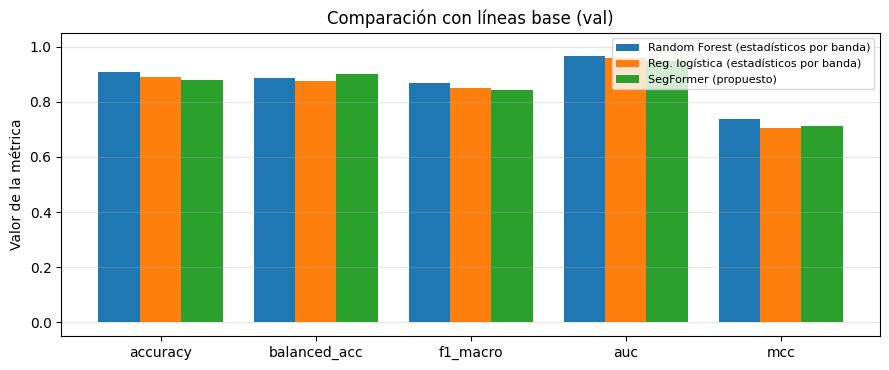

In [14]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("8", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

QS = torch.tensor([0.1, 0.5, 0.9])
#r_pos = CH_ORDER.index(RGB_IDX[0]) if RGB_IDX is not None and len(RGB_IDX) > 0 and RGB_IDX[0] in CH_ORDER else None
r_pos = (
    CH_ORDER.index(RGB_IDX[0])
    if RGB_IDX is not None
    and len(RGB_IDX) > 0
    and RGB_IDX[0] in CH_ORDER
    else None
)
n_pos = CH_ORDER.index(NIR_IDX) if (NIR_IDX is not None and NIR_IDX in CH_ORDER) else None

def handcrafted_batch(x):
    xs = F.adaptive_avg_pool2d(x, (min(x.shape[-2], 64), min(x.shape[-1], 64)))
    flat = xs.flatten(2)
    f = [flat.mean(2), flat.std(2), torch.quantile(flat, QS, dim=2).permute(1, 2, 0).flatten(1)]
    g = xs.mean(1); gx, gy = g[:, :, 1:] - g[:, :, :-1], g[:, 1:, :] - g[:, :-1, :]
    f += [torch.stack([gx.abs().mean((1, 2)), gy.abs().mean((1, 2)), gx.std((1, 2)), gy.std((1, 2))], 1)]
    if RGB_FOUND and RGB_IDX is not None and all(i in CH_ORDER for i in RGB_IDX):
        rp, gp, bp = [CH_ORDER.index(i) for i in RGB_IDX]
        exg = 2 * xs[:, gp] - xs[:, rp] - xs[:, bp]
        f += [torch.stack([exg.mean((1, 2)), exg.std((1, 2))], 1)]
    if RAW_NONNEG and r_pos is not None and n_pos is not None:
        mean_t, std_t = torch.tensor(MEAN_ALL[CH_ORDER]), torch.tensor(STD_ALL[CH_ORDER])
        nir = xs[:, n_pos] * std_t[n_pos] + mean_t[n_pos]; red = xs[:, r_pos] * std_t[r_pos] + mean_t[r_pos]
        ndvi = (nir - red) / (nir + red + 1e-6); f += [torch.stack([ndvi.mean((1, 2)), ndvi.std((1, 2))], 1)]
    return torch.cat(f, 1)

def handcrafted_features(samples):
    fs, ys = [], []
    for x, y, _ in make_loader(samples, False, masks=False):
        fs.append(handcrafted_batch(x)); ys.append(y)
    return torch.cat(fs).numpy(), torch.cat(ys).numpy()

@torch.no_grad()
def extract_features(net, samples, ch_order=None):
    net.eval(); fs, ys = [], []
    for x, y, _ in make_loader(samples, False, ch_order=ch_order, masks=False):
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            fs.append(net(x.to(DEVICE)).float().cpu())
        ys.append(y)
    return torch.cat(fs).numpy(), torch.cat(ys).numpy()

baseline_rows = []
if RUN_BASELINES:
    t0 = time.time()
    Xtr, ytr = handcrafted_features(train_s); Xiv, yiv = handcrafted_features(ival_s); Xho, yho = handcrafted_features(holdout)
    print("Descriptores manuales por parche:", Xtr.shape[1])
    best_rf, best_f1 = None, -1
    for depth in [None, 10, 20]:
        rf = RandomForestClassifier(n_estimators=300, max_depth=depth, class_weight="balanced", n_jobs=-1,
                                    random_state=SEED).fit(Xtr, ytr)
        f1v = f1_score(yiv, rf.predict(Xiv), average="macro"); print(f"RF max_depth={depth}: F1 val interna={f1v:.4f}")
        if f1v > best_f1: best_rf, best_f1 = rf, f1v
    baseline_rows.append({"modelo": "Random Forest (estadísticos por banda)", **compute_metrics(yho, best_rf.predict_proba(Xho))})
    log_compute("RF estadísticos por banda", "línea base", time.time() - t0)

    t0 = time.time()
    best_lr, best_f1 = None, -1
    for Cr in [0.01, 0.1, 1.0, 10.0]:
        lr_ = make_pipeline(StandardScaler(), LogisticRegression(C=Cr, max_iter=3000, class_weight="balanced")).fit(Xtr, ytr)
        f1v = f1_score(yiv, lr_.predict(Xiv), average="macro"); print(f"LogReg C={Cr}: F1 val interna={f1v:.4f}")
        if f1v > best_f1: best_lr, best_f1 = lr_, f1v
    baseline_rows.append({"modelo": "Reg. logística (estadísticos por banda)", **compute_metrics(yho, best_lr.predict_proba(Xho))})
    log_compute("LogReg estadísticos por banda", "línea base", time.time() - t0)

baseline_rows.append({"modelo": f"{ARCH_LABEL} (propuesto)", **m_hold})
comp = pd.DataFrame(baseline_rows); display(comp.round(4)); save_table(comp, "comparacion_lineas_base")

fig, ax = plt.subplots(figsize=(9, 3.8))
mets = ["accuracy", "balanced_acc", "f1_macro", "auc", "mcc"]; w = 0.8 / len(comp)
for i, (_, r) in enumerate(comp.iterrows()):
    ax.bar(np.arange(len(mets)) + i * w, [r[m] for m in mets], w, label=r.modelo)
ax.set_xticks(np.arange(len(mets)) + w * (len(comp) - 1) / 2); ax.set_xticklabels(mets)
ax.set_ylabel("Valor de la métrica"); ax.set_ylim(min(0, comp[mets].min().min()) - 0.05, 1.05)
ax.set_title(f"Comparación con líneas base ({HOLDOUT_NAME})"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); savefig("comparacion_lineas_base"); plt.show()
''')


## 9. Ablaciones controladas con varias semillas (R4)
Cada variante cambia **un solo componente** respecto al modelo completo y se entrena con las mismas particiones y semillas. La elección se hace con la **validación interna**; las columnas de `val` solo se reportan.

| Variante | Qué se cambia | Pregunta |
|---|---|---|
| Completo | — | referencia |
| Arquitectura alternativa | SegFormer ↔ Swin UNETR | comparación controlada de los dos Transformers jerárquicos |
| Sin ventanas desplazadas (solo Swin UNETR) | todas las ventanas fijas | ¿hace falta que la atención cruce los bordes de las ventanas? |
| Sin reducción espacial (solo SegFormer) | `SEGF_SR = 1` (atención completa) | ¿la atención eficiente pierde información? |
| Menor capacidad | anchos × 0.5 | ¿se puede reducir el costo sin perder desempeño? |
| Sin pérdida de segmentación | $\lambda = 0$ (solo clasificación) | ¿la supervisión por píxel mejora la clasificación del parche? |
| Sin *data augmentation* | sin volteos/rotaciones/jitter | ¿ayudan las invariancias geométricas? |
| Sin pesos de clase ni LS | CE estándar | ¿importa tratar el desbalance? |


===== 9 | swin_unetr =====
[Completo (seed 42)] época 01/5 | loss 1.5328 (seg 1.1297) | acc 0.8884 | val_F1 0.7671 | val_IoU_pix 0.1524  * | 176s
[Completo (seed 42)] época 02/5 | loss 1.3657 (seg 0.9972) | acc 0.9133 | val_F1 0.7657 | val_IoU_pix 0.1624 | 355s
[Completo (seed 42)] época 03/5 | loss 1.3243 (seg 0.9750) | acc 0.9220 | val_F1 0.8149 | val_IoU_pix 0.1614  * | 534s
[Completo (seed 42)] época 04/5 | loss 1.3104 (seg 0.9655) | acc 0.9289 | val_F1 0.8081 | val_IoU_pix 0.1522 | 716s
[Completo (seed 42)] época 05/5 | loss 1.2988 (seg 0.9613) | acc 0.9328 | val_F1 0.8102 | val_IoU_pix 0.1638 | 892s
Completo                               seed=   42 | F1 val interna=0.8149 | F1 val=0.8620 | IoU píxel=0.1566 | 892s
[Completo (seed 123)] época 01/5 | loss 1.4956 (seg 1.0953) | acc 0.8908 | val_F1 0.7665 | val_IoU_pix 0.1290  * | 178s
[Completo (seed 123)] época 02/5 | loss 1.3540 (seg 0.9933) | acc 0.9147 | val_F1 0.7940 | val_IoU_pix 0.1528  * | 356s
[Completo (seed 123)] época 03

,val_interna_f1,val_f1,val_acc,val_bal_acc,val_auc,val_iou_pix,val_dice_pix,Δ F1 vs completo,parámetros (M)
variante,,,,,,,,,
Completo,0.8137 ± 0.0021,0.8617 ± 0.0024,0.9013 ± 0.0015,0.8878 ± 0.0126,0.9483 ± 0.0107,0.1579 ± 0.0019,0.2727 ± 0.0028,+0.0000,6.32
Arquitectura alternativa (SegFormer),0.8097 ± 0.0021,0.8648 ± 0.0043,0.9013 ± 0.0035,0.9013 ± 0.0154,0.9462 ± 0.0113,0.1146 ± 0.0036,0.2056 ± 0.0058,+0.0031,3.76
Sin ventanas desplazadas,0.8216 ± 0.0156,0.8635 ± 0.0131,0.9030 ± 0.0110,0.8876 ± 0.0078,0.9467 ± 0.0108,0.1550 ± 0.0071,0.2683 ± 0.0107,+0.0019,6.32
Menor capacidad (anchos × 0.5),0.8342 ± 0.0096,0.8667 ± 0.0046,0.9066 ± 0.0031,0.8857 ± 0.0056,0.9598 ± 0.0048,0.1540 ± 0.0039,0.2668 ± 0.0058,+0.0051,1.60
Sin pérdida de segmentación,0.8066 ± 0.0097,0.8653 ± 0.0133,0.9051 ± 0.0086,0.8865 ± 0.0179,0.9409 ± 0.0213,0.0245 ± 0.0110,0.0477 ± 0.0210,+0.0037,6.32
Sin data augmentation,0.8273 ± 0.0049,0.8639 ± 0.0157,0.9030 ± 0.0111,0.8896 ± 0.0171,0.9514 ± 0.0111,0.1588 ± 0.0014,0.2741 ± 0.0021,+0.0022,6.32
Sin pesos de clase ni LS,0.8270 ± 0.0101,0.8615 ± 0.0116,0.8997 ± 0.0082,0.8941 ± 0.0137,0.9627 ± 0.0011,0.1593 ± 0.0014,0.2748 ± 0.0020,-0.0002,6.32


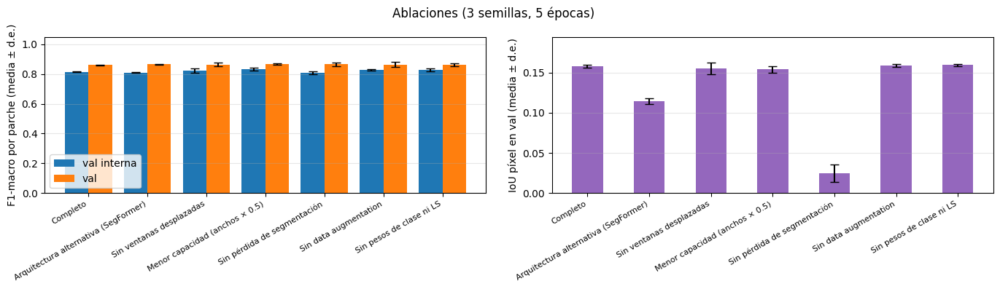


===== 9 | segformer =====
[Completo (seed 42)] época 01/5 | loss 1.5653 (seg 1.1415) | acc 0.8885 | val_F1 0.7346 | val_IoU_pix 0.0991  * | 124s
[Completo (seed 42)] época 02/5 | loss 1.5430 (seg 1.0389) | acc 0.8198 | val_F1 0.7035 | val_IoU_pix 0.0880 | 244s
[Completo (seed 42)] época 03/5 | loss 1.6043 (seg 1.0260) | acc 0.7423 | val_F1 0.7427 | val_IoU_pix 0.0874  * | 368s
[Completo (seed 42)] época 04/5 | loss 1.5166 (seg 1.0220) | acc 0.8427 | val_F1 0.7601 | val_IoU_pix 0.0745  * | 491s
[Completo (seed 42)] época 05/5 | loss 1.4844 (seg 1.0148) | acc 0.8621 | val_F1 0.7578 | val_IoU_pix 0.0953 | 612s
Completo                               seed=   42 | F1 val interna=0.7601 | F1 val=0.7907 | IoU píxel=0.0974 | 612s
[Completo (seed 123)] época 01/5 | loss 1.5561 (seg 1.1479) | acc 0.8965 | val_F1 0.7513 | val_IoU_pix 0.0989  * | 120s
[Completo (seed 123)] época 02/5 | loss 1.4315 (seg 1.0337) | acc 0.9010 | val_F1 0.7796 | val_IoU_pix 0.0977  * | 243s
[Completo (seed 123)] época 

,val_interna_f1,val_f1,val_acc,val_bal_acc,val_auc,val_iou_pix,val_dice_pix,Δ F1 vs completo,parámetros (M)
variante,,,,,,,,,
Completo,0.7898 ± 0.0259,0.8366 ± 0.0406,0.8778 ± 0.0337,0.8786 ± 0.0346,0.9280 ± 0.0453,0.1115 ± 0.0123,0.2005 ± 0.0200,+0.0000,3.76
Arquitectura alternativa (Swin UNETR),0.8137 ± 0.0021,0.8617 ± 0.0024,0.9013 ± 0.0015,0.8878 ± 0.0126,0.9483 ± 0.0107,0.1579 ± 0.0019,0.2727 ± 0.0028,+0.0251,6.32
Sin reducción espacial (atención completa),0.8074 ± 0.0049,0.8514 ± 0.0084,0.8868 ± 0.0081,0.9065 ± 0.0044,0.9318 ± 0.0338,0.1165 ± 0.0025,0.2087 ± 0.0040,+0.0149,3.29
Menor capacidad (anchos × 0.5),0.8138 ± 0.0033,0.8593 ± 0.0061,0.8982 ± 0.0045,0.8911 ± 0.0100,0.9578 ± 0.0027,0.1213 ± 0.0055,0.2164 ± 0.0088,+0.0227,0.97
Sin pérdida de segmentación,0.7604 ± 0.0135,0.8066 ± 0.0226,0.8509 ± 0.0169,0.8615 ± 0.0311,0.8924 ± 0.0262,0.0249 ± 0.0051,0.0485 ± 0.0098,-0.0300,3.76
Sin data augmentation,0.8153 ± 0.0059,0.8601 ± 0.0093,0.8997 ± 0.0071,0.8883 ± 0.0186,0.9266 ± 0.0193,0.1107 ± 0.0131,0.1992 ± 0.0214,+0.0235,3.76
Sin pesos de clase ni LS,0.8070 ± 0.0057,0.8555 ± 0.0061,0.8961 ± 0.0018,0.8861 ± 0.0325,0.9246 ± 0.0285,0.1093 ± 0.0134,0.1968 ± 0.0219,+0.0189,3.76


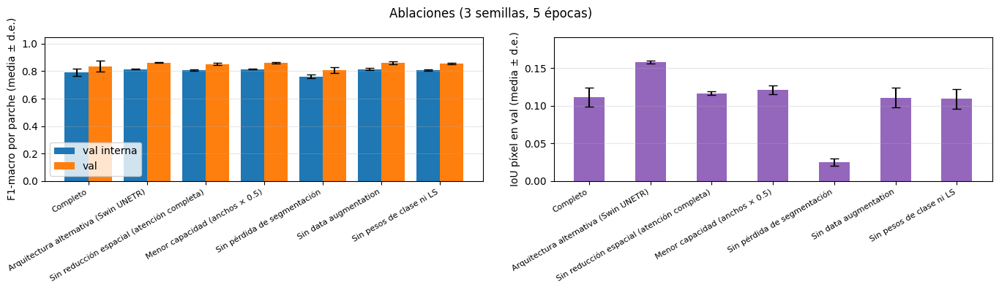

In [15]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("9", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
ABLATIONS = {
    "Completo": {},
    f"Arquitectura alternativa ({ARCH_LABELS['segformer' if ARCH_TYPE == 'swin_unetr' else 'swin_unetr']})":
        dict(arch="segformer" if ARCH_TYPE == "swin_unetr" else "swin_unetr"),
    **({"Sin ventanas desplazadas": dict(shift=False)} if ARCH_TYPE == "swin_unetr" else
       {"Sin reducción espacial (atención completa)": dict(sr_off=True)}),
    "Menor capacidad (anchos × 0.5)": dict(width=0.5),
    "Sin pérdida de segmentación": dict(seg_weight=0.0),
    "Sin data augmentation": dict(augment=False),
    "Sin pesos de clase ni LS": dict(use_class_weights=False, label_smoothing=0.0),
}
abl = pd.DataFrame()
if RUN_ABLATIONS:
    rows = []
    il = make_loader(ival_s, False, masks=True)
    for name, ov in ABLATIONS.items():
        for sd in ABLATION_SEEDS:
            m_, h_, inf_ = train_model(train_s, ival_s, epochs=ABLATION_EPOCHS, seed=sd, verbose=True,
                                       tag=f"{name} (seed {sd})", group="ablación", **ov)
            yv_, pv_, _, sv_, _ = predict_full(m_, il); yh_, ph_, _, sh_, _ = predict_full(m_, hold_loader)
            mv = compute_metrics(yv_, pv_); mh = compute_metrics(yh_, ph_)
            rows.append(dict(variante=name, seed=sd, parametros_M=sum(p.numel() for p in m_.parameters()) / 1e6,
                             val_interna_f1=mv["f1_macro"], val_f1=mh["f1_macro"], val_acc=mh["accuracy"],
                             val_bal_acc=mh["balanced_acc"], val_auc=mh["auc"], val_iou_pix=sh_["iou_pix"],
                             val_dice_pix=sh_["dice_pix"], mejor_epoca=inf_["best_epoch"], segundos=inf_["seconds"]))
            print(f"{name:38s} seed={sd:5d} | F1 val interna={mv['f1_macro']:.4f} | F1 {HOLDOUT_NAME}={mh['f1_macro']:.4f} | "
                  f"IoU píxel={sh_['iou_pix']:.4f} | {inf_['seconds']:.0f}s")
            pd.DataFrame(rows).to_csv(OUT / "tables" / "ablaciones_parciales.csv", index=False)
            torch.save({"state_dict": m_.state_dict(), "overrides": ov, "seed": sd, "info": inf_},
                       CKPT_DIR / f"ablacion_{list(ABLATIONS).index(name)}_seed{sd}.pt")
            del m_
            if DEVICE.type == "cuda": torch.cuda.empty_cache()
    abl = pd.DataFrame(rows); save_table(abl, "ablaciones_por_semilla")
    mc = ["val_interna_f1", "val_f1", "val_acc", "val_bal_acc", "val_auc", "val_iou_pix", "val_dice_pix"]
    g = abl.groupby("variante", sort=False)[mc]; mean, std = g.mean(), g.std(ddof=1).fillna(0)
    abl_summary = pd.DataFrame({c: [f"{mean.loc[v, c]:.4f} ± {std.loc[v, c]:.4f}" for v in mean.index] for c in mc}, index=mean.index)
    abl_summary["Δ F1 vs completo"] = [f"{mean.loc[v, 'val_f1'] - mean.iloc[0]['val_f1']:+.4f}" for v in mean.index]
    abl_summary["parámetros (M)"] = abl.groupby("variante", sort=False).parametros_M.first().round(2).values
    display(abl_summary); save_table(abl_summary.reset_index(), "ablaciones_resumen")

    fig, ax = plt.subplots(1, 2, figsize=(14, 4)); x = np.arange(len(mean))
    ax[0].bar(x - 0.2, mean.val_interna_f1, 0.4, yerr=std.val_interna_f1, capsize=4, label="val interna")
    ax[0].bar(x + 0.2, mean.val_f1, 0.4, yerr=std.val_f1, capsize=4, label=HOLDOUT_NAME)
    ax[0].set_ylabel("F1-macro por parche (media ± d.e.)"); ax[0].set_ylim(0, 1.05)
    ax[1].bar(x, mean.val_iou_pix, 0.5, yerr=std.val_iou_pix, capsize=4, color="tab:purple")
    ax[1].set_ylabel(f"IoU píxel en {HOLDOUT_NAME} (media ± d.e.)"); ax[1].set_ylim(0, max(0.05, (mean.val_iou_pix + std.val_iou_pix).max() * 1.2))
    for a in ax:
        a.set_xticks(x); a.set_xticklabels(mean.index, rotation=30, ha="right", fontsize=8); a.grid(axis="y", alpha=.3)
    ax[0].legend(); fig.suptitle(f"Ablaciones ({len(ABLATION_SEEDS)} semillas, {ABLATION_EPOCHS} épocas)")
    plt.tight_layout(); savefig("ablaciones"); plt.show()
''')


## 10. Interpretabilidad y análisis de errores (R5)
### 10.1 Grad-CAM
$$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}, \qquad L^c_{\text{Grad-CAM}} = \text{ReLU}\Big(\sum_k \alpha_k^c A^k\Big)$$
sobre el **mapa del encoder a escala 1/16** (punto `model.bott`, 8×8 con parches de 128 px), para la salida de **clasificación del parche**. Además de Grad-CAM, el segmentador produce su propio mapa de probabilidad de pérdida, que se evalúa en §10.2. El mapa se reescala al tamaño original del parche y se dibuja junto al **contorno de la pérdida real** (rojo).


===== 10.1 | swin_unetr =====


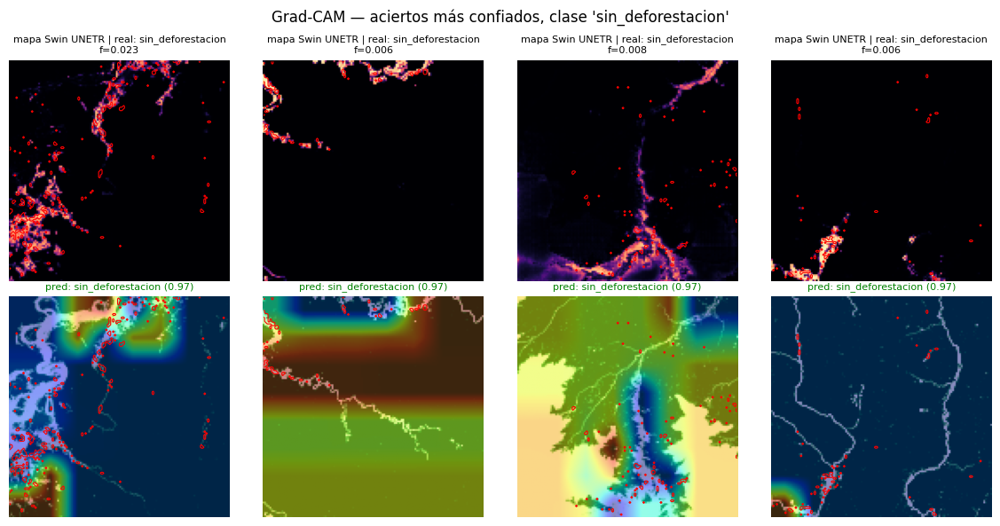

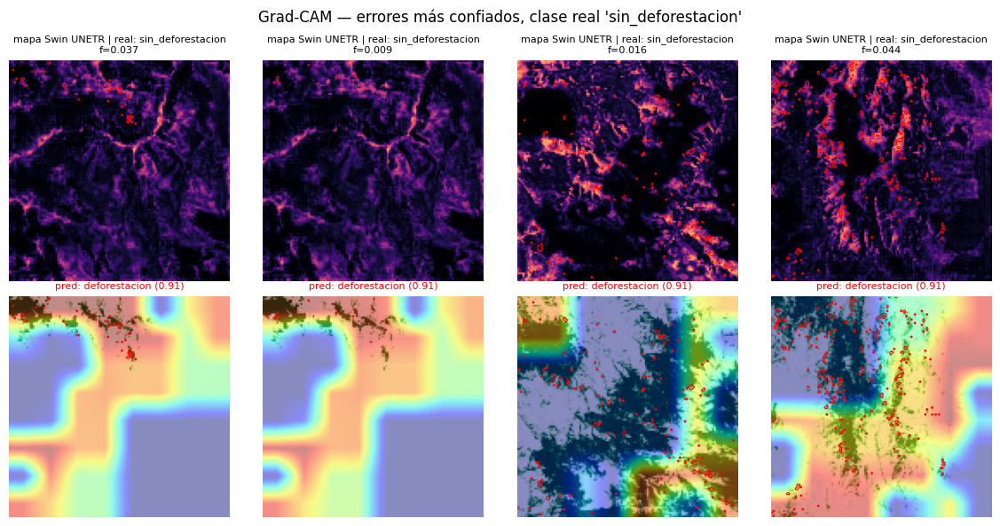

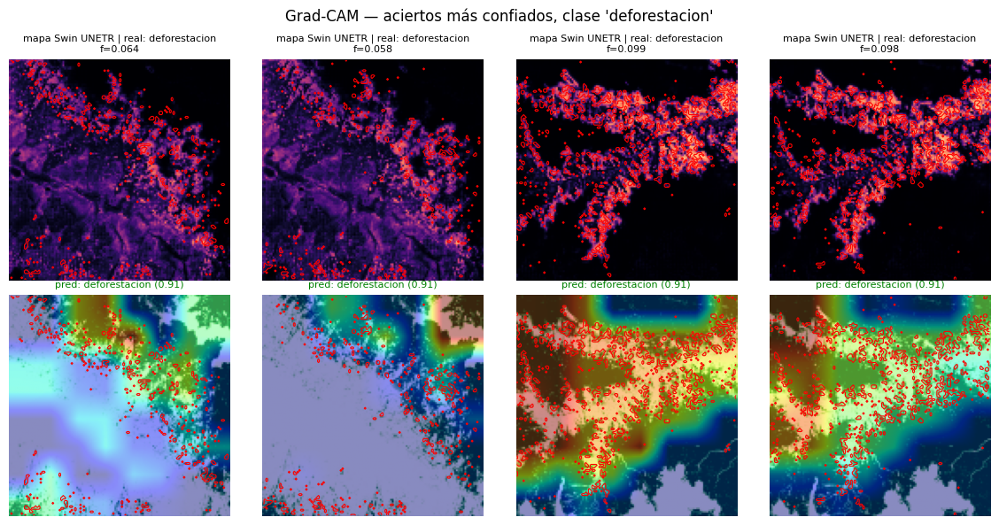

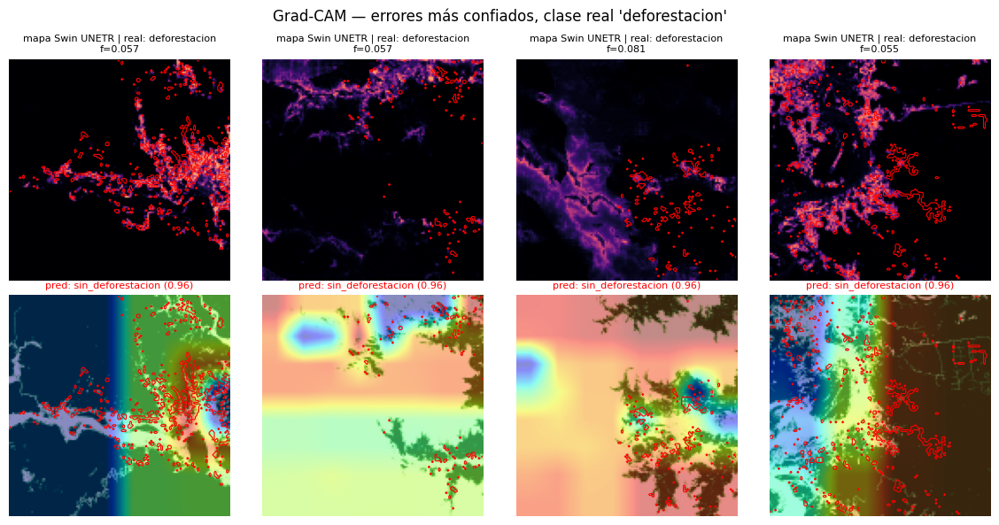


===== 10.1 | segformer =====


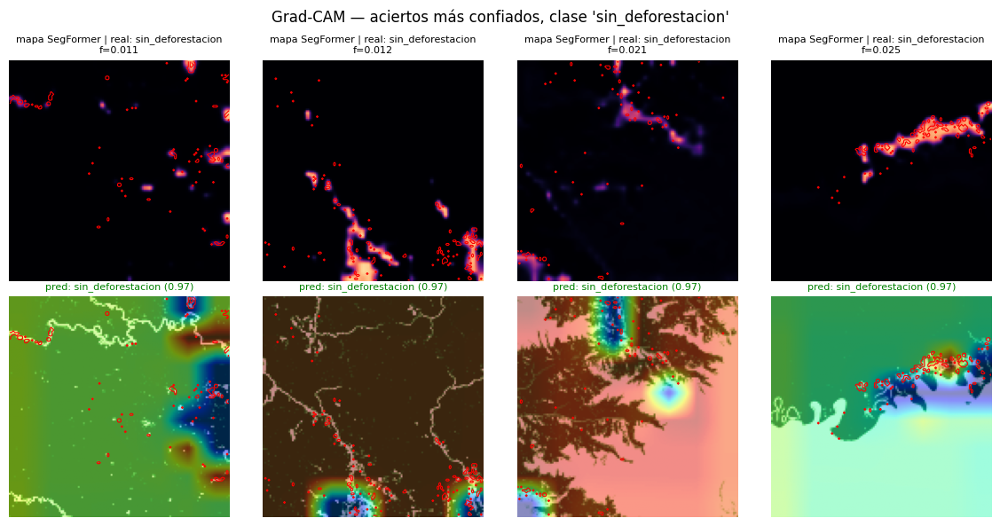

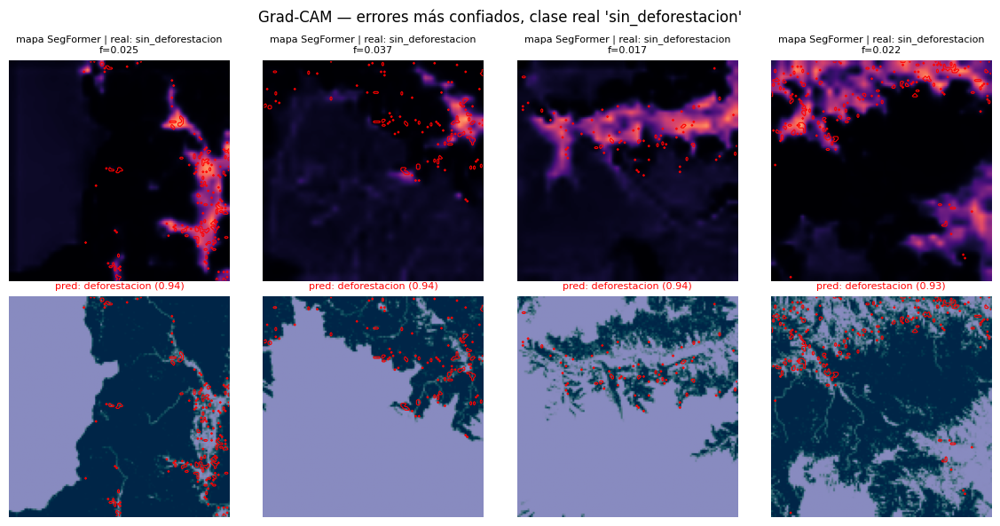

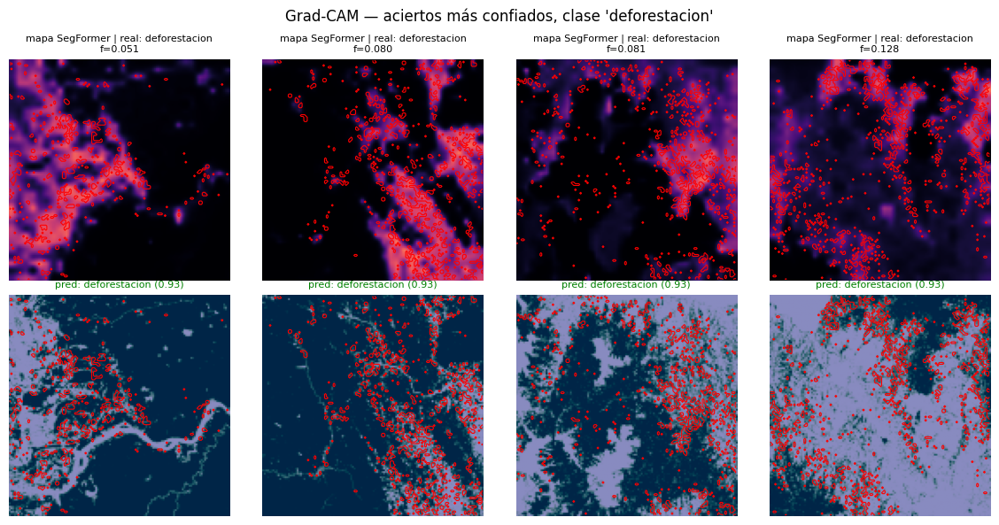

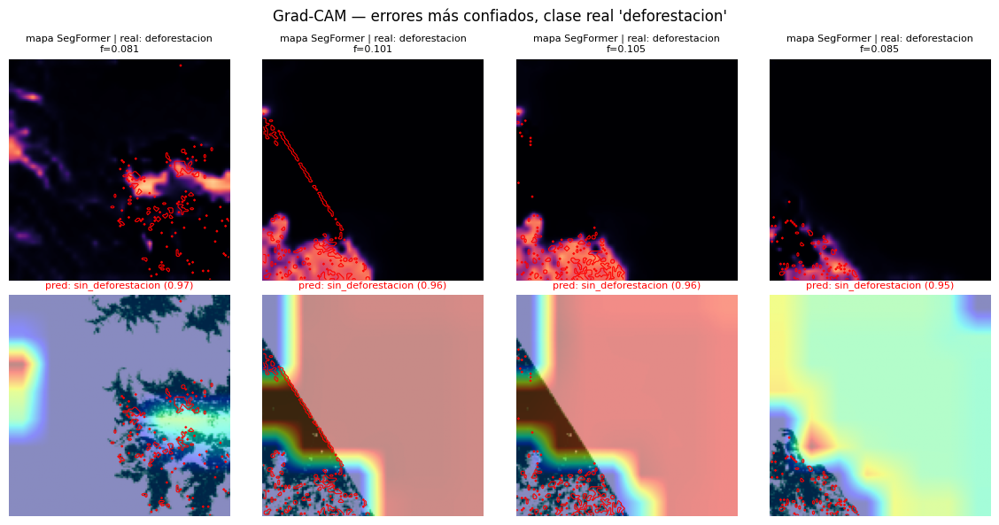

In [16]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("10.1", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.h = layer.register_forward_hook(self._fwd)
    def _fwd(self, module, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, class_idx=None):
        self.model.eval()
        x = x.detach().to(DEVICE).clone().requires_grad_(True)
        logits = self.model(x)
        if class_idx is None: class_idx = logits.argmax(1)
        self.model.zero_grad(set_to_none=True)
        logits.gather(1, class_idx.view(-1, 1).to(DEVICE)).sum().backward()
        w = self.grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        mn, mx = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
        return ((cam - mn) / (mx - mn + 1e-8)).detach().cpu(), logits.softmax(1).detach().cpu()
    def remove(self): self.h.remove()

gradcam = GradCAM(model, model.bott)

def show_cams(df_rows, title, fname):
    if len(df_rows) == 0:
        print(f"(sin ejemplos para: {title})"); return
    n = len(df_rows)
    fig, axes = plt.subplots(2, n, figsize=(2.9 * n, 6.0), squeeze=False)
    for j, (_, r) in enumerate(df_rows.iterrows()):
        x, _, _ = hold_ds[pos_of[r.indice]]
        cam, _ = gradcam(x[None], torch.tensor([CLS2IDX[r.clase_predicha]]))
        img = rgb_image(HOLDOUT_NAME, r.indice); m = loss_mask(HOLDOUT_NAME, r.indice)
        axes[0, j].imshow(seg_map(r.indice), cmap="magma", vmin=0, vmax=1)
        axes[0, j].set_title(f"mapa {ARCH_LABEL} | real: {r.clase_real}\nf={r.frac_perdida:.3f}", fontsize=8)
        axes[1, j].imshow(img); axes[1, j].imshow(cam[0], cmap="jet", alpha=0.45)
        for a in axes[:, j]:
            if m is not None and m.any(): a.contour(m, levels=[0.5], colors="red", linewidths=0.8)
            a.axis("off")
        axes[1, j].set_title(f"pred: {r.clase_predicha} ({r.confianza:.2f})", fontsize=8, color="green" if r.correcto else "red")
    plt.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

for c in CLASSES:
    ok  = pred_df[(pred_df.clase_real == c) & pred_df.correcto].nlargest(4, "confianza")
    err = pred_df[(pred_df.clase_real == c) & ~pred_df.correcto].nlargest(4, "confianza")
    show_cams(ok,  f"Grad-CAM — aciertos más confiados, clase '{c}'", f"gradcam_aciertos_{c}")
    show_cams(err, f"Grad-CAM — errores más confiados, clase real '{c}'", f"gradcam_errores_{c}")
''')


### 10.2 Localización: mapa de segmentación y Grad-CAM vs. la pérdida real
Se comparan dos mapas con la máscara real en parches de `val` con pérdida: el **mapa de probabilidad del segmentador** (supervisado por píxel) y el **Grad-CAM** de la cabeza de clasificación (explica qué regiones usa la decisión del parche). Métricas:
- **Pointing game**: ¿el píxel de máxima activación cae dentro de la máscara? Se compara con el azar (= fracción de pérdida del parche).
- **Energía dentro de la máscara**: proporción de la "masa" de Grad-CAM sobre la máscara frente al área de la máscara (*lift* > 1 = mejor que el azar).
- **IoU** entre Grad-CAM binarizado (≥ 0.5) y la máscara.


===== 10.2 | swin_unetr =====


,metodo,pointing_game,energia_en_mascara,iou,lift_mediano,azar (área),parches
0,Grad-CAM,0.045,0.0370,0.0300,0.6749,0.0255,200
1,Mapa segmentación,0.285,0.1177,0.1016,5.3949,0.0255,200


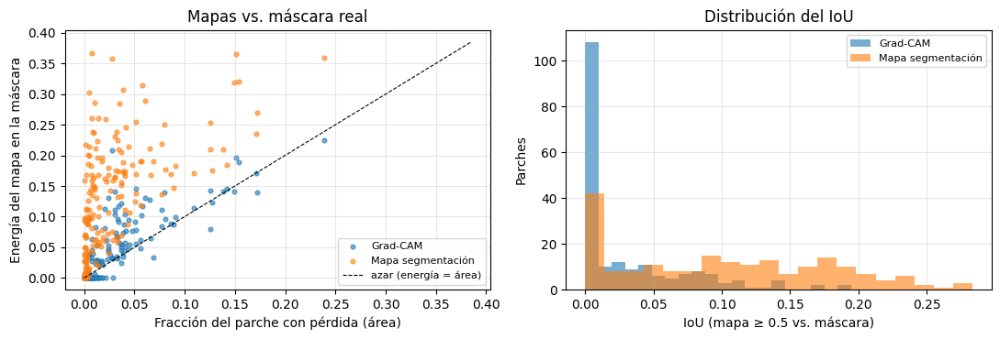


===== 10.2 | segformer =====


,metodo,pointing_game,energia_en_mascara,iou,lift_mediano,azar (área),parches
0,Grad-CAM,0.030,0.0102,0.0095,0.8340,0.0255,200
1,Mapa segmentación,0.235,0.0947,0.0734,3.4378,0.0255,200


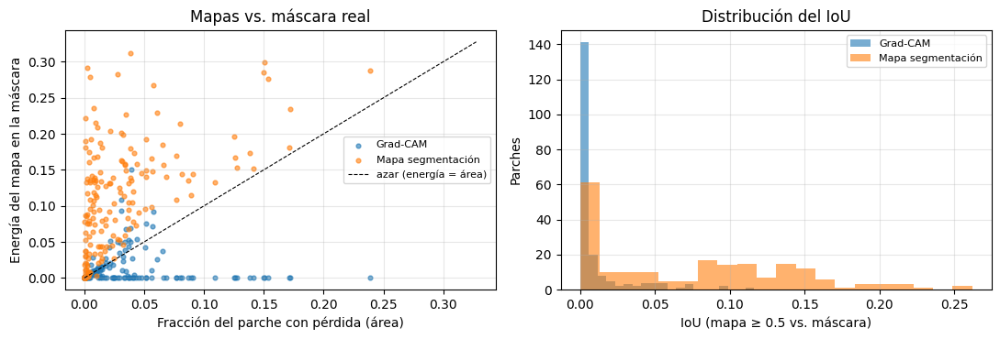

In [17]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("10.2", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
loc_df = pd.DataFrame()
if Y_KIND == "mascara" and "deforestacion" in CLS2IDX:
    POS = CLS2IDX["deforestacion"]
    cand = [t for t in holdout if FRAC[HOLDOUT_NAME][t[1]] > 0]
    cand = random.Random(SEED).sample(cand, min(GRADCAM_LOC_SAMPLES, len(cand)))
    rows = []
    for s, i, y in cand:
        x, _, _ = hold_ds[pos_of[i]]
        m = loss_mask(s, i); area = m.mean()
        maps = {"Grad-CAM": None, "Mapa segmentación": seg_map(i)}
        cam, prob = gradcam(x[None], torch.tensor([POS])); maps["Grad-CAM"] = cam[0].numpy()
        for metodo, mp in maps.items():
            mp_n = (mp - mp.min()) / (mp.max() - mp.min() + 1e-8)
            energy = (mp_n * m).sum() / (mp_n.sum() + 1e-8)
            b = mp >= 0.5; iou = (b & m).sum() / max(1, (b | m).sum())
            rows.append(dict(metodo=metodo, indice=i, frac_perdida=area, etiqueta=CLASSES[y], prob_deforestacion=float(prob[0, POS]),
                             pointing_hit=bool(m.flat[mp.argmax()]), energia_en_mascara=energy,
                             lift_energia=energy / max(area, 1e-8), iou=iou))
    loc_all = pd.DataFrame(rows); loc_all.to_csv(OUT / "tables" / "gradcam_localizacion_detalle.csv", index=False)
    azar = loc_all.groupby("metodo").frac_perdida.mean()
    loc_sum = loc_all.groupby("metodo").agg(pointing_game=("pointing_hit", "mean"), energia_en_mascara=("energia_en_mascara", "mean"),
                                            iou=("iou", "mean"), lift_mediano=("lift_energia", "median")).reset_index()
    loc_sum["azar (área)"] = loc_sum.metodo.map(azar); loc_sum["parches"] = len(cand)
    display(loc_sum.round(4)); save_table(loc_sum, "gradcam_localizacion")
    loc_df = loc_all[loc_all.metodo == "Mapa segmentación"].copy()   # mapa de segmentación (usado en el resumen y en MLflow)

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for metodo, d in loc_all.groupby("metodo"):
        ax[0].scatter(d.frac_perdida, d.energia_en_mascara, s=12, alpha=.6, label=metodo)
        ax[1].hist(d.iou, bins=20, alpha=.6, label=metodo)
    lim = max(loc_all.frac_perdida.max(), loc_all.energia_en_mascara.max()) * 1.05
    ax[0].plot([0, lim], [0, lim], "k--", lw=.8, label="azar (energía = área)")
    ax[0].set_xlabel("Fracción del parche con pérdida (área)"); ax[0].set_ylabel("Energía del mapa en la máscara")
    ax[0].set_title("Mapas vs. máscara real"); ax[0].legend(fontsize=8)
    ax[1].set_xlabel("IoU (mapa ≥ 0.5 vs. máscara)"); ax[1].set_ylabel("Parches"); ax[1].set_title("Distribución del IoU"); ax[1].legend(fontsize=8)
    for a in ax: a.grid(alpha=.3)
    plt.tight_layout(); savefig("gradcam_localizacion"); plt.show()
else:
    print("Y no es una máscara de pérdida: se omite la evaluación de localización.")
''')


### 10.3 Fidelidad de Grad-CAM: prueba de borrado
Se ocultan (valor 0 = media de `train` tras estandarizar) fracciones crecientes de píxeles, primero los más relevantes según Grad-CAM y, como control, al azar. Si la probabilidad cae más rápido con Grad-CAM (menor AUC), el mapa es **fiel** a lo que usa el modelo.


===== 10.3 | swin_unetr =====


,metodo,auc_borrado,d_e,imagenes
0,Grad-CAM,0.5930,0.1697,64
1,Aleatorio,0.6812,0.0877,64


Grad-CAM más fiel que el azar en 79.7% de los parches


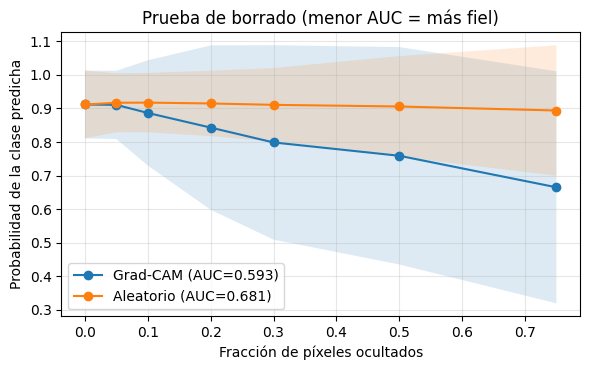


===== 10.3 | segformer =====


,metodo,auc_borrado,d_e,imagenes
0,Grad-CAM,0.5104,0.1754,64
1,Aleatorio,0.6920,0.0799,64


Grad-CAM más fiel que el azar en 87.5% de los parches


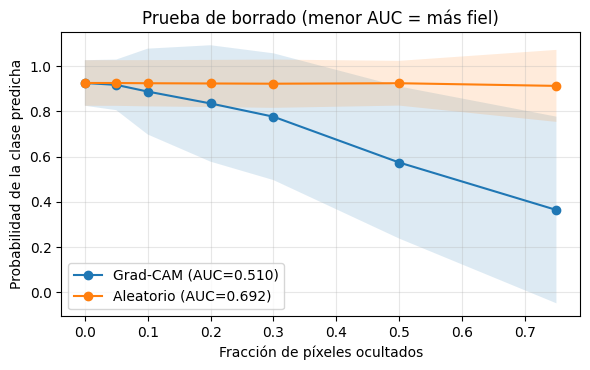

In [18]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("10.3", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
FRACS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75]

@torch.no_grad()
def deletion_curve(x, cam, cls, mode, gen):
    Hh, Ww = cam.shape; n = Hh * Ww
    order = torch.argsort(cam.flatten(), descending=True) if mode == "cam" else torch.randperm(n, generator=gen)
    xs = []
    for f in FRACS:
        k = int(f * n); xm = x.clone()
        if k > 0:
            mask = torch.zeros(n, dtype=torch.bool); mask[order[:k]] = True
            xm = xm.masked_fill(mask.view(1, 1, Hh, Ww), 0.0)
        xs.append(xm)
    return model.eval()(torch.cat(xs).to(DEVICE)).softmax(1)[:, cls].cpu().numpy()

gen = torch.Generator().manual_seed(SEED)
sub = random.Random(SEED).sample(range(len(holdout)), min(GRADCAM_FIDELITY_SAMPLES, len(holdout)))
curves = {"cam": [], "random": []}
for j in sub:
    x = hold_ds[j][0][None]
    cam, prob = gradcam(x); cls = int(prob.argmax(1))
    for mode in curves:
        curves[mode].append(deletion_curve(x, cam[0], cls, mode, gen))
curves = {k: np.array(v) for k, v in curves.items()}
auc_del = {k: _trapz(v.mean(0), FRACS) for k, v in curves.items()}
per_img = {k: np.array([_trapz(c, FRACS) for c in v]) for k, v in curves.items()}
fid = pd.DataFrame([dict(metodo="Grad-CAM", auc_borrado=auc_del["cam"], d_e=per_img["cam"].std()),
                    dict(metodo="Aleatorio", auc_borrado=auc_del["random"], d_e=per_img["random"].std())])
fid["imagenes"] = len(sub); display(fid.round(4)); save_table(fid, "fidelidad_gradcam")
print(f"Grad-CAM más fiel que el azar en {(per_img['cam'] < per_img['random']).mean():.1%} de los parches")

fig, ax = plt.subplots(figsize=(6, 3.8))
for k, lbl in [("cam", "Grad-CAM"), ("random", "Aleatorio")]:
    mu, sd = curves[k].mean(0), curves[k].std(0)
    ax.plot(FRACS, mu, "o-", label=f"{lbl} (AUC={auc_del[k]:.3f})"); ax.fill_between(FRACS, mu - sd, mu + sd, alpha=.15)
ax.set_xlabel("Fracción de píxeles ocultados"); ax.set_ylabel("Probabilidad de la clase predicha")
ax.set_title("Prueba de borrado (menor AUC = más fiel)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); savefig("fidelidad_gradcam"); plt.show()
gradcam.remove()
''')


### 10.4 Calibración y confianza


===== 10.4 | swin_unetr =====
ECE = 0.0414


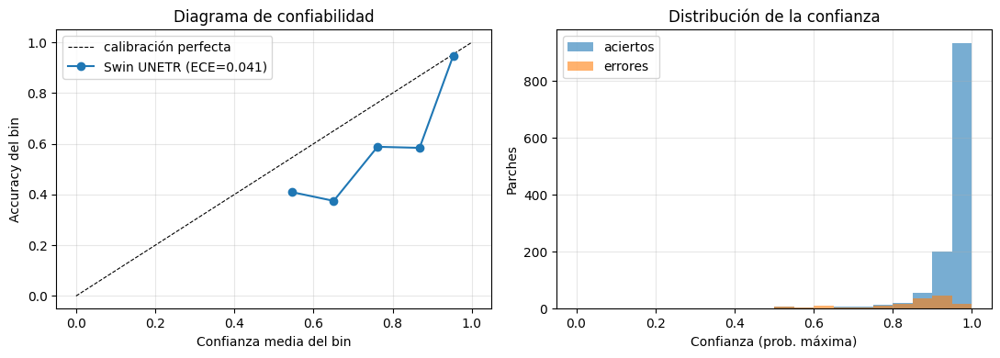


===== 10.4 | segformer =====
ECE = 0.0530


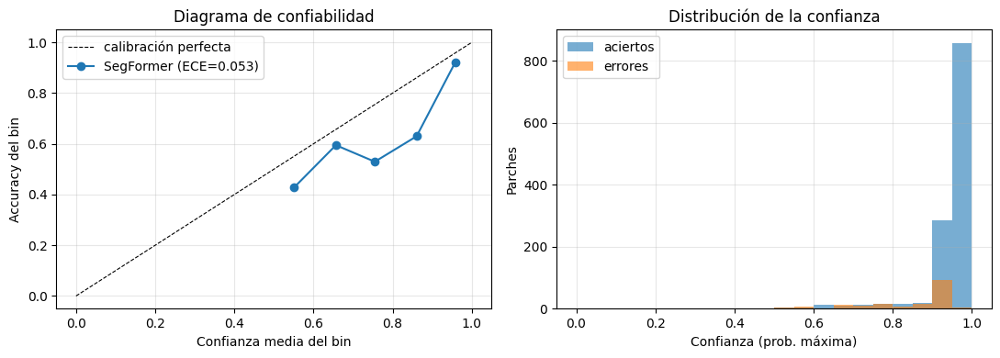

In [19]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("10.4", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
def ece_score(conf, correct, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); e, rows = 0.0, []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean()); rows.append((conf[m].mean(), correct[m].mean(), m.sum()))
    return e, np.array(rows)

conf, correct = p_hold.max(1), (pred_hold == y_hold).astype(float)
ece, rel = ece_score(conf, correct); print(f"ECE = {ece:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([0, 1], [0, 1], "k--", lw=.8, label="calibración perfecta")
ax[0].plot(rel[:, 0], rel[:, 1], "o-", label=f"{ARCH_LABEL} (ECE={ece:.3f})")
ax[0].set_xlabel("Confianza media del bin"); ax[0].set_ylabel("Accuracy del bin"); ax[0].set_title("Diagrama de confiabilidad"); ax[0].legend()
ax[1].hist(conf[correct == 1], bins=20, range=(0, 1), alpha=.6, label="aciertos")
ax[1].hist(conf[correct == 0], bins=20, range=(0, 1), alpha=.6, label="errores")
ax[1].set_xlabel("Confianza (prob. máxima)"); ax[1].set_ylabel("Parches"); ax[1].set_title("Distribución de la confianza"); ax[1].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); savefig("calibracion"); plt.show()
''')


### 10.5 Espacio latente (t-SNE de los *embeddings* del *bottleneck*)


===== 10.5 | swin_unetr =====


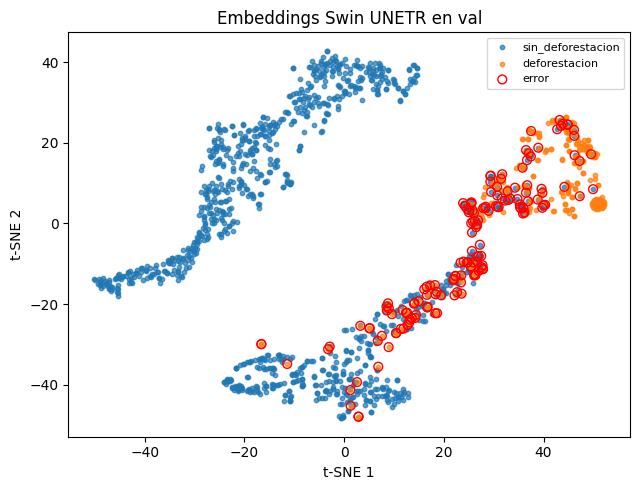


===== 10.5 | segformer =====


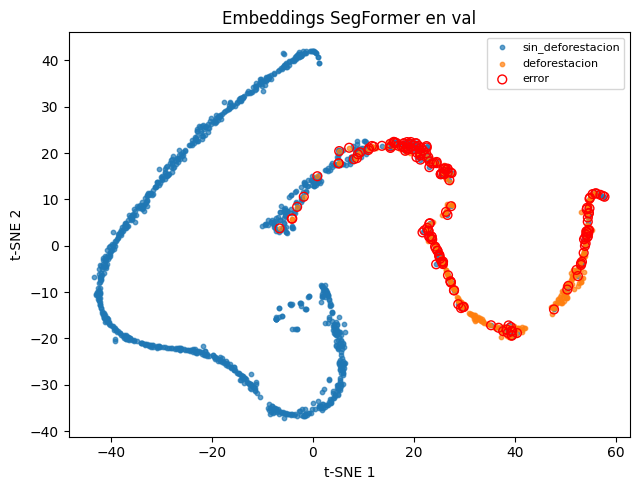

In [20]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("10.5", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
from sklearn.manifold import TSNE
E, yE = extract_features(Embedder(model), holdout)
n_max = min(2000, len(E)); sel_i = np.random.RandomState(SEED).choice(len(E), n_max, replace=False)
Z = TSNE(n_components=2, perplexity=min(30, max(5, n_max // 4)), init="pca", random_state=SEED).fit_transform(E[sel_i])
err_sel = pred_hold[sel_i] != y_hold[sel_i]
fig, ax = plt.subplots(figsize=(6.5, 5))
for k, c in enumerate(CLASSES):
    m = yE[sel_i] == k; ax.scatter(Z[m, 0], Z[m, 1], s=10, alpha=.7, label=c)
ax.scatter(Z[err_sel, 0], Z[err_sel, 1], s=40, facecolors="none", edgecolors="red", lw=1, label="error")
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.set_title(f"Embeddings {ARCH_LABEL} en {HOLDOUT_NAME}"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("tsne_embeddings"); plt.show()
''')


### 10.6 Análisis sistemático de errores
¿Los errores se concentran cerca del umbral $\tau$ (etiquetas ambiguas), en parches con muchos píxeles inválidos (nubes, sin dato) o con poca pérdida visible?


===== 10.6 | swin_unetr =====


,clase_real,n,tasa_error
0,deforestacion,297,0.2492
1,sin_deforestacion,1105,0.0751


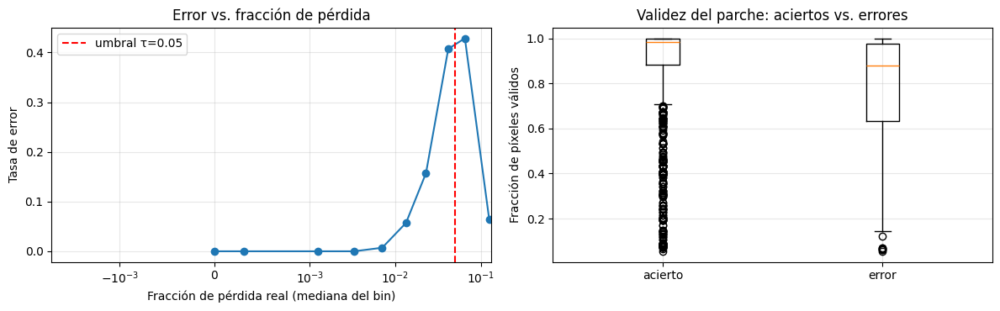

Tasa de error cerca del umbral (|f-τ|<τ): 0.126 | lejos del umbral: 0.033

===== 10.6 | segformer =====


,clase_real,n,tasa_error
0,deforestacion,297,0.0606
1,sin_deforestacion,1105,0.1357


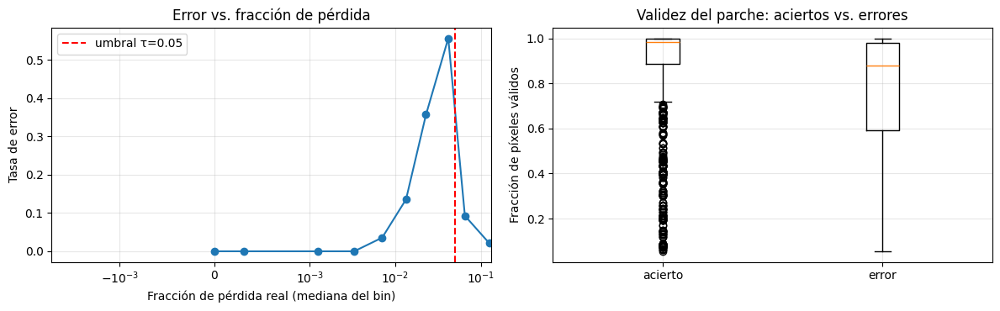

Tasa de error cerca del umbral (|f-τ|<τ): 0.139 | lejos del umbral: 0.009


In [21]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("10.6", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
ea = pred_df.copy()
err_by_class = ea.groupby("clase_real").agg(n=("correcto", "size"), tasa_error=("correcto", lambda s: 1 - s.mean())).reset_index()
display(err_by_class.round(4)); save_table(err_by_class, "tasa_error_por_clase")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
if Y_KIND != "clase":
    edges = np.unique(np.quantile(ea.frac_perdida, np.linspace(0, 1, 11)))
    if len(edges) > 2:
        ea["bin_frac"] = pd.cut(ea.frac_perdida, edges, include_lowest=True, duplicates="drop")
        eb = ea.groupby("bin_frac", observed=True).agg(tasa_error=("correcto", lambda s: 1 - s.mean()), n=("correcto", "size"),
                                                        centro=("frac_perdida", "median")).reset_index()
        ax[0].plot(eb.centro, eb.tasa_error, "o-")
        ax[0].axvline(FRAC_THRESHOLD, c="r", ls="--", label=f"umbral τ={FRAC_THRESHOLD}")
        ax[0].set_xscale("symlog", linthresh=1e-3); ax[0].legend()
        save_table(eb.astype({"bin_frac": str}), "error_por_fraccion")
    ax[0].set_xlabel("Fracción de pérdida real (mediana del bin)"); ax[0].set_ylabel("Tasa de error"); ax[0].set_title("Error vs. fracción de pérdida")
data = [ea.loc[ea.correcto, "frac_valida"], ea.loc[~ea.correcto, "frac_valida"]]
if len(data[1]) and len(data[0]):
    ax[1].boxplot(data); ax[1].set_xticks([1, 2]); ax[1].set_xticklabels(["acierto", "error"])
ax[1].set_ylabel("Fracción de píxeles válidos"); ax[1].set_title("Validez del parche: aciertos vs. errores")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); savefig("analisis_errores"); plt.show()

near = (ea.frac_perdida - FRAC_THRESHOLD).abs() < FRAC_THRESHOLD if Y_KIND != "clase" else pd.Series(False, index=ea.index)
if near.any():
    print(f"Tasa de error cerca del umbral (|f-τ|<τ): {1 - ea[near].correcto.mean():.3f} | lejos del umbral: {1 - ea[~near].correcto.mean():.3f}")
ea.to_csv(OUT / "tables" / "analisis_errores_detalle.csv", index=False)
''')


## 11. Costo computacional (R6)

In [22]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("11", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
try:
    import psutil; ram = f"{psutil.virtual_memory().total / 1e9:.1f} GB"
except ImportError:
    ram = "N/D"
hw = {"GPU": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "ninguna (CPU)",
      "VRAM": f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB" if DEVICE.type == "cuda" else "N/D",
      "CPU": platform.processor() or platform.machine(), "núcleos CPU": os.cpu_count(), "RAM": ram,
      "Python": platform.python_version(), "PyTorch": torch.__version__, "CUDA": torch.version.cuda or "N/D"}
display(pd.Series(hw, name="valor").to_frame())

comp_log = pd.DataFrame(COMPUTE_LOG)
by_group = comp_log.groupby("grupo", sort=False).segundos.sum().to_frame(); by_group["horas"] = by_group.segundos / 3600
by_group.loc["TOTAL"] = by_group.sum(); total_h = by_group.loc["TOTAL", "horas"]
energy = GPU_POWER_W * total_h / 1000 if DEVICE.type == "cuda" else float("nan")
display(by_group.round(4))

n_params = sum(p.numel() for p in model.parameters())
model.eval()
xb1 = torch.randn(1, C_IN, H, W, device=DEVICE); xbB = torch.randn(BATCH_SIZE, C_IN, H, W, device=DEVICE)
def bench(x, reps=20):
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        for _ in range(3): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t = time.time()
        for _ in range(reps): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / reps
lat1, latB = bench(xb1), bench(xbB)
cost = pd.DataFrame([
    (f"Parámetros {ARCH_LABEL}", f"{n_params / 1e6:.2f} M"),
    ("Tiempo entrenamiento modelo principal", f"{by_group.loc['principal', 'horas'] if 'principal' in by_group.index else 0:.3f} h"),
    ("Tiempo total de entrenamientos", f"{total_h:.3f} h"),
    ("Horas de GPU aproximadas", f"{total_h:.3f} h" if DEVICE.type == "cuda" else "0 (CPU)"),
    ("Energía estimada (GPU)", f"{energy:.3f} kWh (supone {GPU_POWER_W} W)"),
    ("CO₂ estimado", f"{energy * GRID_KG_CO2_PER_KWH:.3f} kg (factor {GRID_KG_CO2_PER_KWH} kg/kWh)"),
    ("Latencia de inferencia (1 parche)", f"{lat1 * 1000:.1f} ms"),
    (f"Throughput (lote {BATCH_SIZE})", f"{BATCH_SIZE / latB:.0f} parches/s")], columns=["concepto", "valor"])
display(cost); save_table(cost, "costo_computacional"); save_table(comp_log, "costo_por_etapa")
save_table(pd.Series(hw).to_frame("valor").reset_index().rename(columns={"index": "componente"}), "hardware")
''')



===== 11 | swin_unetr =====


,valor
GPU,Tesla T4
VRAM,15.6 GB
CPU,x86_64
núcleos CPU,4
RAM,33.7 GB
Python,3.13.16
PyTorch,2.11.0+cu130
CUDA,13.0


,segundos,horas
grupo,,
principal,1440.1179,0.4000
línea base,208.5360,0.0579
ablación,17320.8102,4.8113
TOTAL,18969.4641,5.2693


,concepto,valor
0,Parámetros Swin UNETR,6.32 M
1,Tiempo entrenamiento modelo principal,0.400 h
2,Tiempo total de entrenamientos,5.269 h
3,Horas de GPU aproximadas,5.269 h
4,Energía estimada (GPU),0.369 kWh (supone 70 W)
5,CO₂ estimado,0.092 kg (factor 0.25 kg/kWh)
6,Latencia de inferencia (1 parche),20.5 ms
7,Throughput (lote 4),198 parches/s



===== 11 | segformer =====


,valor
GPU,Tesla T4
VRAM,15.6 GB
CPU,x86_64
núcleos CPU,4
RAM,33.7 GB
Python,3.13.16
PyTorch,2.11.0+cu130
CUDA,13.0


,segundos,horas
grupo,,
principal,1218.7264,0.3385
línea base,207.2162,0.0576
ablación,13507.4884,3.7521
TOTAL,14933.4310,4.1482


,concepto,valor
0,Parámetros SegFormer,3.76 M
1,Tiempo entrenamiento modelo principal,0.339 h
2,Tiempo total de entrenamientos,4.148 h
3,Horas de GPU aproximadas,4.148 h
4,Energía estimada (GPU),0.290 kWh (supone 70 W)
5,CO₂ estimado,0.073 kg (factor 0.25 kg/kWh)
6,Latencia de inferencia (1 parche),11.4 ms
7,Throughput (lote 4),429 parches/s


## 12. Resumen y archivos para el repositorio

In [23]:
# Ejecuta esta etapa para ambas arquitecturas, con resultados separados.
run_for_models("12", r'''
assert globals().get("TRAIN_RUN_ID") and globals().get("EVALUATED_RUN_ID") == TRAIN_RUN_ID, "Ejecuta las secciones 6 a 12 después del último entrenamiento."
summary = {
    "datos": str(DATA_DIR), "layout": LAYOUT, "parche": [int(H), int(W)], "bandas": BAND_NAMES,
    "entrada": [BAND_NAMES[i] for i in CH_ORDER], "excluidas": [BAND_NAMES[i] for i in EXCLUDED], "tipo_Y": Y_KIND, "umbral_frac": FRAC_THRESHOLD, "clases": CLASSES,
    "n_train": len(train_s), "n_val_interna": len(ival_s), "conjunto_evaluacion": HOLDOUT_NAME, "n_evaluacion": len(holdout),
    "modelo": ARCH_LABEL, "parametros_M": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
    "arquitectura": {k: v for k, v in CONFIG.items() if k.startswith(("ARCH_TYPE", "SWIN_", "SEGF_"))},
    ARCH: {k: round(float(v), 4) for k, v in m_hold.items()},
    "segmentacion": {k: round(float(v), 4) for k, v in seg_hold.items()}, "mejor_epoca": info["best_epoch"],
    "lineas_base_f1": {r["modelo"]: round(float(r["f1_macro"]), 4) for r in baseline_rows},
    "ece": round(float(ece), 4), "gradcam_auc_borrado": {k: round(float(v), 4) for k, v in auc_del.items()},
    "horas_computo_total": round(float(total_h), 4), "hardware": hw}
if len(loc_df):
    summary["localizacion"] = {r.metodo: {"pointing_game": round(float(r.pointing_game), 4), "iou": round(float(r.iou), 4)}
                               for r in loc_sum.itertuples()}
if len(abl):
    summary["ablaciones_f1_val_media"] = abl.groupby("variante", sort=False).val_f1.mean().round(4).to_dict()
(OUT / "resumen.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))

best_base = max([r for r in baseline_rows if "propuesto" not in r["modelo"]], key=lambda r: r["f1_macro"], default=None)
txt = (f"Sobre el conjunto {HOLDOUT_NAME} ({len(holdout)} parches de {H}×{W} px y {C_IN} capas), la {ARCH_LABEL} "
       f"alcanzó por parche un F1-macro de {m_hold['f1_macro']:.3f}, accuracy de {m_hold['accuracy']:.3f}, balanced accuracy de "
       f"{m_hold['balanced_acc']:.3f} y AUC-ROC de {m_hold['auc']:.3f}; en segmentación obtuvo IoU de {seg_hold['iou_pix']:.3f} "
       f"y Dice de {seg_hold['dice_pix']:.3f}")
if best_base: txt += f", frente a {best_base['f1_macro']:.3f} de la mejor línea base ({best_base['modelo']})"
txt += f". El ECE fue {ece:.3f}."
if len(loc_df):
    _u = loc_df
    txt += (f" El máximo del mapa de {ARCH_LABEL} cayó dentro de la pérdida real en el {_u.pointing_hit.mean():.1%} de los parches "
            f"con deforestación (azar: {_u.frac_perdida.mean():.1%}).")
txt += (f" En la prueba de borrado, Grad-CAM obtuvo un AUC de {auc_del['cam']:.3f} frente a {auc_del['random']:.3f} del azar. "
        f"El entrenamiento total requirió {total_h:.2f} h en {hw['GPU']}.")
print(txt); (OUT / "parrafo_resultados.txt").write_text(txt)

from importlib.metadata import version, PackageNotFoundError
req = []
for p in ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "matplotlib", "joblib"]:
    try: req.append(f"{p}=={version(p)}")
    except PackageNotFoundError: pass
(OUT / "requirements.txt").write_text("\n".join(req) + "\n"); print("\n".join(req))

import shutil
shutil.make_archive(str(ROOT_OUT / f"results_{ARCH}"), "zip", OUT)
print("Archivos en results/:", len([p for p in OUT.rglob("*") if p.is_file()]))
print(f"Entregables {ARCH} guardados en {OUT} y {ROOT_OUT}.")
SUMMARY_RUN_ID = TRAIN_RUN_ID

''')



===== 12 | swin_unetr =====
Sobre el conjunto val (1402 parches de 128×128 px y 31 capas), la Swin UNETR alcanzó por parche un F1-macro de 0.834, accuracy de 0.888, balanced accuracy de 0.838 y AUC-ROC de 0.937; en segmentación obtuvo IoU de 0.158 y Dice de 0.272, frente a 0.867 de la mejor línea base (Random Forest (estadísticos por banda)). El ECE fue 0.041. El máximo del mapa de Swin UNETR cayó dentro de la pérdida real en el 28.5% de los parches con deforestación (azar: 2.6%). En la prueba de borrado, Grad-CAM obtuvo un AUC de 0.593 frente a 0.681 del azar. El entrenamiento total requirió 5.27 h en Tesla T4.
torch==2.11.0+cu130
torchvision==0.26.0+cu130
numpy==2.1.3
pandas==2.3.3
scikit-learn==1.6.1
matplotlib==3.10.0
joblib==1.6.0
Archivos en results/: 75
Entregables swin_unetr guardados en /kaggle/working/entrega_dos_modelos/20261106_050703_17b070d9/swin_unetr y /kaggle/working/entrega_dos_modelos/20261106_050703_17b070d9.

===== 12 | segformer =====
Sobre el conjunto val (1402 

### 12.1 Comparación consolidada de ambos modelos
Se reúnen métricas de val/test, líneas base, resultados por semilla y gráficos comparativos. Las épocas se seleccionan con validación interna, no con test.


,conjunto,accuracy,balanced_acc,f1_macro,precision_macro,recall_macro,f1_weighted,mcc,kappa,auc,iou_pix,dice_pix,precision_pix,recall_pix,ap_pix,arquitectura
0,val,0.8880,0.8379,0.8342,0.8306,0.8379,0.8886,0.6684,0.6683,0.9365,0.1575,0.2722,0.2392,0.3157,0.1977,swin_unetr
1,test,0.8880,0.8408,0.8171,0.7989,0.8408,0.8917,0.6383,0.6348,0.9050,0.1376,0.2419,0.2022,0.3010,0.1701,swin_unetr
2,val,0.8802,0.9018,0.8439,0.8159,0.9018,0.8873,0.7126,0.6913,0.9466,0.1086,0.1959,0.2082,0.1850,0.1725,segformer
3,test,0.8445,0.8684,0.7831,0.7529,0.8684,0.8587,0.6104,0.5751,0.9183,0.1032,0.1871,0.1766,0.1989,0.1475,segformer


,modelo,accuracy,balanced_acc,f1_macro,precision_macro,recall_macro,f1_weighted,mcc,kappa,auc,arquitectura
0,Random Forest (estadísticos por banda),0.9066,0.8853,0.8667,0.8516,0.8853,0.9087,0.7362,0.7336,0.9655,swin_unetr
1,Reg. logística (estadísticos por banda),0.8909,0.8766,0.8483,0.8283,0.8766,0.8946,0.7032,0.6974,0.9595,swin_unetr
2,Swin UNETR (propuesto),0.8880,0.8379,0.8342,0.8306,0.8379,0.8886,0.6684,0.6683,0.9365,swin_unetr
3,Random Forest (estadísticos por banda),0.9066,0.8853,0.8667,0.8516,0.8853,0.9087,0.7362,0.7336,0.9655,segformer
4,Reg. logística (estadísticos por banda),0.8909,0.8766,0.8483,0.8283,0.8766,0.8946,0.7032,0.6974,0.9595,segformer
5,SegFormer (propuesto),0.8802,0.9018,0.8439,0.8159,0.9018,0.8873,0.7126,0.6913,0.9466,segformer


val_interna_f1  \
                                                                  mean   
arquitectura variante                                                    
segformer    Arquitectura alternativa (Swin UNETR)            0.813654   
             Completo                                         0.789848   
             Menor capacidad (anchos × 0.5)                   0.813811   
             Sin data augmentation                            0.815325   
             Sin pesos de clase ni LS                         0.806975   
             Sin pérdida de segmentación                      0.760411   
             Sin reducción espacial (atención completa)       0.807397   
swin_unetr   Arquitectura alternativa (SegFormer)             0.809673   
             Completo                                         0.813654   
             Menor capacidad (anchos × 0.5)                   0.834167   
             Sin data augmentation                            0.827283   
             Sin pesos de clase ni LS                         0.827017   
             Sin pérdida de segmentación                      0.806609   
             Sin ventanas desplazadas                         0.821614   

                                                                     val_f1  \
                                                              std      mean   
arquitectura variante                                                         
segformer    Arquitectura alternativa (Swin UNETR)       0.002111  0.861662   
             Completo                                    0.025856  0.836578   
             Menor capacidad (anchos × 0.5)              0.003288  0.859313   
             Sin data augmentation                       0.005911  0.860055   
             Sin pesos de clase ni LS                    0.005719  0.855477   
             Sin pérdida de segmentación                 0.013463  0.806602   
             Sin reducción espacial (atención completa)  0.004911  0.851448   
swin_unetr   Arquitectura alternativa (SegFormer)        0.002145  0.864783   
             Completo                                    0.002111  0.861662   
             Menor capacidad (anchos × 0.5)              0.009606  0.866746   
             Sin data augmentation                       0.004921  0.863906   
             Sin pesos de clase ni LS                    0.010074  0.861480   
             Sin pérdida de segmentación                 0.009681  0.865333   
             Sin ventanas desplazadas                    0.015593  0.863548   

                                                                  val_iou_pix  \
                                                              std        mean   
arquitectura variante                                                           
segformer    Arquitectura alternativa (Swin UNETR)       0.002368    0.157910   
             Completo                                    0.040613    0.111532   
             Menor capacidad (anchos × 0.5)              0.006139    0.121343   
             Sin data augmentation                       0.009332    0.110713   
             Sin pesos de clase ni LS                    0.006051    0.109267   
             Sin pérdida de segmentación                 0.022602    0.024878   
             Sin reducción espacial (atención completa)  0.008401    0.116482   
swin_unetr   Arquitectura alternativa (SegFormer)        0.004257    0.114598   
             Completo                                    0.002368    0.157910   
             Menor capacidad (anchos × 0.5)              0.004625    0.153971   
             Sin data augmentation                       0.015691    0.158804   
             Sin pesos de clase ni LS                    0.011646    0.159275   
             Sin pérdida de segmentación                 0.013303    0.024523   
             Sin ventanas desplazadas                    0.013064    0.154966   

                                                                   
       

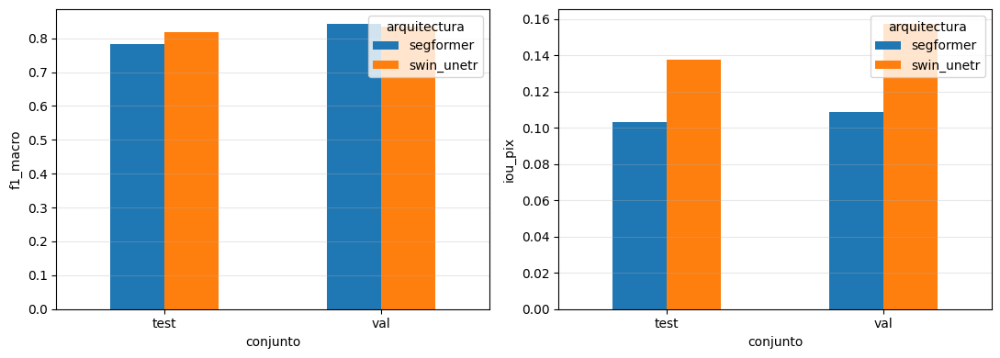

La selección de épocas utiliza F1 interno. Las métricas val/test se reportan sin usarlas para ajustar variantes.


In [24]:
comparison = pd.concat([ctx["res_main"].assign(arquitectura=arch) for arch, ctx in MODELS.items()], ignore_index=True)
comparison.to_csv(ROOT_OUT / "comparacion_modelos_val_test.csv", index=False)
display(comparison.round(4))
baseline_comparison = pd.concat([ctx["comp"].assign(arquitectura=arch) for arch, ctx in MODELS.items()], ignore_index=True)
baseline_comparison.to_csv(ROOT_OUT / "comparacion_lineas_base.csv", index=False)
display(baseline_comparison.round(4))
if all(len(ctx["abl"]) for ctx in MODELS.values()):
    all_ablations = pd.concat([ctx["abl"].assign(arquitectura=arch) for arch, ctx in MODELS.items()], ignore_index=True)
    all_ablations.to_csv(ROOT_OUT / "comparacion_ablaciones_semillas.csv", index=False)
    display(all_ablations.groupby(["arquitectura", "variante"])[["val_interna_f1", "val_f1", "val_iou_pix"]].agg(["mean", "std"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, metric in zip(axes, ["f1_macro", "iou_pix"]):
    table = comparison.pivot(index="conjunto", columns="arquitectura", values=metric)
    table.plot.bar(ax=axis, rot=0)
    axis.set_ylabel(metric)
    axis.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT_OUT / "comparacion_modelos.png", dpi=200, bbox_inches="tight")
plt.show()
print("La selección de épocas utiliza F1 interno. Las métricas val/test se reportan sin usarlas para ajustar variantes.")


## 13. Discusión, limitaciones, sesgos y uso responsable
Completa con los números de las celdas anteriores (§V del artículo):

**Por qué funciona (o no).**
- *Swin UNETR* vs. *SegFormer*: Swin UNETR conserva un decoder convolucional con *skips* a todas las escalas (incluida la resolución completa), lo que favorece **bordes finos**; SegFormer predice a 1/4 con un decoder ligero, lo que favorece **eficiencia** y contexto multiescala. Compara IoU, F1 y costo (§11).
- *Sin ventanas desplazadas* (Swin): sin desplazamiento, la información no cruza los bordes de las ventanas; si el desempeño cae, el contexto entre ventanas es relevante.
- *Sin reducción espacial* (SegFormer): si la atención completa no mejora, la atención eficiente es suficiente y mucho más barata.
- *Menor capacidad*: si casi no cae, el modelo pequeño es preferible por costo y menor riesgo de sobreajuste (los Transformers desde cero tienden a sobreajustar con pocos datos).
- *Sin pérdida de segmentación*: si la supervisión por píxel mejora el F1 del parche, la tarea auxiliar actúa como regularizador.
- Si el **Random Forest** queda cerca o por encima, buena parte de la señal está en estadísticos por capa (datos tipo tabla) y el aporte del Transformer está en el contexto espacial y en la delimitación del área; discútelo con honestidad.
- La localización (§10.2) compara el mapa de segmentación con Grad-CAM: el mapa supervisado debería localizar mucho mejor; si Grad-CAM también cae en la pérdida, la cabeza de clasificación usa la evidencia correcta y no atajos.

**Casos de error.** §10.6: si el error se concentra cerca de $\tau$, gran parte es **ambigüedad de la etiqueta** (parches con muy poca pérdida), no falla del modelo. Revisa también parches con muchos píxeles inválidos.

**Limitaciones.**
- La etiqueta por parche depende del umbral $\tau$ (decisión de diseño); reporta la sensibilidad a $\tau$ si hay tiempo.
- La entrada son capas geoespaciales de un solo momento *t*; incorporar series temporales (p. ej. imágenes Sentinel-2/Landsat de varias fechas) es trabajo futuro.
- La red se entrena desde cero; los Transformers suelen necesitar muchos datos o preentrenamiento, por lo que un encoder preentrenado o un modelo fundacional de observación de la Tierra podría mejorar (trabajo futuro).
- Se excluyeron las capas de pérdida por prudencia; si `Y` es pérdida futura, incluir la pérdida histórica es legítimo y probablemente mejora el desempeño (experimento aparte).
- La distribución de clases cambia entre `train` (≈ 50 % deforestación, muestreo "cerca de pérdida") y `val`/`test` (≈ 20 %): las métricas dependientes de la prevalencia (precisión, F1) cambiarán al desplegar.
- **Autocorrelación espacial:** si `train`, `val` y `test` provienen de zonas contiguas, el desempeño puede estar sobreestimado; el control MD5 solo detecta duplicados exactos.
- Un sensor, fechas y región limitados; posibles errores en las máscaras de referencia.

**Sesgos de los datos.** Cobertura geográfica y estacional, nubosidad, tipo de bosque y proporción de clases distinta de la real (la deforestación es un evento raro → la precisión cae al desplegar).

**Impacto y uso responsable.** Útil para priorizar alertas de monitoreo forestal, pero un **falso positivo** puede señalar injustamente a comunidades o productores y un **falso negativo** ocultar tala ilegal. No debe usarse como evidencia única: requiere verificación de campo, supervisión humana y recalibración antes de usarse en otra región.

**Costo ambiental.** Reporta horas de GPU y CO₂ de §11 (con la fuente del factor de emisión).

**Declaración de uso de IA.** El enunciado exige declarar qué asistente de IA se usó y para qué, y que todos los resultados provienen de ejecuciones propias.

## 14. Exportación JOBLIB y registro en MLflow
Se exportan los dos modelos con pesos, código, normalización, bandas y clases. Se verifica la recarga y se genera un ZIP antes del registro remoto. Las rutas son únicas por ejecución. El JOBLIB solo debe cargarse desde fuentes de confianza. El SDK de MLflow se instala en un entorno aislado.


In [25]:
import joblib, shutil
from importlib.metadata import version
import joblib
def load_delivery(path, device="cpu"):
    # JOBLIB y exec requieren que el archivo proceda de una fuente de confianza.
    b = joblib.load(path)
    import torch, numpy as np, math, random
    import torch.nn as nn
    import torch.nn.functional as F
    ns = dict(b["config"], torch=torch, np=np, nn=nn, F=F, math=math, random=random)
    exec(compile(b["model_source"], "<arquitectura>", "exec"), ns)
    net = ns["build_model"](len(b["classes"]), **b["build_kwargs"])
    net.load_state_dict(b["state_dict"], strict=True)
    return net.to(device).eval(), b


def predict_patch(net, bundle, x_raw, device="cpu"):
    import numpy as np, torch
    a = np.asarray(x_raw, dtype=np.float32)
    if bundle["layout"] == "NHWC": a = a.transpose(2, 0, 1)
    elif bundle["layout"] == "NHW": a = a[None]
    if list(a.shape) != bundle["input_shape"]:
        raise ValueError(f"Forma CHW incorrecta: {a.shape}")
    ch = bundle["ch_order"]
    mean, std = bundle["mean_all"], bundle["std_all"]
    x = np.nan_to_num((a[ch] - mean[ch, None, None]) / std[ch, None, None],
                      nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    with torch.no_grad():
        cls, seg = net.to(device).eval().forward_all(torch.from_numpy(x)[None].to(device))
    return {"classes": bundle["classes"], "probabilities": cls.softmax(1)[0].cpu().numpy(),
            "segmentation_probability": seg.sigmoid()[0, 0].cpu().numpy()}


def architecture_source():
    text = ARCHITECTURE_CELL_SOURCE
    keep = []
    for node in ast.parse(text).body:
        if isinstance(node, (ast.Import, ast.ImportFrom, ast.ClassDef)):
            keep.append(node)
        elif isinstance(node, ast.FunctionDef) and node.name in {"_pad", "build_model"}:
            keep.append(node)
        elif isinstance(node, ast.Assign) and all(isinstance(t, ast.Name) and t.id in
                {"ARCH_LABELS", "ARCH", "ARCH_LABEL", "PAD_MULT"} for t in node.targets):
            keep.append(node)
    return "\n\n".join(ast.get_source_segment(text, x) for x in keep)

DELIVERIES = {}
for arch, ctx in MODELS.items():
    assert ctx["SUMMARY_RUN_ID"] == ctx["TRAIN_RUN_ID"] == ctx["EVALUATED_RUN_ID"]
    net = ctx["model"].cpu().eval()
    out = ctx["OUT"]
    export = out / "export"
    export.mkdir(exist_ok=True)
    bundle = {"format": "deforestacion-joblib-v1", "arch": arch, "config": ctx["CONFIG"],
              "classes": list(ctx["CLASSES"]), "model_source": architecture_source(),
              "build_kwargs": {"arch": arch, "c_in": C_IN, "dropout": DROPOUT},
              "state_dict": {k: v.detach().cpu().clone() for k, v in net.state_dict().items()},
              "ch_order": list(CH_ORDER), "band_names": list(BAND_NAMES), "layout": LAYOUT,
              "input_shape": [int(C), int(H), int(W)], "mean_all": MEAN_ALL.copy(), "std_all": STD_ALL.copy(),
              "frac_threshold": FRAC_THRESHOLD, "info": ctx["info"],
              "train_run_id": ctx["TRAIN_RUN_ID"], "metrics": ctx["res_main"].to_dict("records"),
              "torch_version": str(torch.__version__), "torchvision_version": str(torchvision.__version__)}
    bundle_path = export / f"{arch}_{EXECUTION_ID}_bundle.joblib"
    joblib.dump(bundle, bundle_path, compress=3)
    restored, _ = load_delivery(bundle_path)
    for index in range(min(3, len(holdout))):
        x = ctx["NpyDS"](holdout, False)[index][0][None]
        with torch.no_grad():
            reference = net.forward_all(x)
            recovered = restored.forward_all(x)
        for a, b in zip(reference, recovered):
            torch.testing.assert_close(a, b, rtol=1e-4, atol=1e-5)
    del restored
    (export / "cargar_modelo.py").write_text("import joblib\ndef load_delivery(path, device=\"cpu\"):\n    # JOBLIB y exec requieren que el archivo proceda de una fuente de confianza.\n    b = joblib.load(path)\n    import torch, numpy as np, math, random\n    import torch.nn as nn\n    import torch.nn.functional as F\n    ns = dict(b[\"config\"], torch=torch, np=np, nn=nn, F=F, math=math, random=random)\n    exec(compile(b[\"model_source\"], \"<arquitectura>\", \"exec\"), ns)\n    net = ns[\"build_model\"](len(b[\"classes\"]), **b[\"build_kwargs\"])\n    net.load_state_dict(b[\"state_dict\"], strict=True)\n    return net.to(device).eval(), b\n\n\ndef predict_patch(net, bundle, x_raw, device=\"cpu\"):\n    import numpy as np, torch\n    a = np.asarray(x_raw, dtype=np.float32)\n    if bundle[\"layout\"] == \"NHWC\": a = a.transpose(2, 0, 1)\n    elif bundle[\"layout\"] == \"NHW\": a = a[None]\n    if list(a.shape) != bundle[\"input_shape\"]:\n        raise ValueError(f\"Forma CHW incorrecta: {a.shape}\")\n    ch = bundle[\"ch_order\"]\n    mean, std = bundle[\"mean_all\"], bundle[\"std_all\"]\n    x = np.nan_to_num((a[ch] - mean[ch, None, None]) / std[ch, None, None],\n                      nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)\n    with torch.no_grad():\n        cls, seg = net.to(device).eval().forward_all(torch.from_numpy(x)[None].to(device))\n    return {\"classes\": bundle[\"classes\"], \"probabilities\": cls.softmax(1)[0].cpu().numpy(),\n            \"segmentation_probability\": seg.sigmoid()[0, 0].cpu().numpy()}\n", encoding="utf-8")
    (out / "requirements.txt").write_text("\n".join(f"{pkg}=={version(pkg)}" for pkg in
        ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "matplotlib", "joblib"]) + "\n", encoding="utf-8")
    DELIVERIES[arch] = {"out": str(out), "bundle": str(bundle_path), "config": ctx["CONFIG"],
                        "info": ctx["info"], "metrics": ctx["res_main"].to_dict("records"),
                        "history": ctx["hist"].to_dict("records")}
    shutil.make_archive(str(ROOT_OUT / f"entrega_{arch}"), "zip", out)
    print(f"{arch}: JOBLIB verificado en hasta tres parches; incluye clasificación y segmentación.", flush=True)
(ROOT_OUT / "entregas.json").write_text(json.dumps(DELIVERIES, indent=2, ensure_ascii=False), encoding="utf-8")
# Alias para el registrador; se conserva también la comparación detallada val/test.
comparison.to_csv(ROOT_OUT / "comparacion_modelos.csv", index=False)
FINAL_ZIP = Path(shutil.make_archive(str(WORK / f"entrega_transformers_{EXECUTION_ID}"), "zip", ROOT_OUT))
print("Respaldo local generado antes de MLflow:", FINAL_ZIP)


swin_unetr: JOBLIB verificado en hasta tres parches; incluye clasificación y segmentación.
segformer: JOBLIB verificado en hasta tres parches; incluye clasificación y segmentación.
Respaldo local generado antes de MLflow: /kaggle/working/entrega_transformers_20261106_050703_17b070d9.zip


In [26]:
# Registro remoto aislado: evita los conflictos de dependencias de la sesión de entrenamiento.
import subprocess, sys, venv, shutil, json
if RUN_MLFLOW:
    try:
        env_dir = WORK / ".mlflow_env"
        env_python = env_dir / "bin" / "python"
        if not env_python.exists():
            venv.EnvBuilder(with_pip=True).create(env_dir)
        probe = subprocess.run([str(env_python), "-c", "import mlflow"], capture_output=True)
        if probe.returncode:
            subprocess.run([str(env_python), "-m", "pip", "install", "--disable-pip-version-check", "mlflow-skinny==2.22.0", "boto3"], check=True, timeout=600)
        logger = ROOT_OUT / "registrar_mlflow.py"
        logger.write_text("import json, math, os, re, sys, time\nfrom pathlib import Path\nimport mlflow\n\nroot = Path(sys.argv[1])\nexperiment_name = sys.argv[2]\nprefix = sys.argv[3]\ndeliveries = json.loads((root / \"entregas.json\").read_text(encoding=\"utf-8\"))\nmlflow.set_tracking_uri(\"http://208.68.37.250:5000\")\nmlflow.set_experiment(experiment_name)\nos.environ.setdefault(\"MLFLOW_HTTP_REQUEST_TIMEOUT\", \"60\")\nos.environ.setdefault(\"MLFLOW_HTTP_REQUEST_MAX_RETRIES\", \"2\")\n\ndef key(text):\n    return re.sub(r\"[^0-9A-Za-z_./ -]\", \"_\", str(text))[:250]\n\nfor arch in [\"swin_unetr\", \"segformer\"]:\n    if arch not in deliveries:\n        continue\n    item = deliveries[arch]\n    try:\n        with mlflow.start_run(run_name=f\"{arch}_{root.name}\") as run:\n            item[\"mlflow_run_id\"] = run.info.run_id\n            item[\"mlflow_experiment_id\"] = run.info.experiment_id\n            mlflow.set_tags({\"modelo\": arch, \"equipo\": \"Equipo7\", \"formato\": \"joblib\",\n                             \"execution_id\": root.name, \"dataset\": \"gerardobarzola/dataset-deforestacion\"})\n            mlflow.log_params({key(k): str(v)[:500] for k, v in item[\"config\"].items()})\n            mlflow.log_params({\"best_epoch\": item[\"info\"][\"best_epoch\"], \"used_pretrained\": False})\n            for record in item[\"history\"]:\n                mlflow.log_metrics({key(k): float(v) for k, v in record.items()\n                                    if k != \"epoch\" and math.isfinite(float(v))}, step=int(record[\"epoch\"]))\n            for record in item[\"metrics\"]:\n                split = record[\"conjunto\"]\n                mlflow.log_metrics({key(f\"{split}_{k}\"): float(v) for k, v in record.items()\n                                    if k != \"conjunto\" and math.isfinite(float(v))})\n            summary_path = Path(item[\"out\"]) / \"resumen.json\"\n            summary = json.loads(summary_path.read_text(encoding=\"utf-8\"))\n            extras = {\"ece\": summary.get(\"ece\"), \"horas_computo_total\": summary.get(\"horas_computo_total\")}\n            extras.update({\"gradcam_auc_\" + k: v for k, v in summary.get(\"gradcam_auc_borrado\", {}).items()})\n            extras.update({\"baseline_f1_\" + k: v for k, v in summary.get(\"lineas_base_f1\", {}).items()})\n            extras.update({\"ablacion_f1_val_\" + k: v for k, v in summary.get(\"ablaciones_f1_val_media\", {}).items()})\n            mlflow.log_metrics({key(k): float(v) for k, v in extras.items() if v is not None and math.isfinite(float(v))})\n            # Carpeta legible dentro de un run nuevo; no reemplaza artefactos antiguos.\n            mlflow.log_artifacts(item[\"out\"], artifact_path=f\"{prefix}/{arch}\")\n            mlflow.log_artifact(str(root / \"comparacion_modelos.csv\"), artifact_path=\"comparacion\")\n            item[\"mlflow_status\"] = \"FINISHED\"\n            item[\"mlflow_url\"] = f\"http://208.68.37.250:5000/#/experiments/{run.info.experiment_id}/runs/{run.info.run_id}\"\n            print(f\"{arch}: JOBLIB y resultados subidos. {item['mlflow_url']}\", flush=True)\n    except Exception as error:\n        item[\"mlflow_status\"] = \"FAILED\"\n        item[\"mlflow_error\"] = str(error)\n        print(f\"{arch}: registro incompleto: {error}. Archivos locales conservados.\", flush=True)\n    (root / \"registro_mlflow.json\").write_text(json.dumps(deliveries, indent=2, ensure_ascii=False), encoding=\"utf-8\")\n", encoding="utf-8")
        subprocess.run([str(env_python), "-u", str(logger), str(ROOT_OUT), MLFLOW_EXPERIMENT,
                        MLFLOW_ARTIFACT_PREFIX], check=True, timeout=1800)
    except Exception as error:
        (ROOT_OUT / "error_registro_mlflow.txt").write_text(str(error), encoding="utf-8")
        print(f"No se completó el registro remoto: {error}. Los JOBLIB y checkpoints están en {ROOT_OUT}.")
else:
    print("MLflow desactivado.")

# Actualizar respaldo para incluir el resultado del registro, aunque el servidor falle.
FINAL_ZIP = Path(shutil.make_archive(str(WORK / f"entrega_transformers_{EXECUTION_ID}"), "zip", ROOT_OUT))
print("\nEJECUCIÓN FINALIZADA. Revisa registro_mlflow.json para confirmar ambas subidas.")
print("Descarga desde Output:", FINAL_ZIP)
print("Tamaño MB:", round(FINAL_ZIP.stat().st_size / 1e6, 1))


No se completó el registro remoto: Command '['/kaggle/working/.mlflow_env/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.. Los JOBLIB y checkpoints están en /kaggle/working/entrega_dos_modelos/20261106_050703_17b070d9.

EJECUCIÓN FINALIZADA. Revisa registro_mlflow.json para confirmar ambas subidas.
Descarga desde Output: /kaggle/working/entrega_transformers_20261106_050703_17b070d9.zip
Tamaño MB: 3364.2
